In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [2]:
one_point_countries = pd.read_parquet('../data/log_win_robus_scaler_without_outliers_all_countries_ready_for_clust_and_pca.parquet')

In [3]:
one_point_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,Australia,0.202714,0.192674,0.929680,0.455345,0.196401,0.214118,0.248345,0.595002,-0.164568,...,0.422131,-1.092997,-0.469587,0.470588,0.438596,0.444444,0.205169,-0.530109,1.086080,0.359290
1,Austria,-0.263867,-0.280144,-0.242138,-0.199662,-0.244957,-0.270228,-0.225042,0.000000,0.421480,...,0.368852,-1.036062,-0.437277,0.420168,0.390351,0.311111,0.012190,0.243008,1.005727,0.137295
2,Belgium,-0.220085,-0.235440,0.119635,0.202138,-0.208577,-0.222477,-0.178372,0.337755,-0.070855,...,0.118852,0.487044,0.341810,0.109244,0.271930,0.037037,-0.509433,1.131808,0.331708,-0.610656
3,Brazil,1.179330,1.176606,0.015253,-0.667595,1.171130,1.172479,1.184118,-0.496031,-0.713469,...,-1.229508,0.599653,-0.475061,-1.260504,-1.157895,-1.140741,1.775536,0.718709,-0.693295,-0.620219
4,Bulgaria,-0.406877,-0.419765,0.044058,0.435465,-0.396049,-0.411877,-0.396650,-1.459119,-1.040194,...,-0.778689,0.792616,-0.475061,-0.991597,-0.807018,-0.696296,-0.742611,-1.367699,0.396286,-0.262295


In [4]:
def detect_top_outliers(df, top_n=5):
    # Select only numerical columns
    numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

    outlier_counts = {}

    # Count outliers per column using IQR method
    for col in numeric_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
        outlier_counts[col] = outliers.shape[0]

    # Sort columns by number of outliers (descending)
    sorted_outliers = dict(sorted(outlier_counts.items(), key=lambda item: item[1], reverse=True))

    print("Number of outliers per column (sorted):\n")
    for col, count in sorted_outliers.items():
        print(f"{col}: {count}")

    # Plot boxplots for top N columns with most outliers
    top_columns = list(sorted_outliers.keys())[:top_n]

    plt.figure(figsize=(15, top_n * 2))
    for i, col in enumerate(top_columns, 1):
        plt.subplot(top_n, 1, i)
        sns.boxplot(x=df[col], color='salmon')
        plt.title(f'Boxplot of {col}', fontsize=11)
        plt.tight_layout()

    plt.show()

Number of outliers per column (sorted):

labor_force_mean: 0
labor_force_median: 0
labor_force_std: 0
labor_force_cv: 0
labor_force_min: 0
labor_force_max: 0
labor_force_last: 0
labor_force_growth: 0
labor_force_skew: 0
labor_force_kurtosis: 0
labor_force_trend: 0
livestock_prod_mean: 0
livestock_prod_median: 0
livestock_prod_std: 0
livestock_prod_cv: 0
livestock_prod_min: 0
livestock_prod_max: 0
livestock_prod_last: 0
livestock_prod_growth: 0
livestock_prod_skew: 0
livestock_prod_kurtosis: 0
livestock_prod_trend: 0
agr_land_mean: 0
agr_land_median: 0
agr_land_std: 0
agr_land_cv: 0
agr_land_min: 0
agr_land_max: 0
agr_land_last: 0
agr_land_growth: 0
agr_land_skew: 0
agr_land_kurtosis: 0
agr_land_trend: 0
urban_pop_mean: 0
urban_pop_median: 0
urban_pop_std: 0
urban_pop_cv: 0
urban_pop_min: 0
urban_pop_max: 0
urban_pop_last: 0
urban_pop_growth: 0
urban_pop_skew: 0
urban_pop_kurtosis: 0
urban_pop_trend: 0
gov_exp_mean: 0
gov_exp_median: 0
gov_exp_std: 0
gov_exp_cv: 0
gov_exp_min: 0
gov_exp

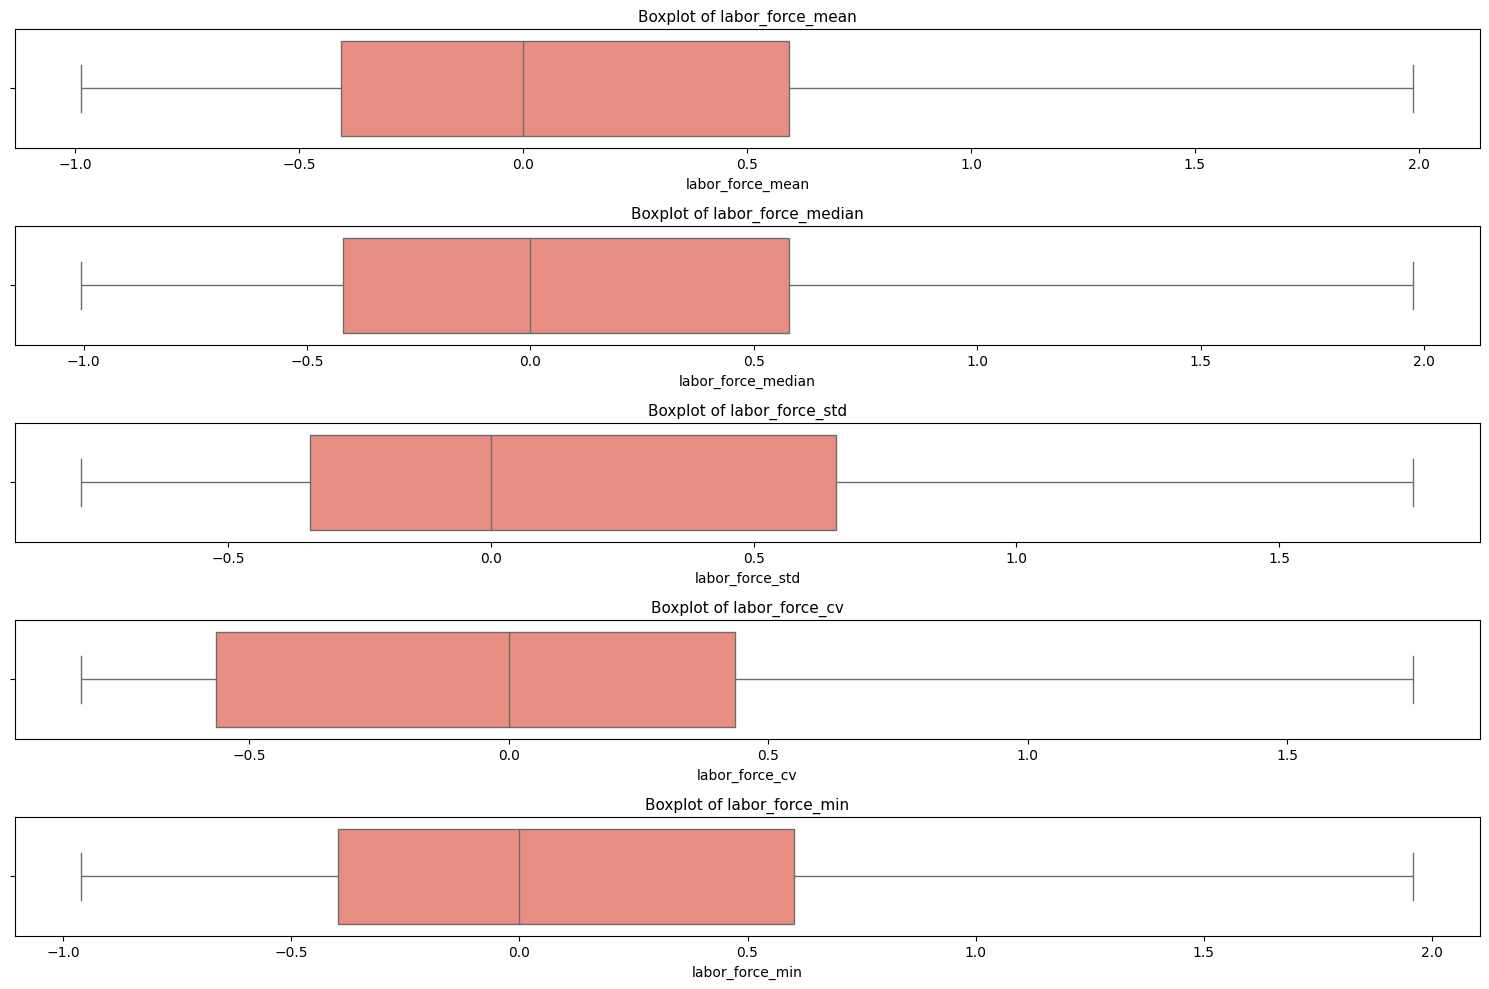

In [5]:
detect_top_outliers(one_point_countries)

### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [6]:
from sklearn.cluster import KMeans

In [7]:
cluster_input = one_point_countries.select_dtypes(include='number')
cluster_input.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,labor_force_kurtosis,...,govermment_effective_df_median,govermment_effective_df_std,govermment_effective_df_cv,govermment_effective_df_min,govermment_effective_df_max,govermment_effective_df_last,govermment_effective_df_growth,govermment_effective_df_skew,govermment_effective_df_kurtosis,govermment_effective_df_trend
0,0.202714,0.192674,0.929680,0.455345,0.196401,0.214118,0.248345,0.595002,-0.164568,-0.083200,...,0.422131,-1.092997,-0.469587,0.470588,0.438596,0.444444,0.205169,-0.530109,1.086080,0.359290
1,-0.263867,-0.280144,-0.242138,-0.199662,-0.244957,-0.270228,-0.225042,0.000000,0.421480,0.247302,...,0.368852,-1.036062,-0.437277,0.420168,0.390351,0.311111,0.012190,0.243008,1.005727,0.137295
2,-0.220085,-0.235440,0.119635,0.202138,-0.208577,-0.222477,-0.178372,0.337755,-0.070855,-0.390215,...,0.118852,0.487044,0.341810,0.109244,0.271930,0.037037,-0.509433,1.131808,0.331708,-0.610656
3,1.179330,1.176606,0.015253,-0.667595,1.171130,1.172479,1.184118,-0.496031,-0.713469,-0.214476,...,-1.229508,0.599653,-0.475061,-1.260504,-1.157895,-1.140741,1.775536,0.718709,-0.693295,-0.620219
4,-0.406877,-0.419765,0.044058,0.435465,-0.396049,-0.411877,-0.396650,-1.459119,-1.040194,1.395050,...,-0.778689,0.792616,-0.475061,-0.991597,-0.807018,-0.696296,-0.742611,-1.367699,0.396286,-0.262295


#### Using the elbow method to find the optimal number of clusters

In [8]:
import time

In [9]:
distortions = []
# Parameters
n_init_list = [10, 20]
max_iter_list = [200, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


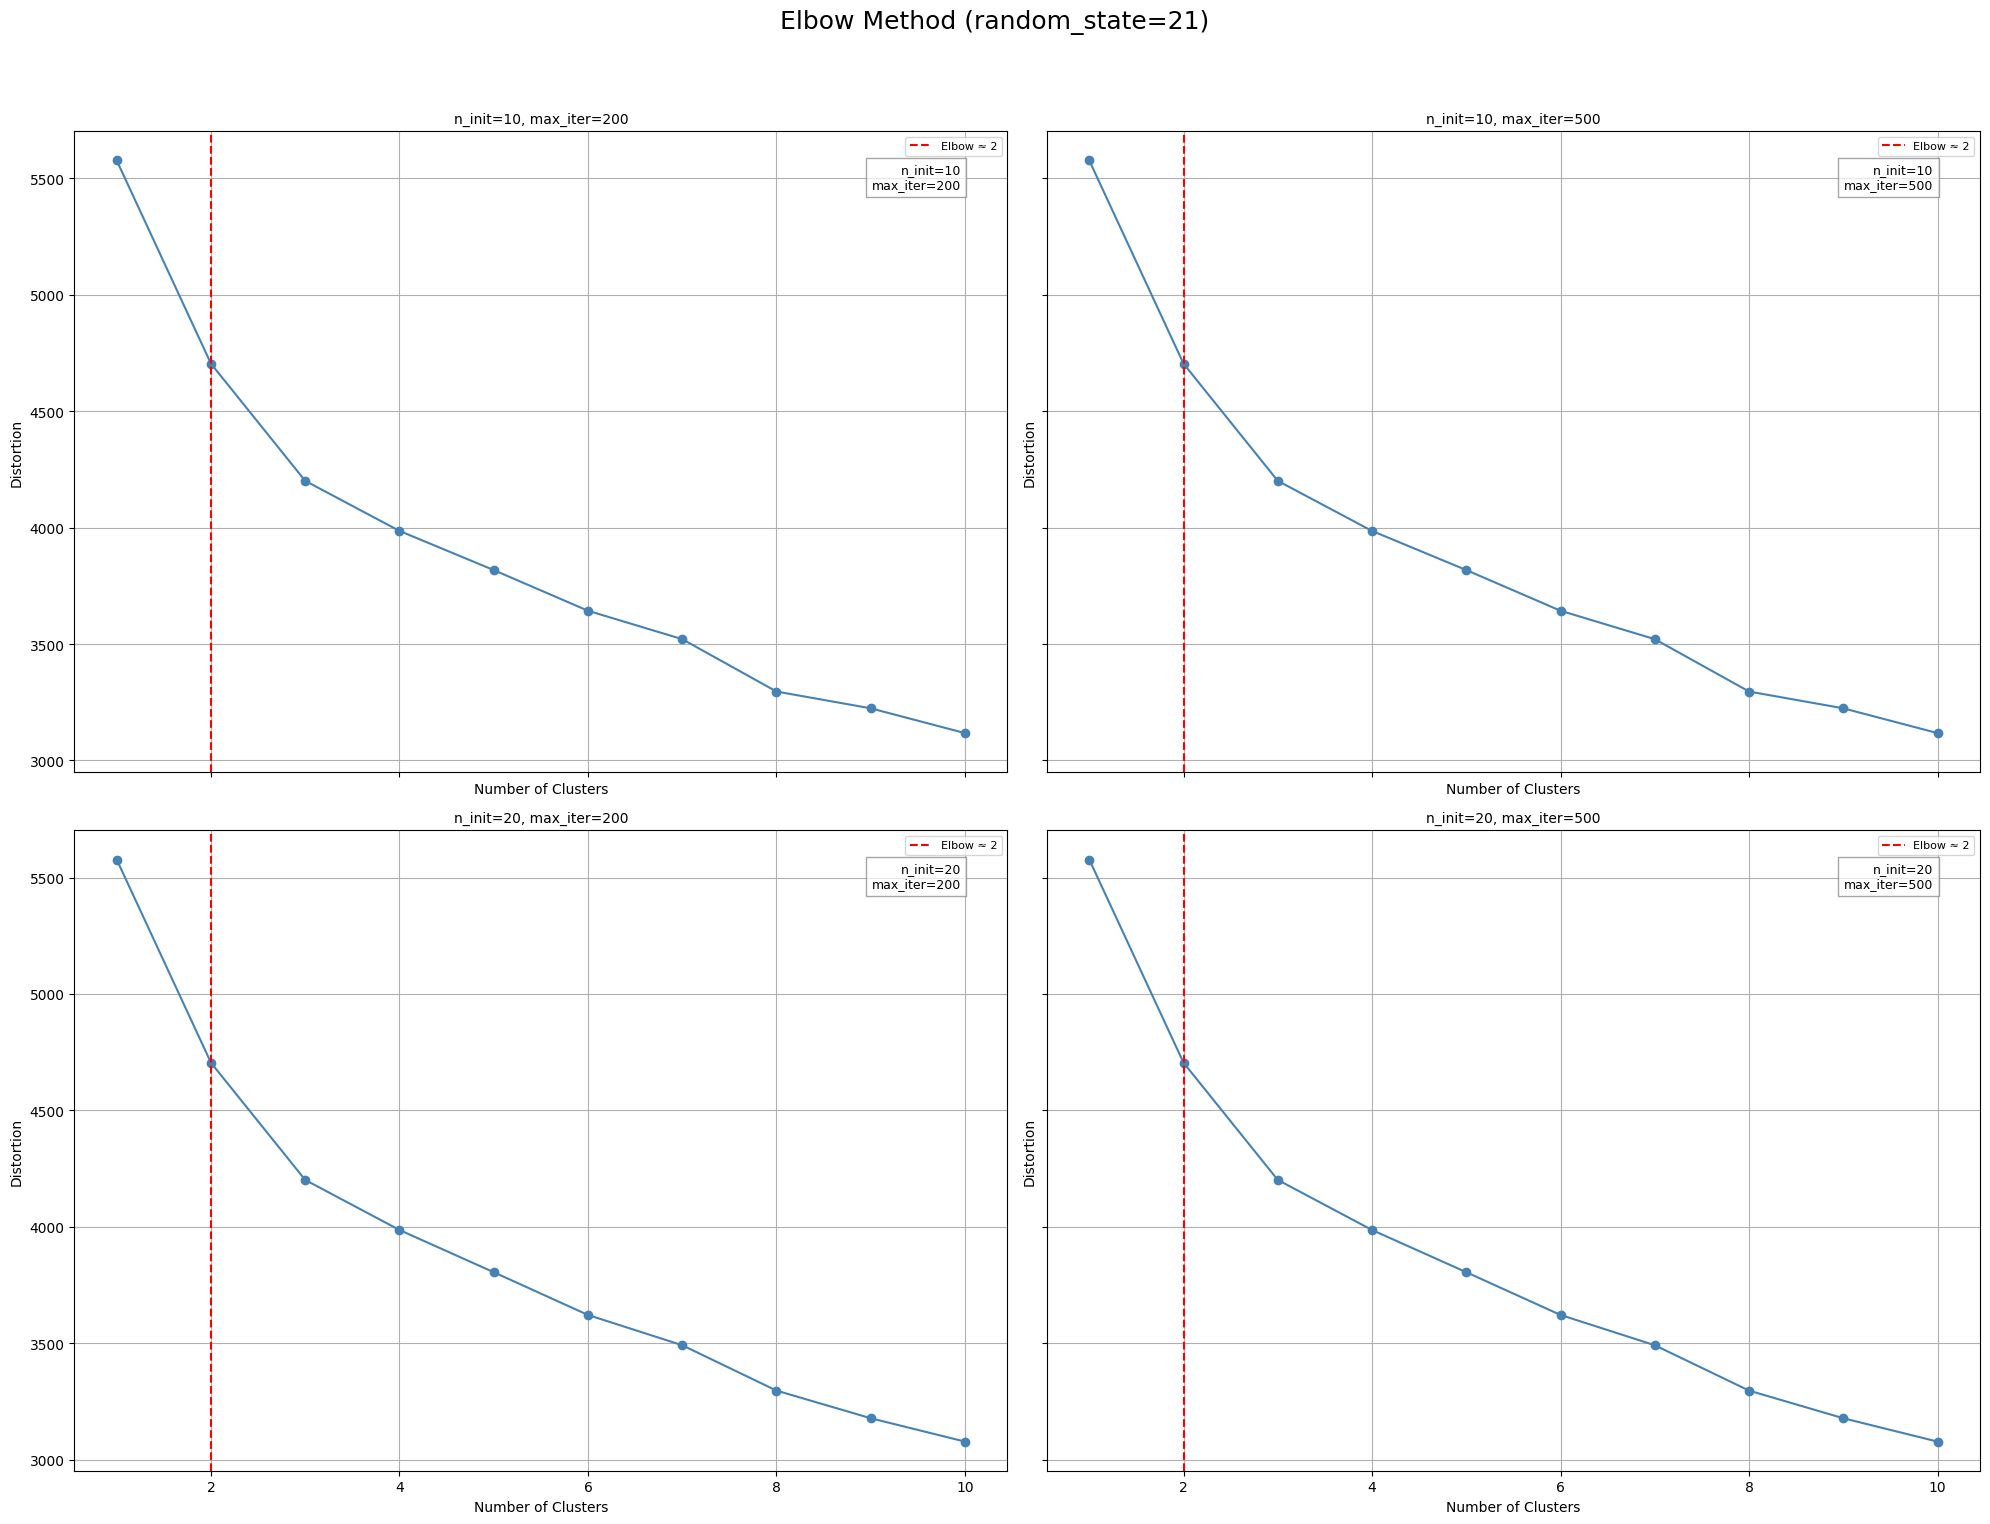


Running elbow plots for random_state=42


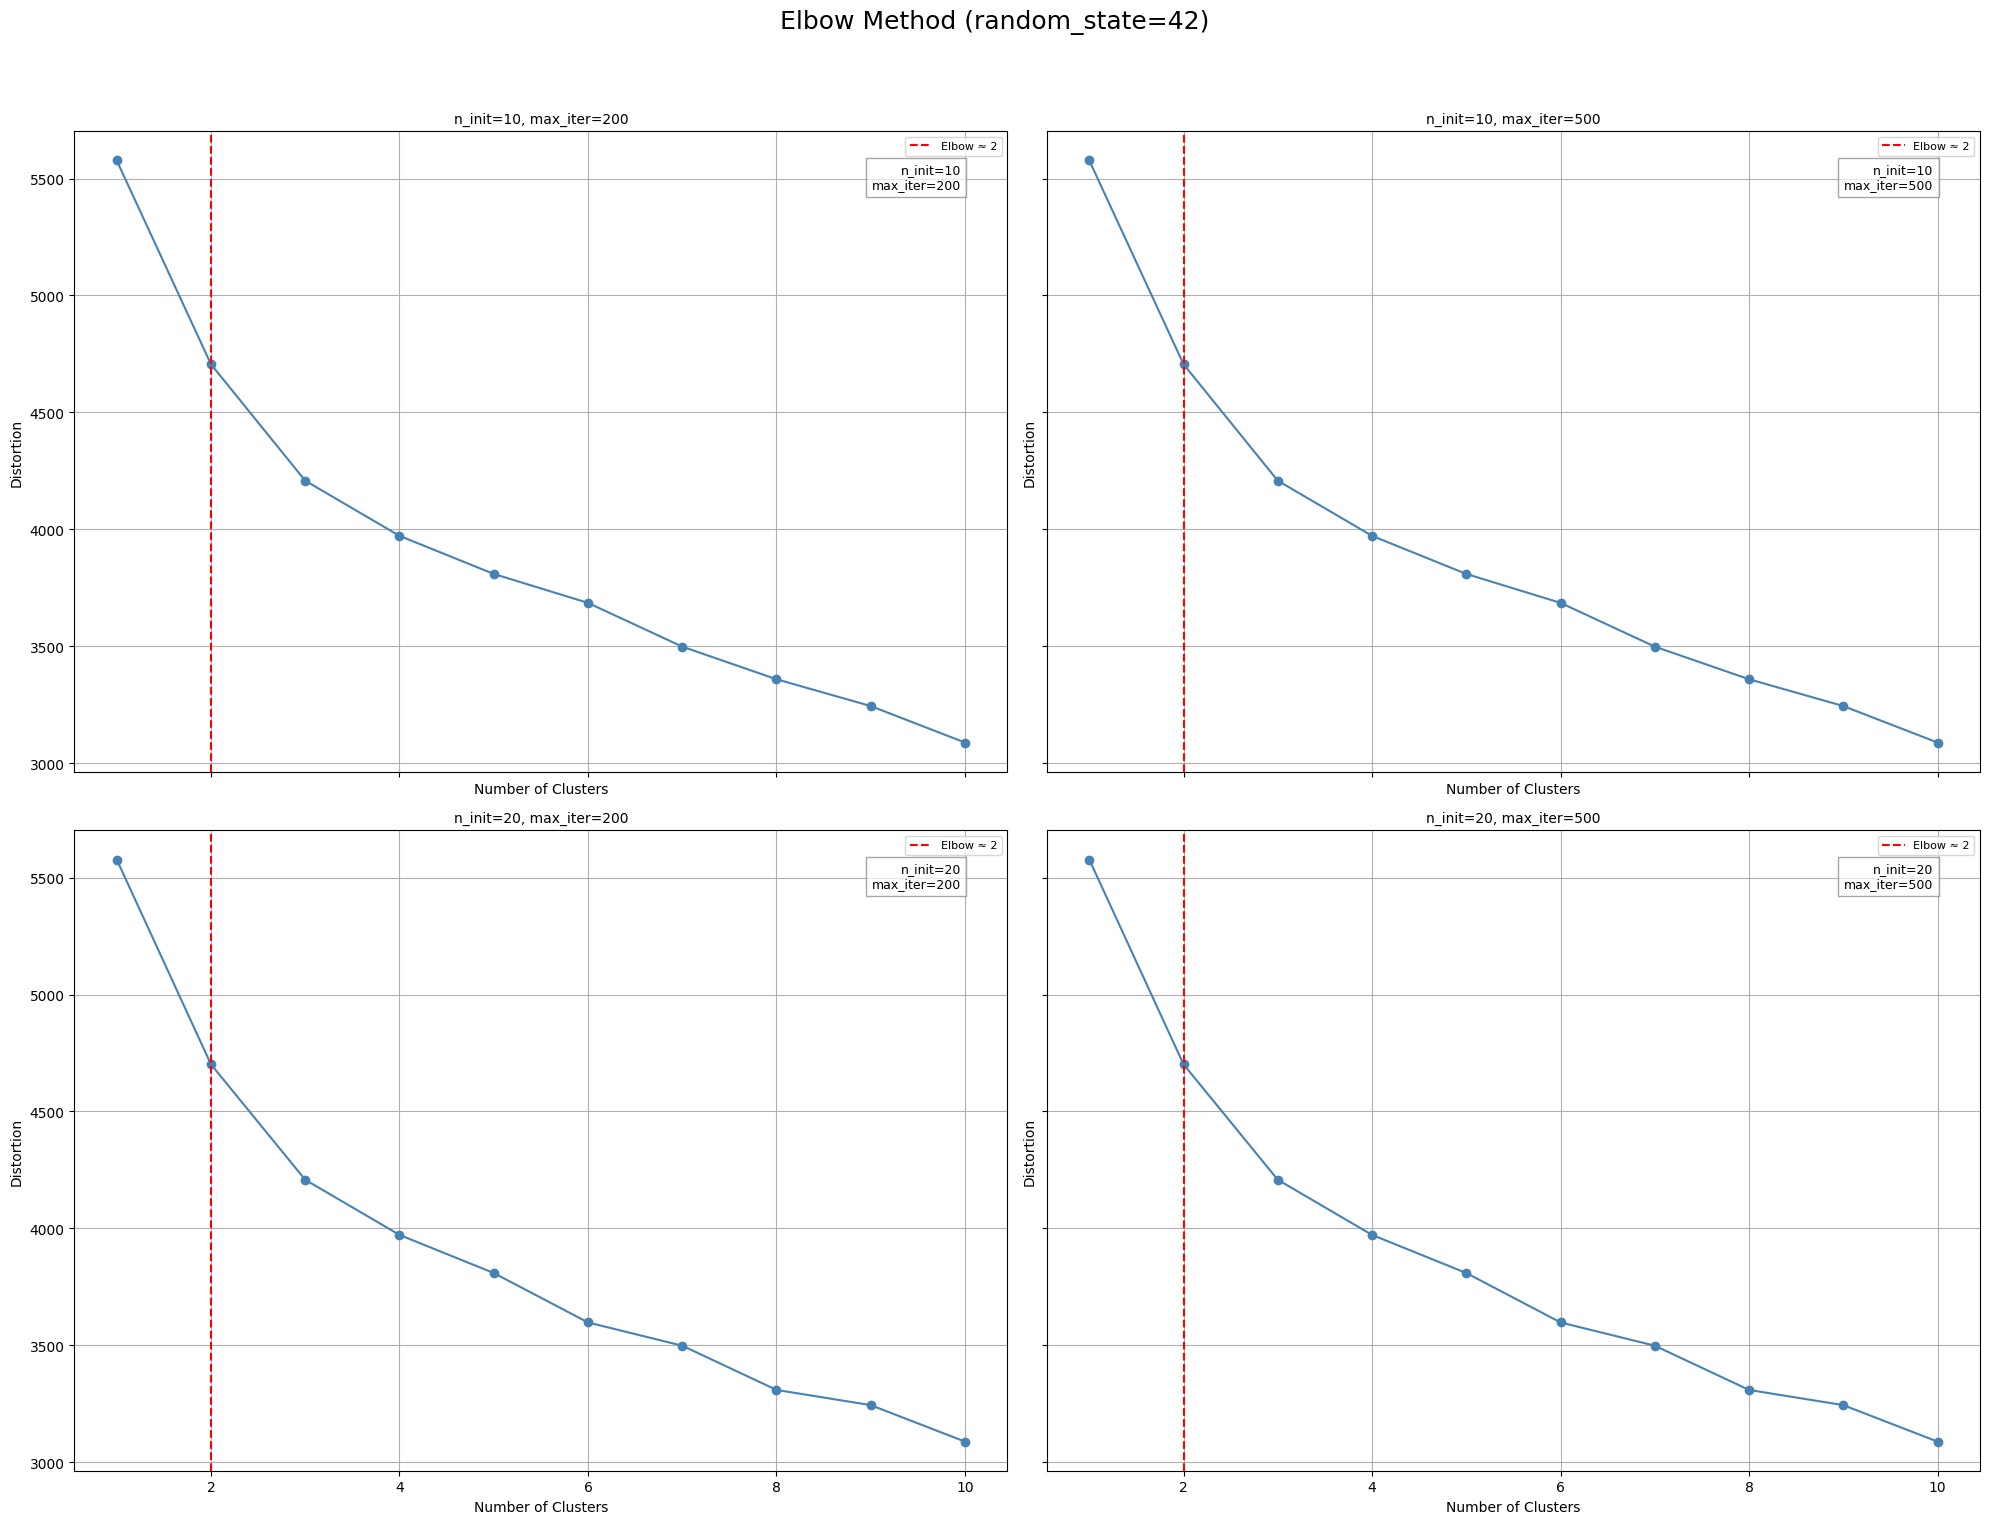


Total execution time: 6.85 seconds


In [10]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [9]:
from sklearn.metrics import silhouette_samples
from matplotlib import cm

In [10]:
import country_converter as coco

In [11]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [12]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

#### c2_ni20_maxi500

In [13]:
km_c2_ni20_maxi500 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [14]:
ym_c2_ni20_maxi500 = km_c2_ni20_maxi500.fit(cluster_input)

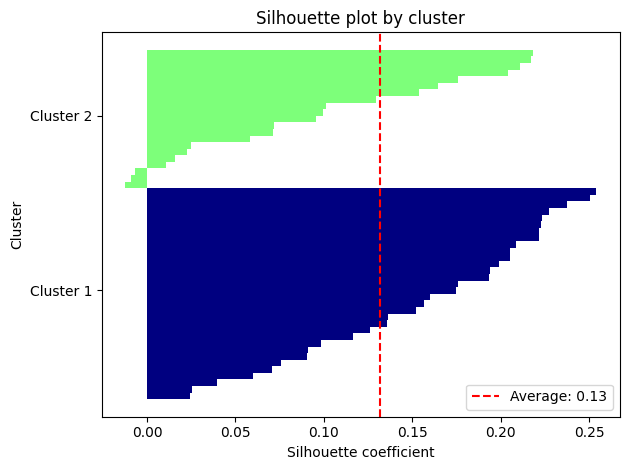

In [15]:
silhouette_c2_ni20_maxi500 = plot_silhouette(ym_c2_ni20_maxi500, cluster_input)

In [16]:
c2_ni20_maxi500_clusters = one_point_countries.copy()

In [17]:
c2_ni20_maxi500_clusters['cluster'] = ym_c2_ni20_maxi500.labels_

In [18]:
manual_corrections = {
    "South_Korea": "South Korea",
    "South_Africa": "South Africa",
    "United_Kingdom": "United Kingdom",
    "Czech_Republic": "Czechia",
    "New_Zealand": "New Zealand"
    # Agregá más si encontrás otros casos
}

In [19]:
c2_ni20_maxi500_clusters["Country"] = c2_ni20_maxi500_clusters["Country"].replace(manual_corrections)

# Ahora sí, convertir usando coco
c2_ni20_maxi500_clusters["ISO_A3"] = coco.convert(names=c2_ni20_maxi500_clusters["Country"], to="ISO3")
c2_ni20_maxi500_clusters["Continent"] = coco.convert(names=c2_ni20_maxi500_clusters["Country"], to="continent")


In [20]:
c2_ni20_maxi500_clusters[['Country', 'cluster', 'ISO_A3', 'Continent']]

,Country,cluster,ISO_A3,Continent
0,Australia,0,AUS,Oceania
1,Austria,0,AUT,Europe
2,Belgium,0,BEL,Europe
3,Brazil,1,BRA,America
4,Bulgaria,0,BGR,Europe
5,Canada,1,CAN,America
6,Chile,1,CHL,America
7,Colombia,1,COL,America
8,Croatia,0,HRV,Europe
9,Cyprus,0,CYP,Asia


In [21]:
print_cluster_groups(c2_ni20_maxi500_clusters)


🌍 Cluster 0 (32 countries):
 - Australia (Oceania)
 - Austria (Europe)
 - Belgium (Europe)
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Denmark (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - France (Europe)
 - Germany (Europe)
 - Greece (Europe)
 - Iceland (Europe)
 - Ireland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Poland (Europe)
 - Portugal (Europe)
 - Romania (Europe)
 - Singapore (Asia)
 - Slovakia (Europe)
 - Slovenia (Europe)
 - Spain (Europe)
 - Sweden (Europe)
 - Switzerland (Europe)
 - United Kingdom (Europe)

🌍 Cluster 1 (21 countries):
 - Brazil (America)
 - Canada (America)
 - Chile (America)
 - Colombia (America)
 - Czechia (Europe)
 - Hungary (Europe)
 - India (Asia)
 - Japan (Asia)
 - Malaysia (Asia)
 - Mexico (America)
 - Norway (Europe)
 - Paraguay (America)
 - Peru (America)
 - Philippines (Asia)
 - Russia (Eur

#### c6_ni20_maxi500

In [22]:
km_c6_ni20_maxi500 = KMeans(n_clusters=6,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [23]:
ym_c6_ni20_maxi500 = km_c6_ni20_maxi500.fit(cluster_input)

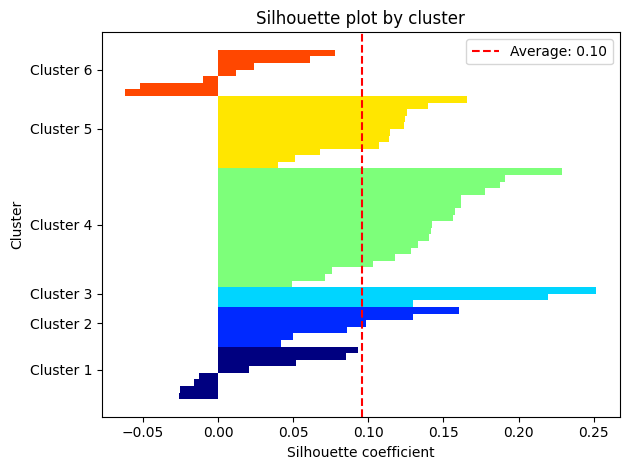

In [24]:
silhouette_c6_ni20_maxi500 = plot_silhouette(ym_c6_ni20_maxi500, cluster_input)

In [25]:
c6_ni20_maxi500_clusters = one_point_countries.copy()

In [26]:
c6_ni20_maxi500_clusters['cluster'] = ym_c6_ni20_maxi500.labels_

In [27]:
c6_ni20_maxi500_clusters["Country"] = c6_ni20_maxi500_clusters["Country"].replace(manual_corrections)

# Ahora sí, convertir usando coco
c6_ni20_maxi500_clusters["ISO_A3"] = coco.convert(names=c6_ni20_maxi500_clusters["Country"], to="ISO3")
c6_ni20_maxi500_clusters["Continent"] = coco.convert(names=c6_ni20_maxi500_clusters["Country"], to="continent")

In [28]:
c6_ni20_maxi500_clusters[['Country', 'cluster', 'ISO_A3', 'Continent']]

,Country,cluster,ISO_A3,Continent
0,Australia,3,AUS,Oceania
1,Austria,3,AUT,Europe
2,Belgium,3,BEL,Europe
3,Brazil,5,BRA,America
4,Bulgaria,4,BGR,Europe
5,Canada,5,CAN,America
6,Chile,2,CHL,America
7,Colombia,1,COL,America
8,Croatia,4,HRV,Europe
9,Cyprus,4,CYP,Asia


In [29]:
print_cluster_groups(c6_ni20_maxi500_clusters)


🌍 Cluster 0 (8 countries):
 - Czechia (Europe)
 - Hungary (Europe)
 - Ireland (Europe)
 - Philippines (Asia)
 - Poland (Europe)
 - Romania (Europe)
 - Serbia (Europe)
 - Thailand (Asia)

🌍 Cluster 1 (6 countries):
 - Colombia (America)
 - India (Asia)
 - Mexico (America)
 - Paraguay (America)
 - Russia (Europe)
 - Turkey (Asia)

🌍 Cluster 2 (3 countries):
 - Chile (America)
 - Japan (Asia)
 - South Korea (Asia)

🌍 Cluster 3 (18 countries):
 - Australia (Oceania)
 - Austria (Europe)
 - Belgium (Europe)
 - Denmark (Europe)
 - Finland (Europe)
 - France (Europe)
 - Germany (Europe)
 - Iceland (Europe)
 - Israel (Asia)
 - Italy (Europe)
 - Netherlands (Europe)
 - New Zealand (Oceania)
 - Portugal (Europe)
 - South Africa (Africa)
 - Spain (Europe)
 - Sweden (Europe)
 - Switzerland (Europe)
 - United Kingdom (Europe)

🌍 Cluster 4 (11 countries):
 - Bulgaria (Europe)
 - Croatia (Europe)
 - Cyprus (Asia)
 - Estonia (Europe)
 - Greece (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxem

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [30]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

In [31]:
df_hpi_winsorized.shape

(15, 53)

In [32]:
c2_ni20_maxi500_clusters.shape

(53, 191)

In [33]:
c6_ni20_maxi500_clusters.shape

(53, 191)

In [34]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

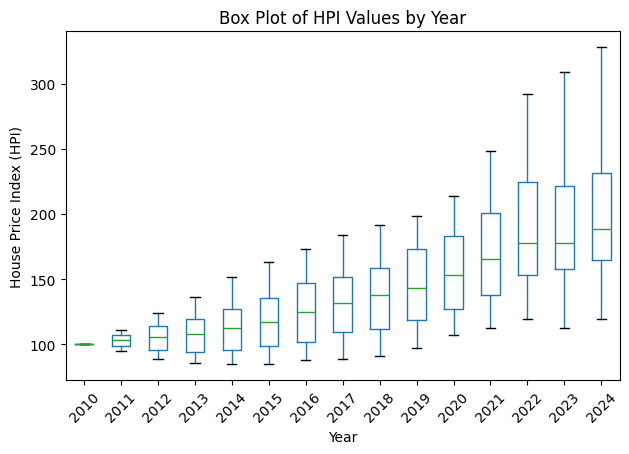

In [35]:
plot_hpi_boxplots_by_year(df_hpi_winsorized)

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [36]:
import random

In [37]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [38]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='cluster', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [39]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Cluster {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [40]:
def percentage_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                            cluster_column='cluster', country_column='Country',
                                            year_column='Year'):
    """
    Calcula el porcentaje de puntos de HPI que están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y porcentaje de puntos dentro del IQR como valor
    """
    cluster_iqr_percentages = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_percentages[cluster_id] = 0.0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0
        total_values = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count_within_iqr = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count_within_iqr
            total_values += len(values)

        # Calcular porcentaje
        percentage = (total_within_iqr / total_values * 100) if total_values > 0 else 0.0
        cluster_iqr_percentages[cluster_id] = round(percentage, 2)

    return cluster_iqr_percentages

In [41]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [42]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Experiment c2

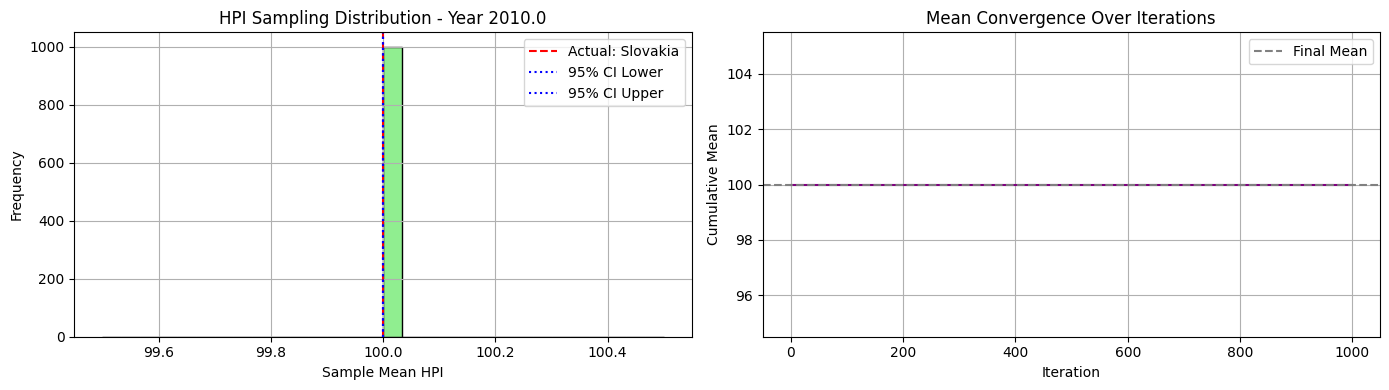

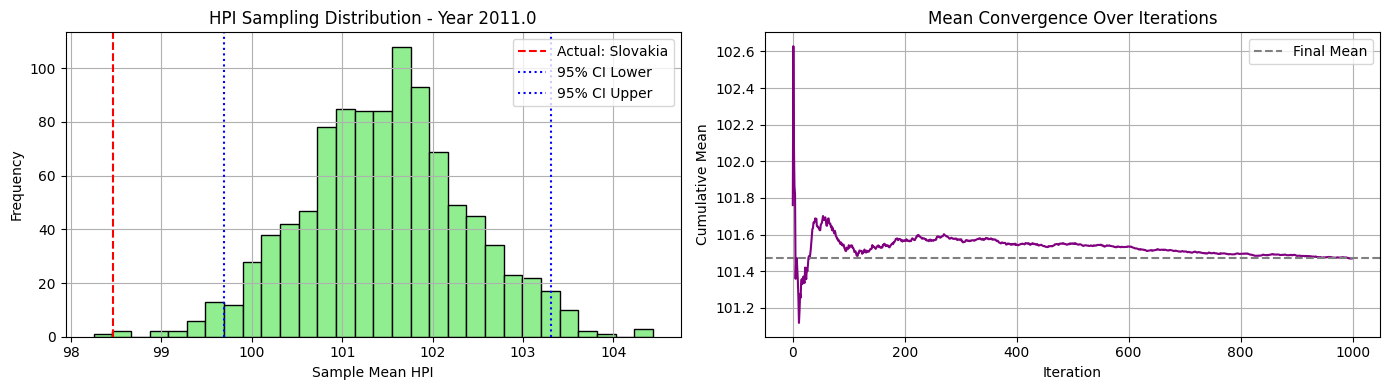

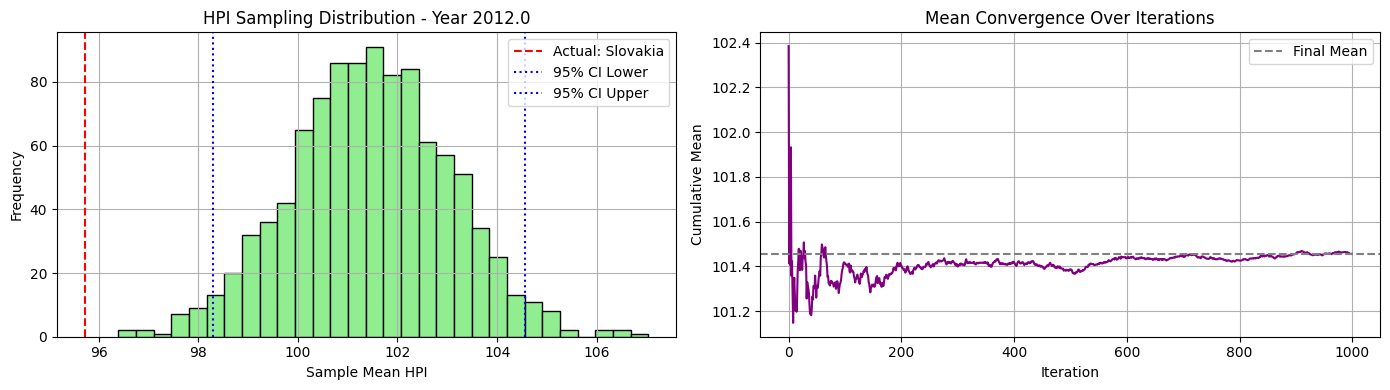

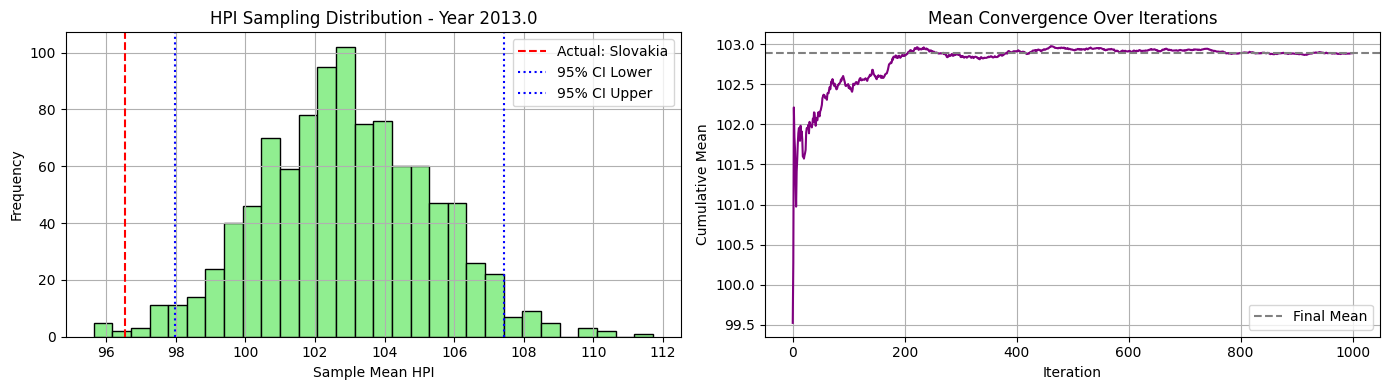

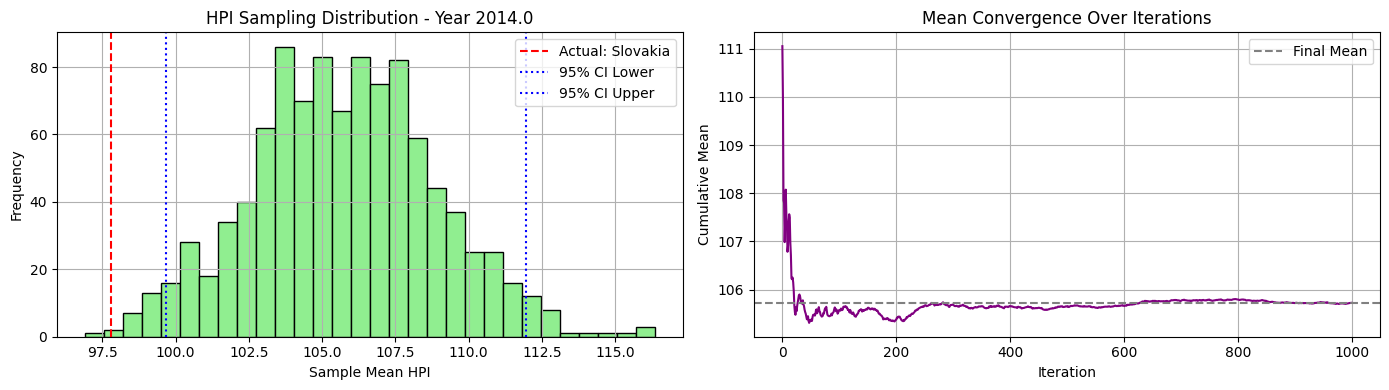

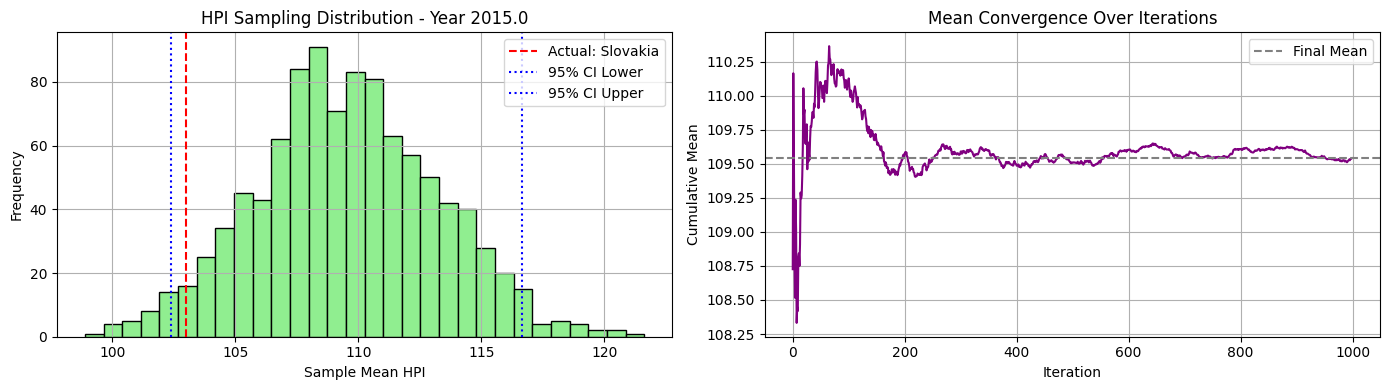

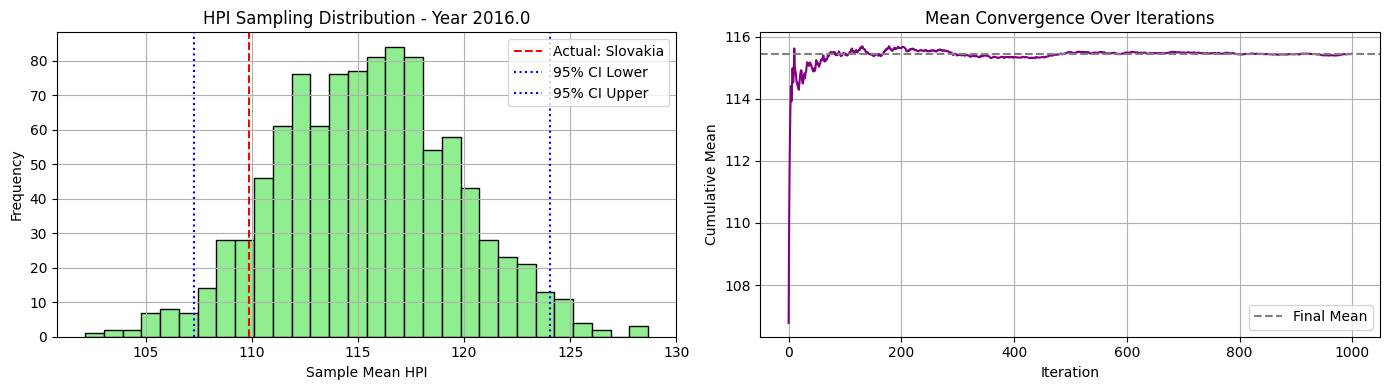

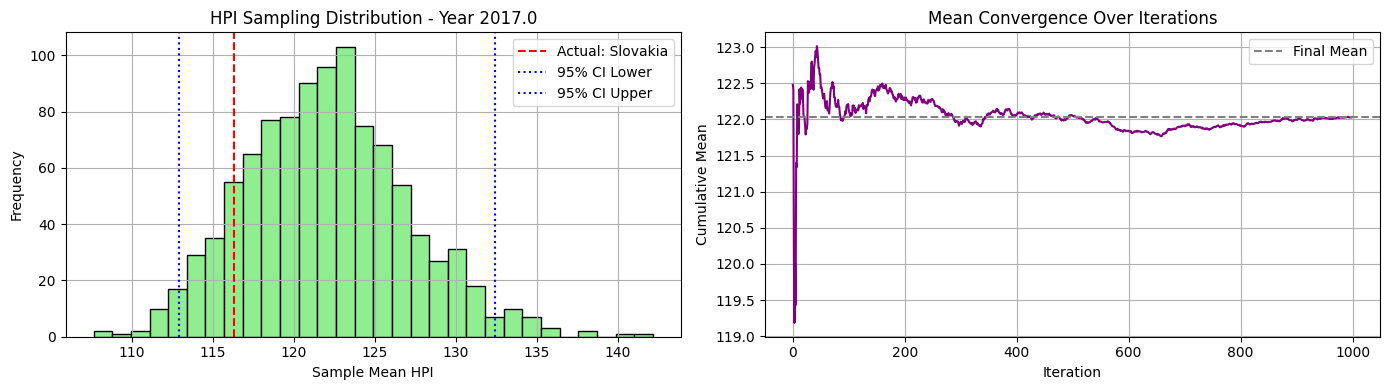

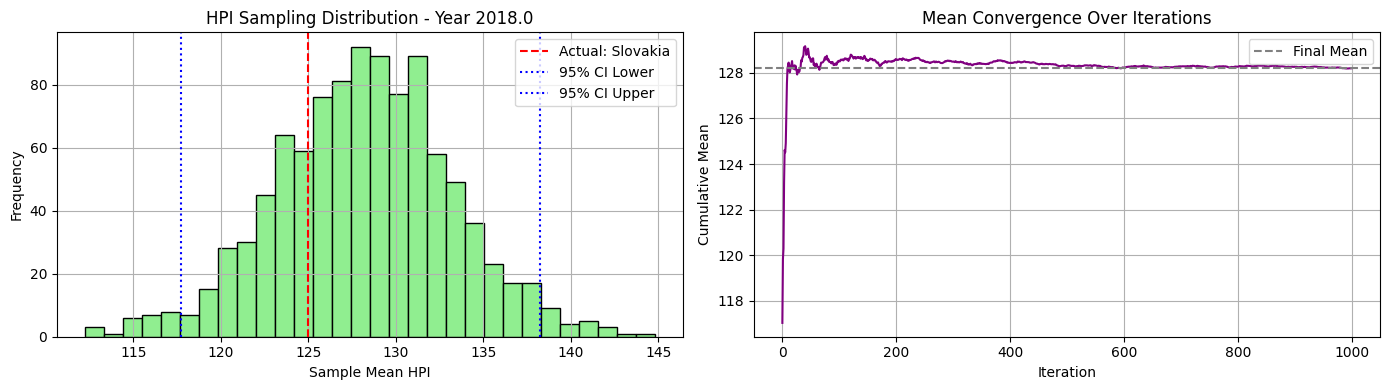

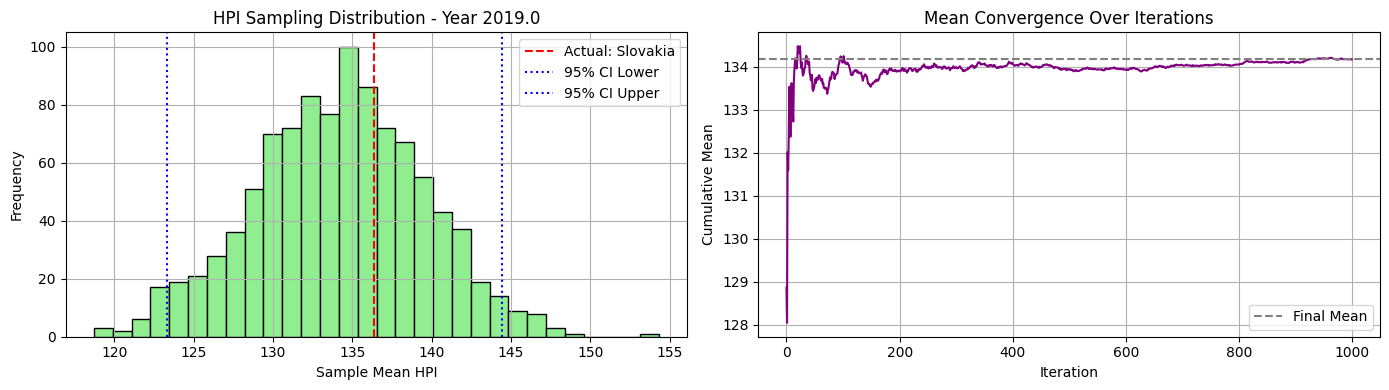

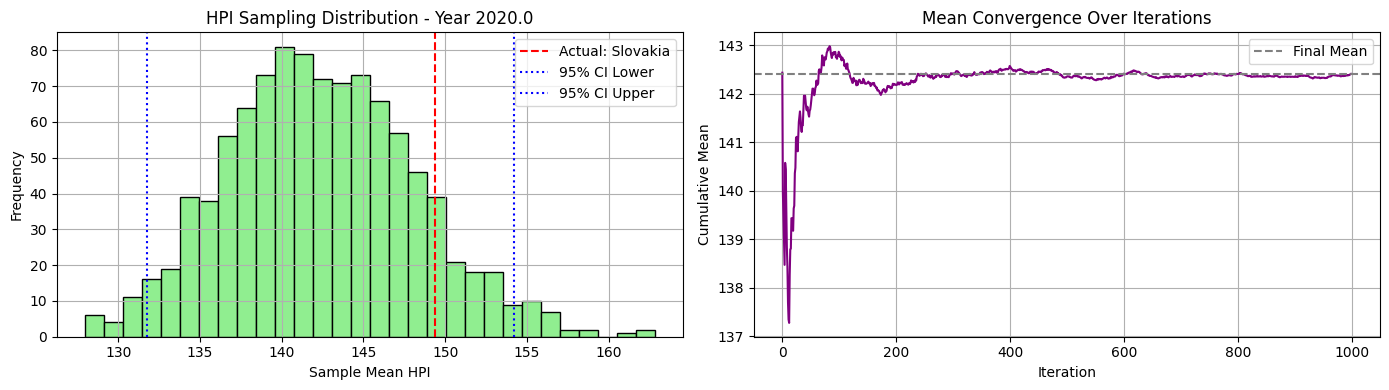

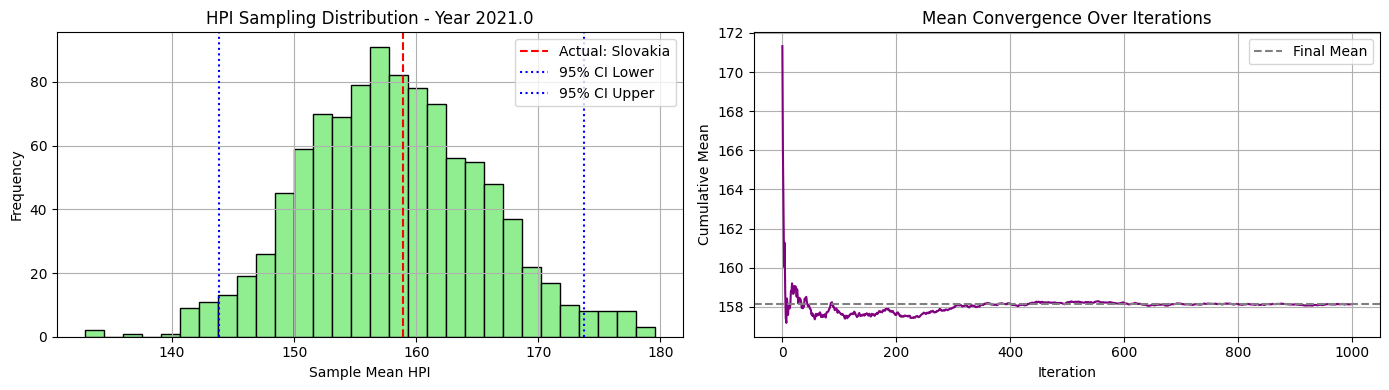

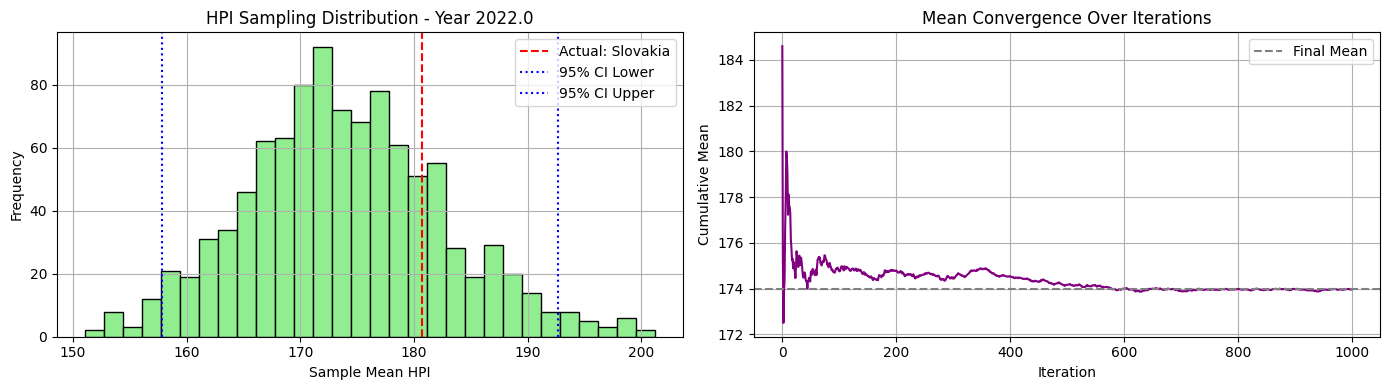

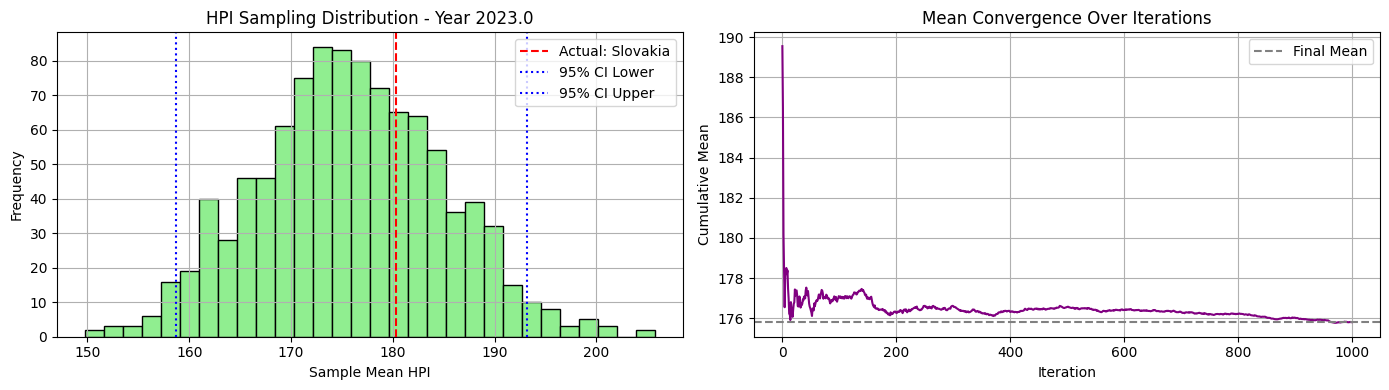

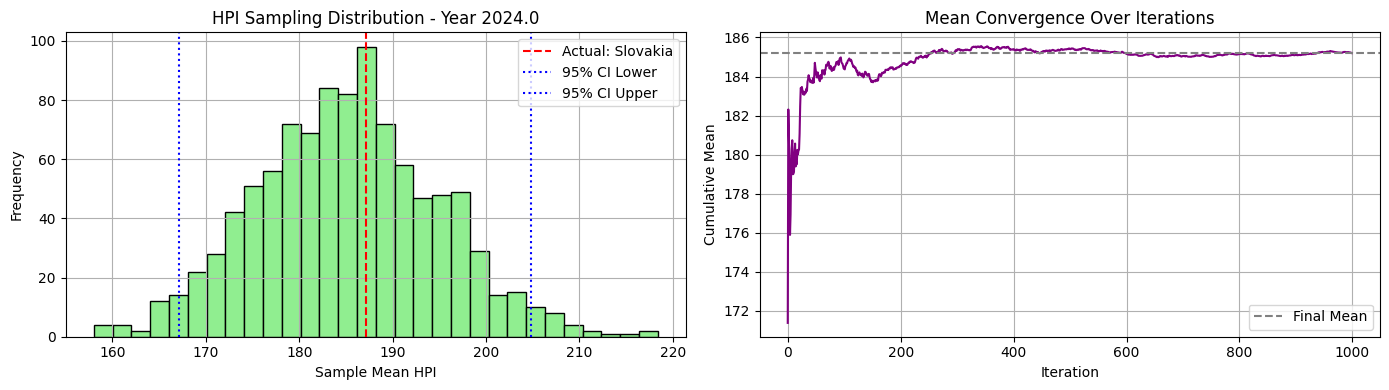

In [43]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c2_ni20_maxi500_clusters, cluster_id=0)

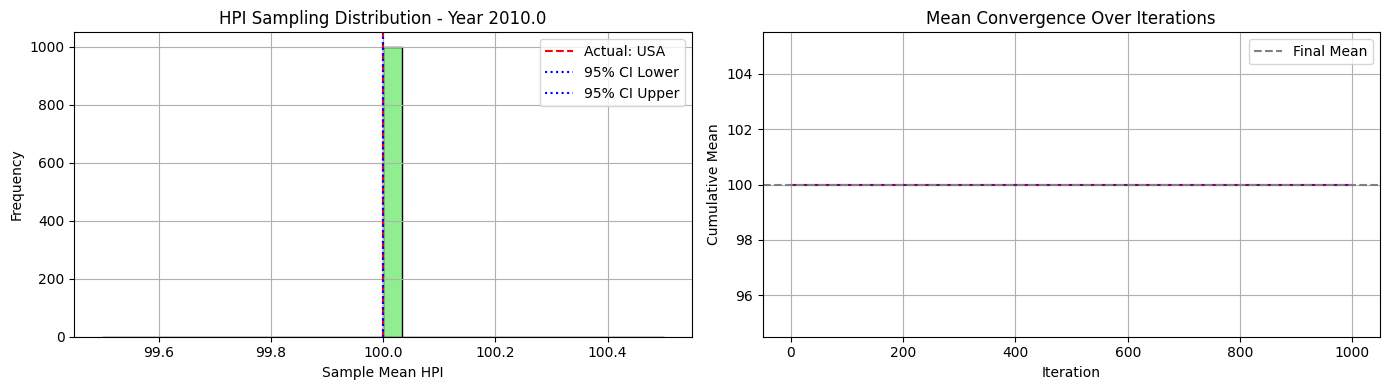

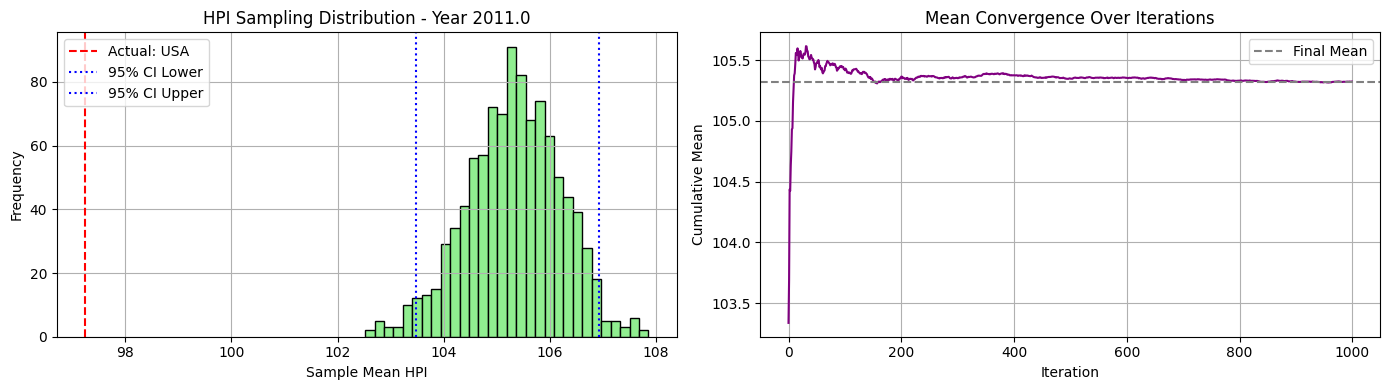

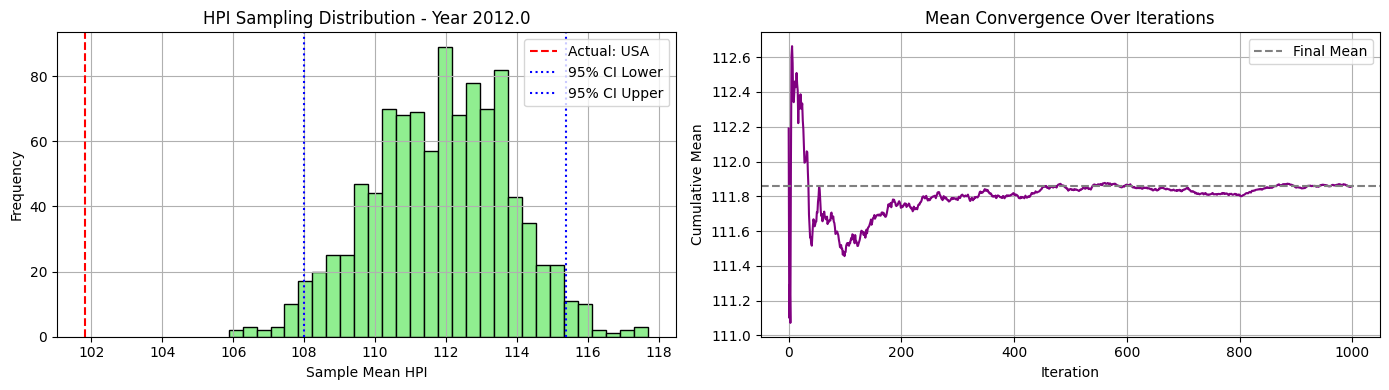

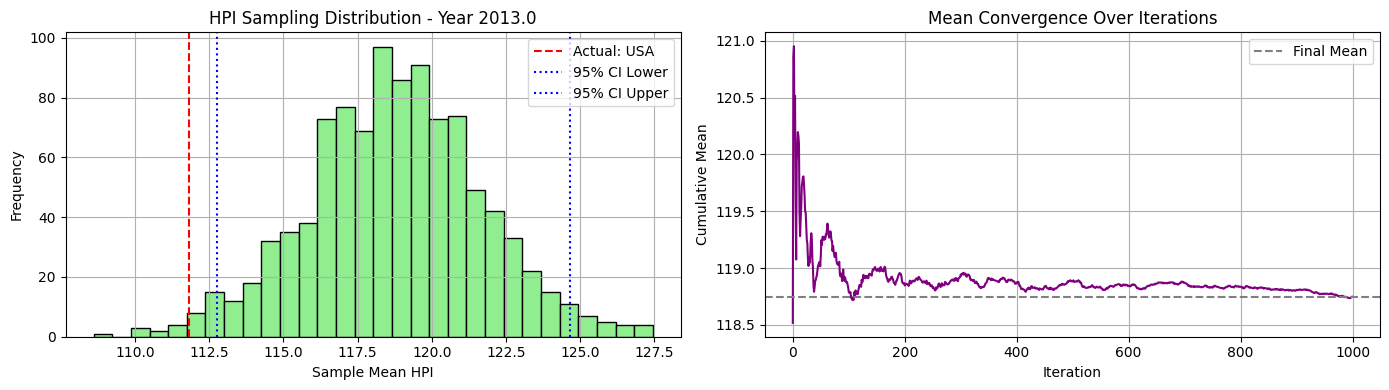

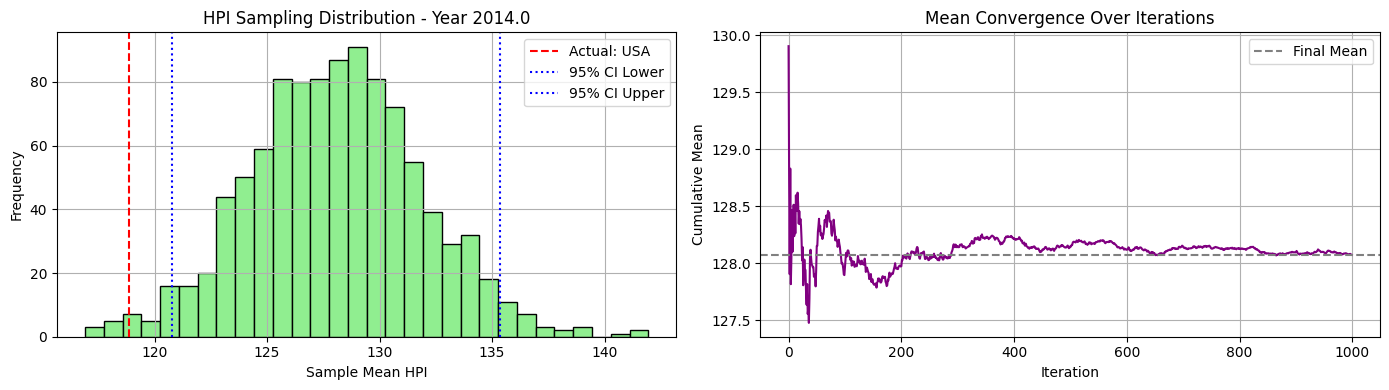

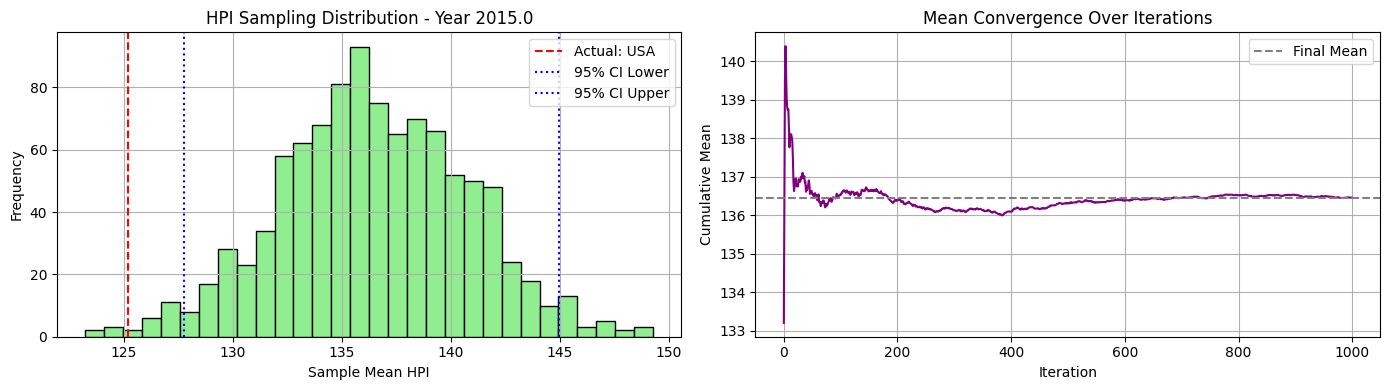

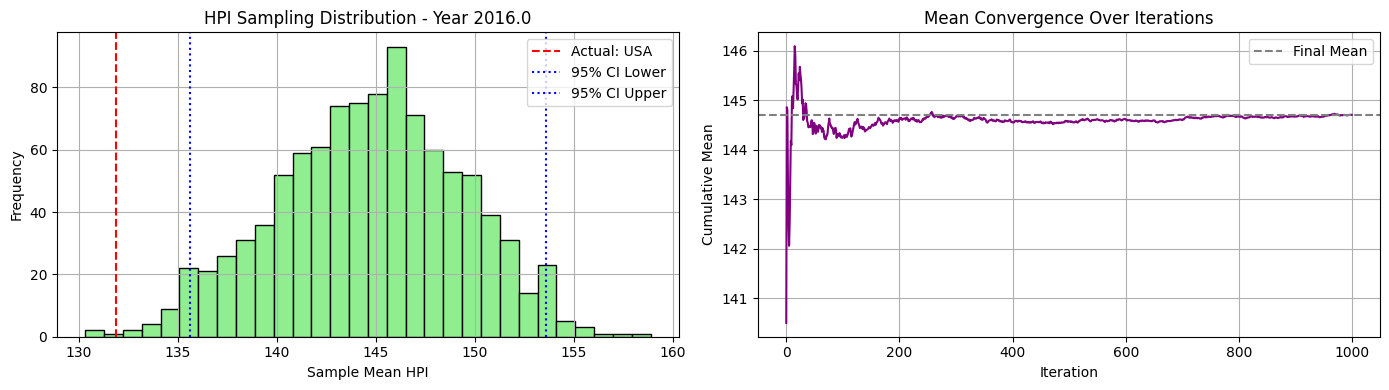

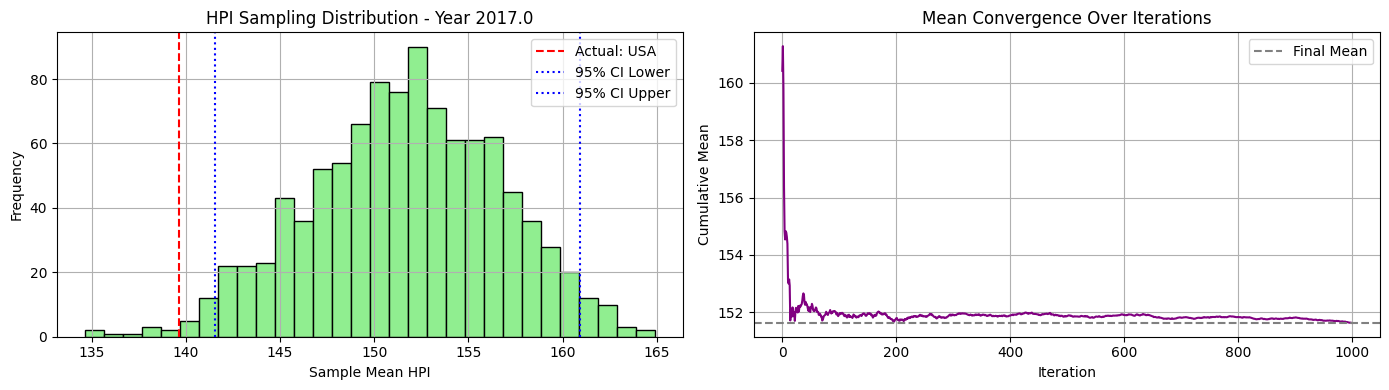

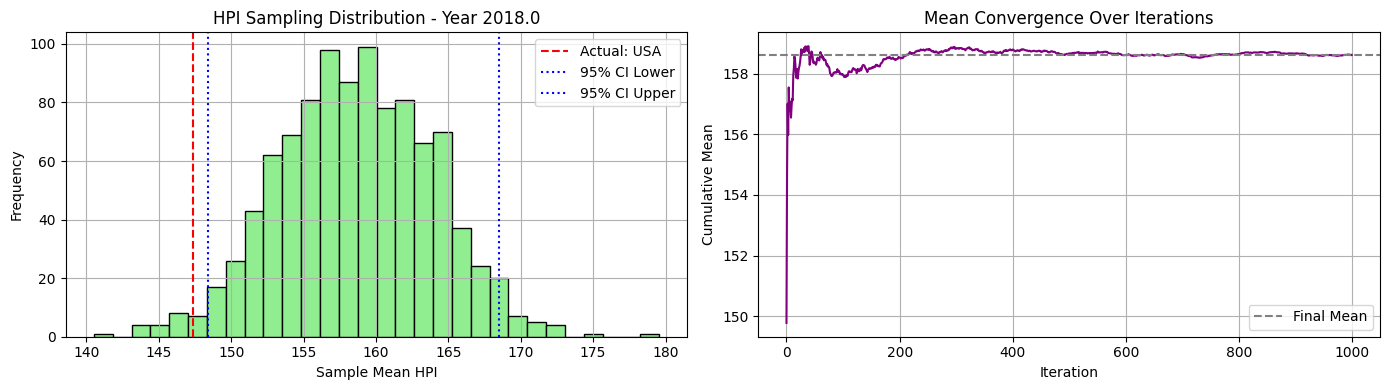

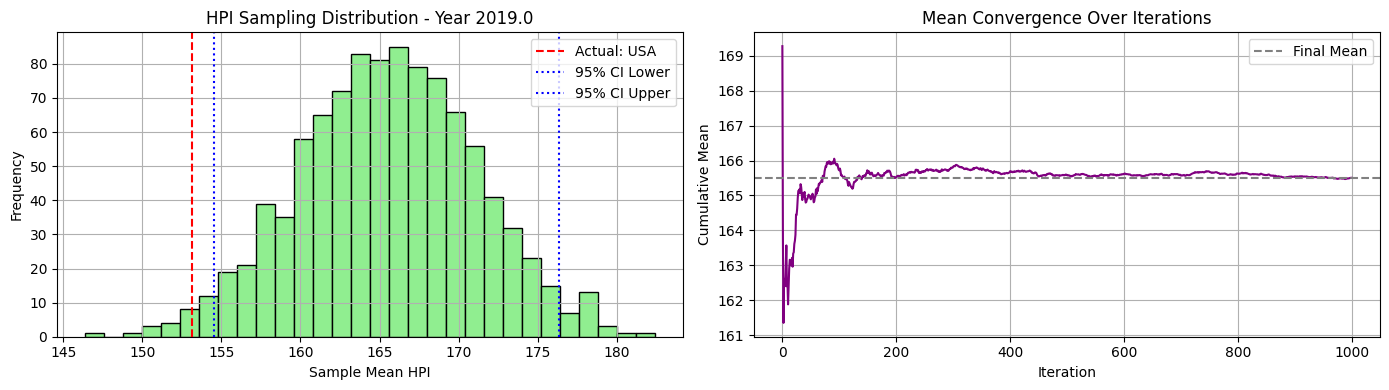

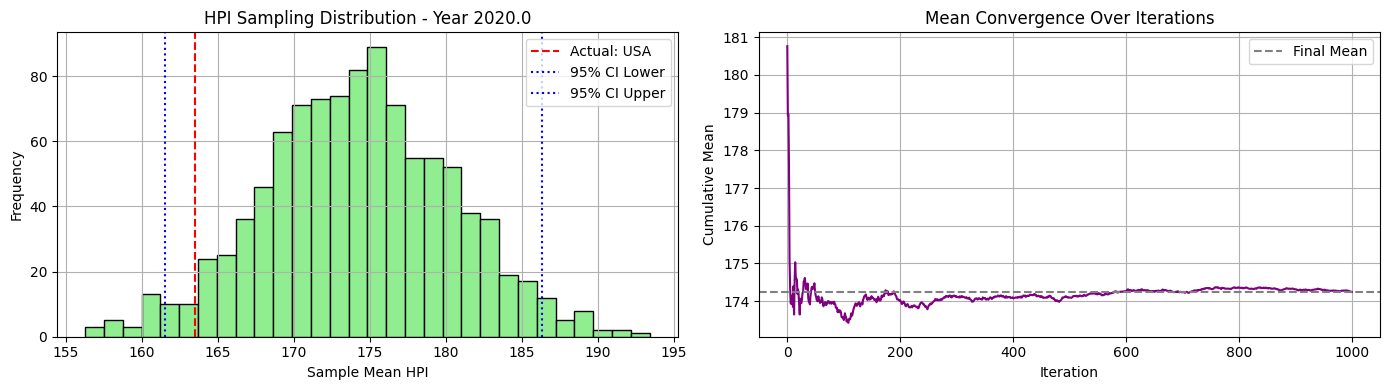

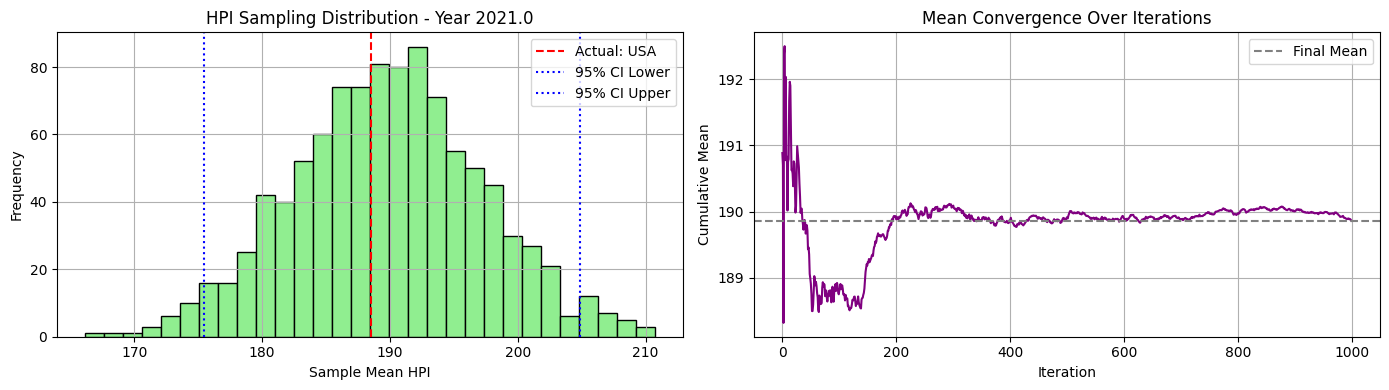

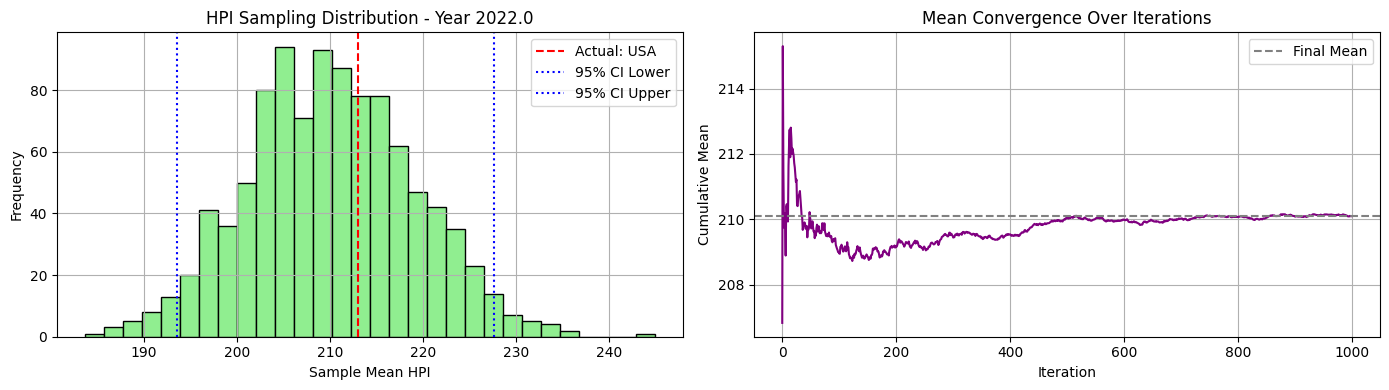

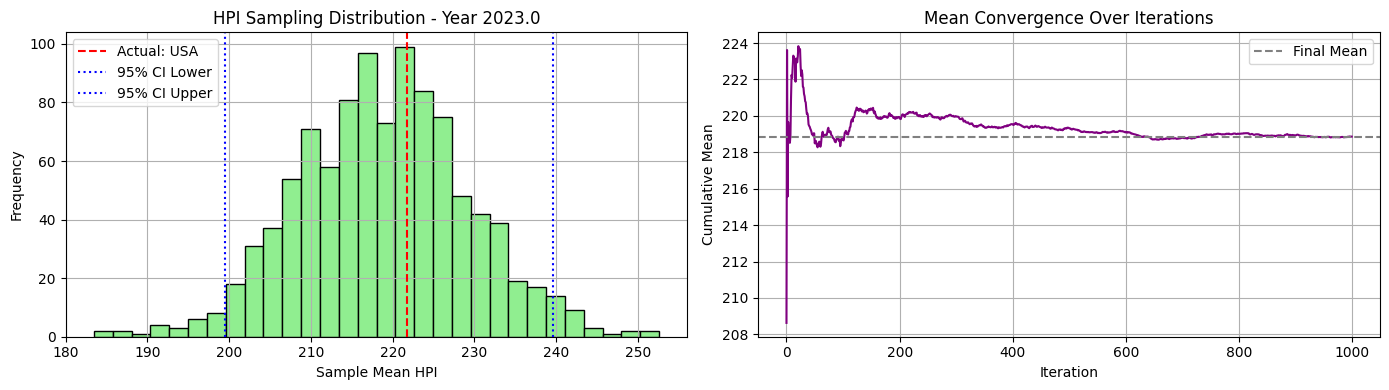

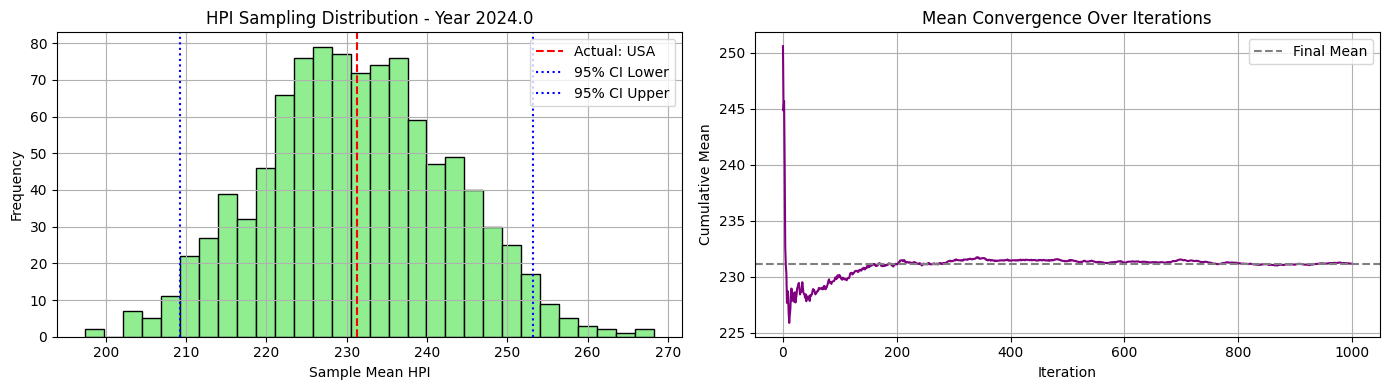

In [44]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c2_ni20_maxi500_clusters, cluster_id=1)

### Experiment c6

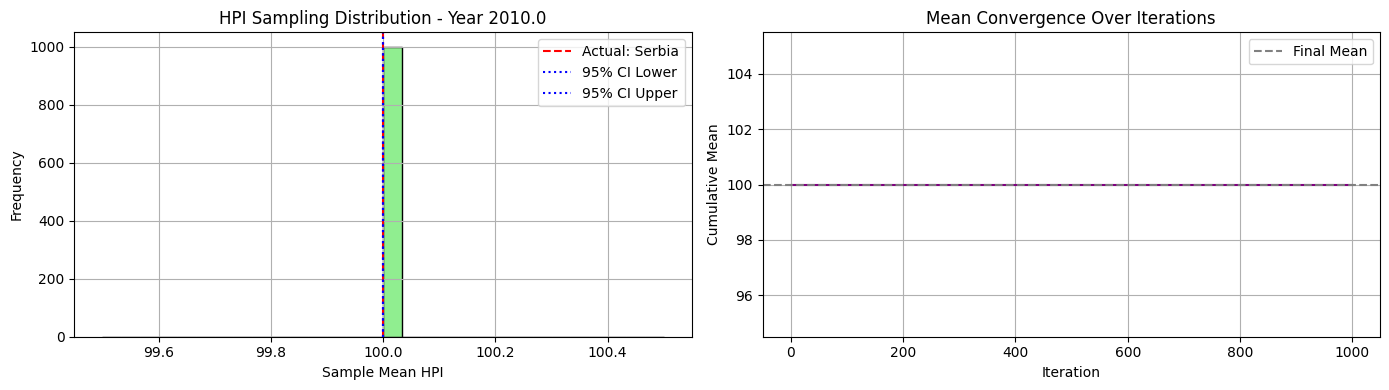

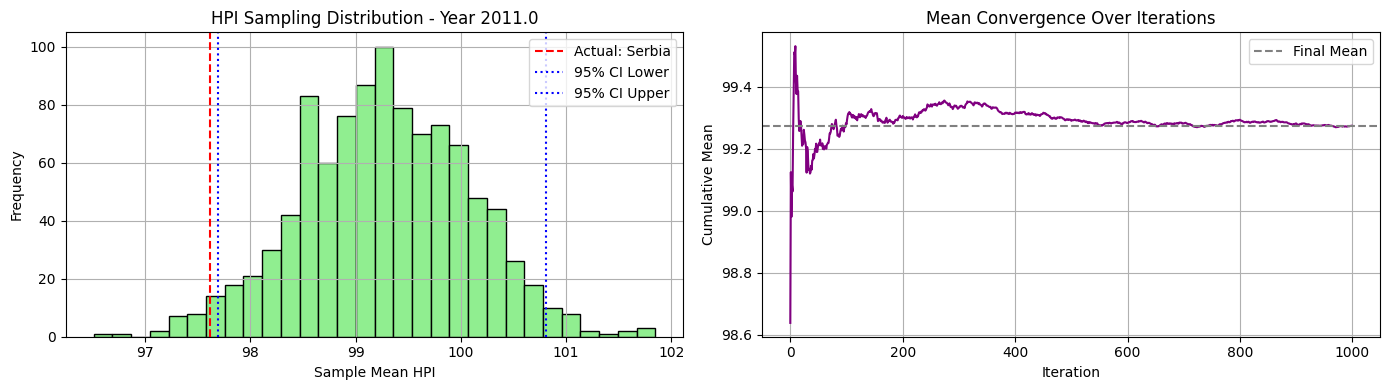

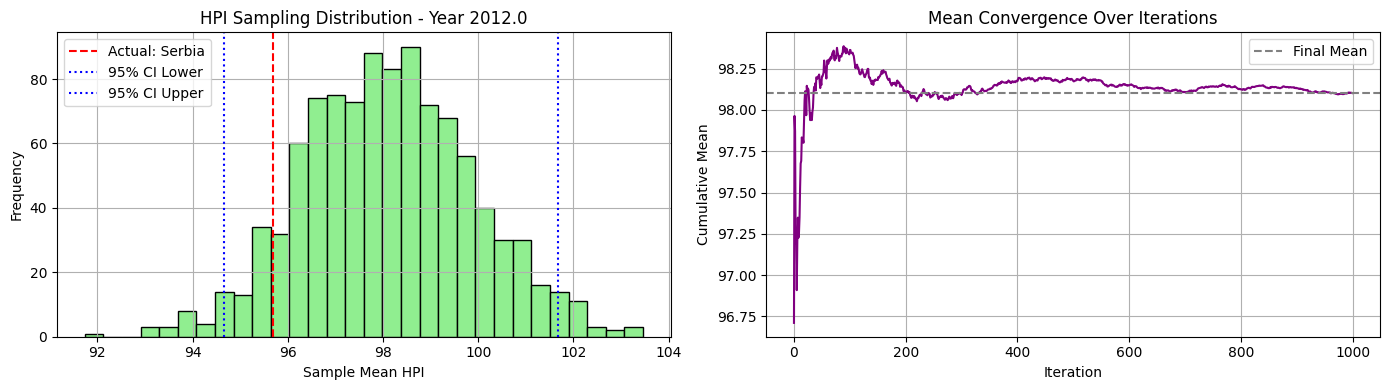

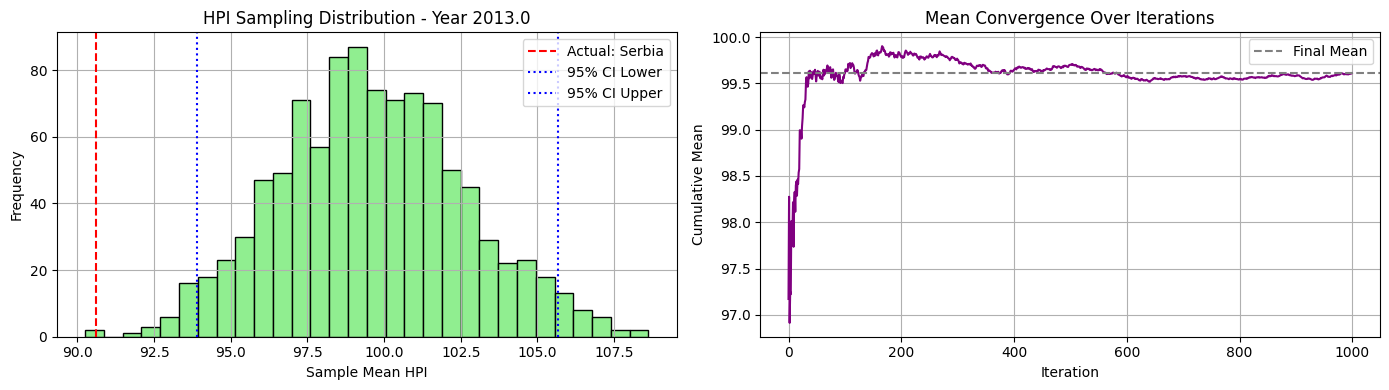

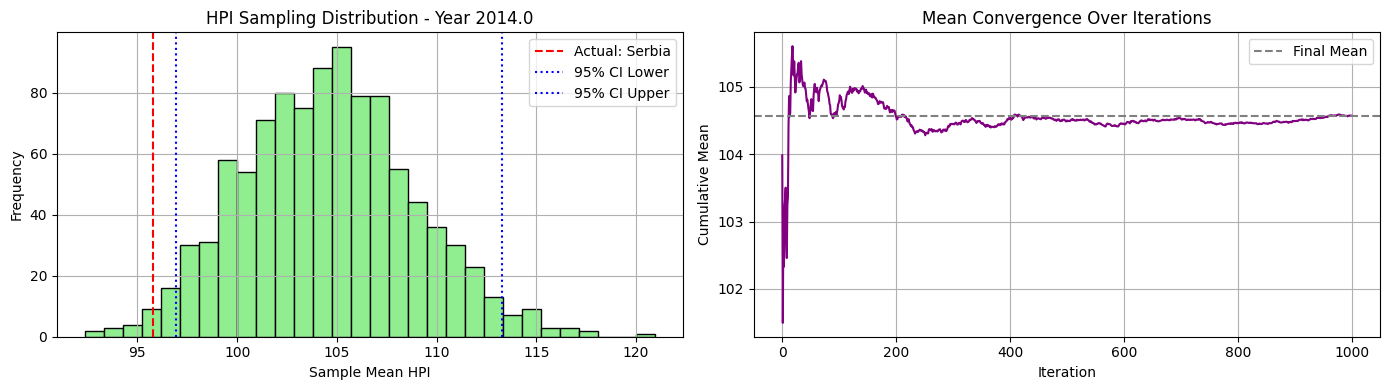

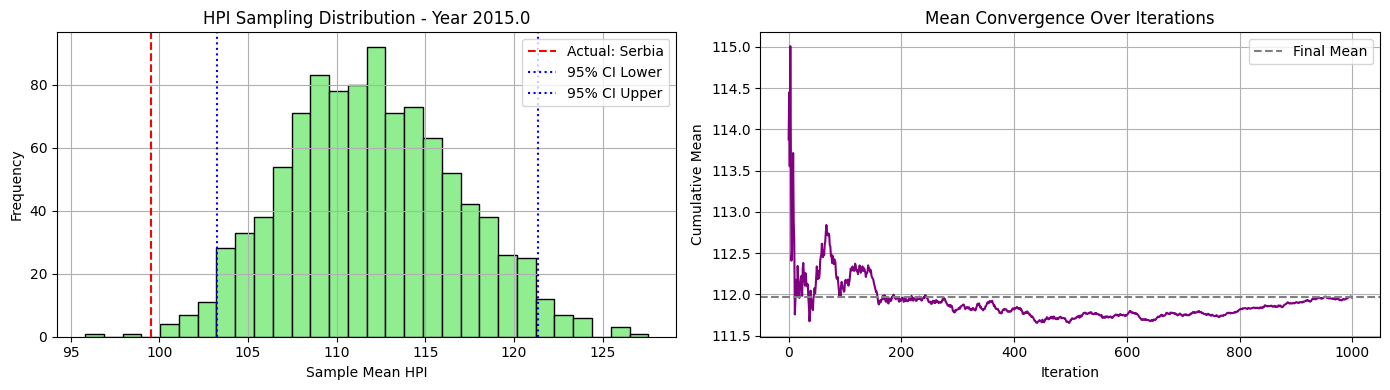

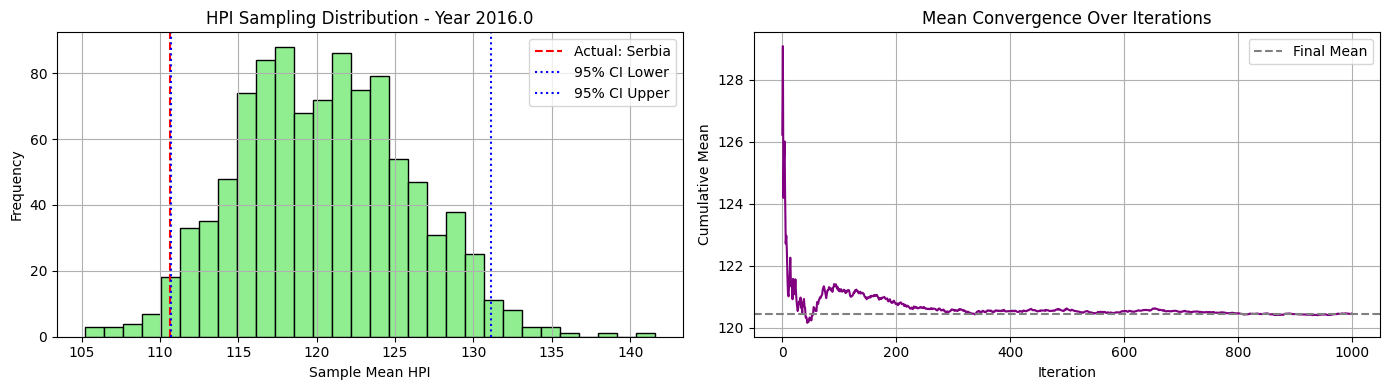

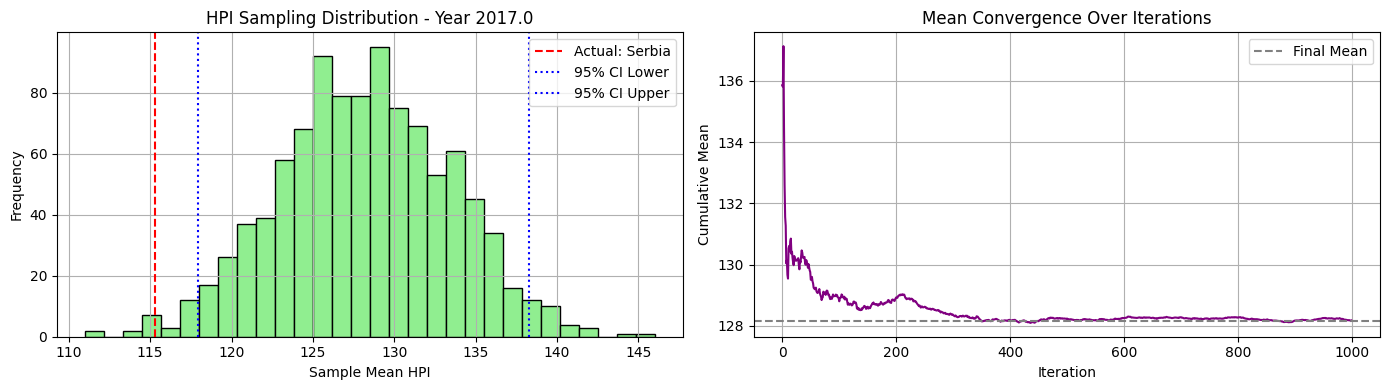

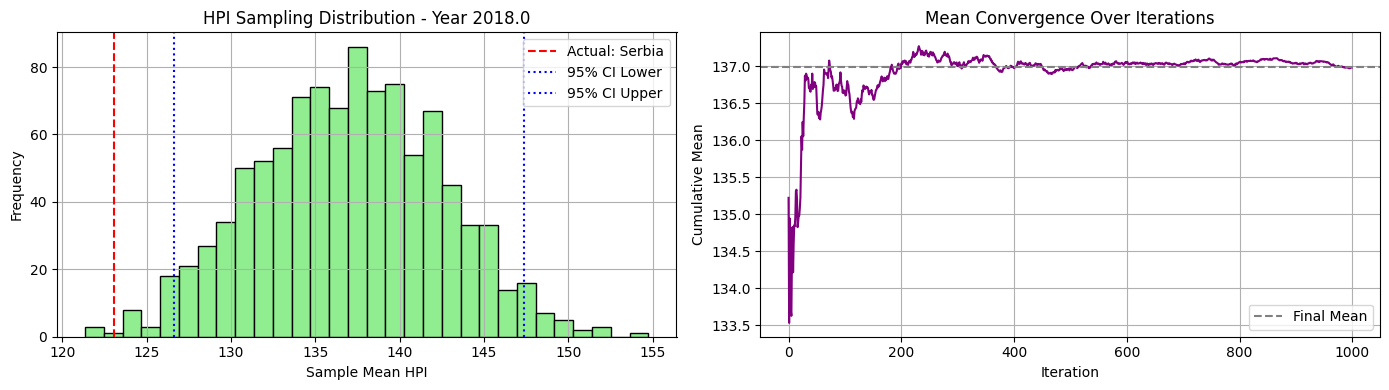

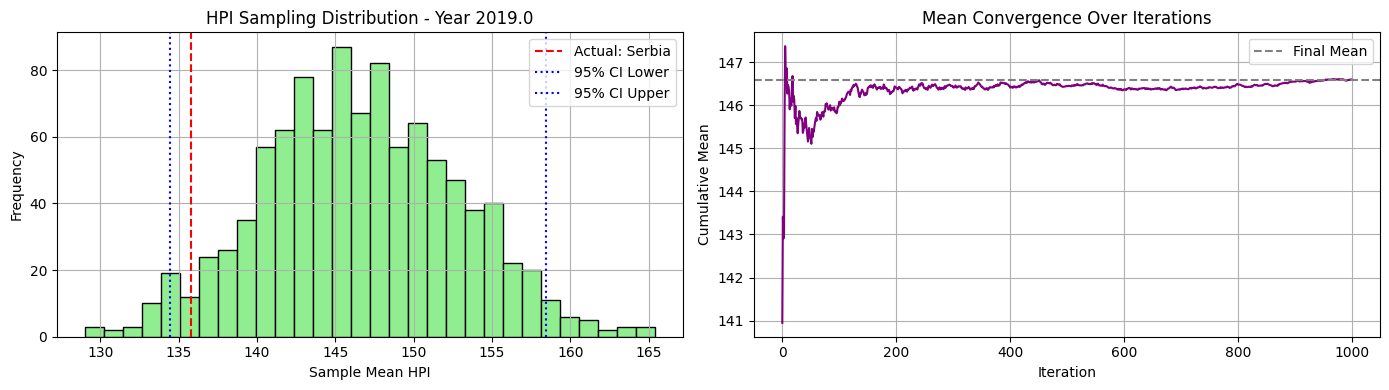

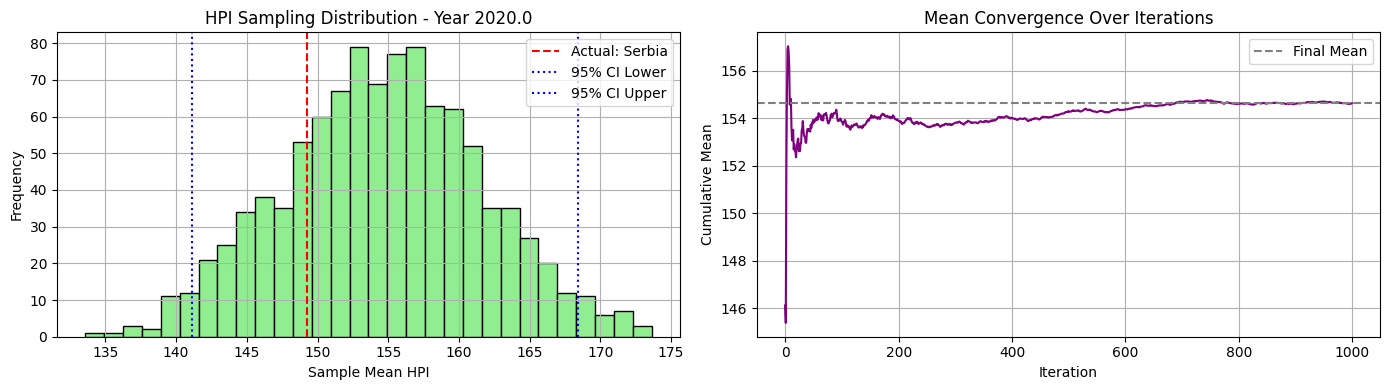

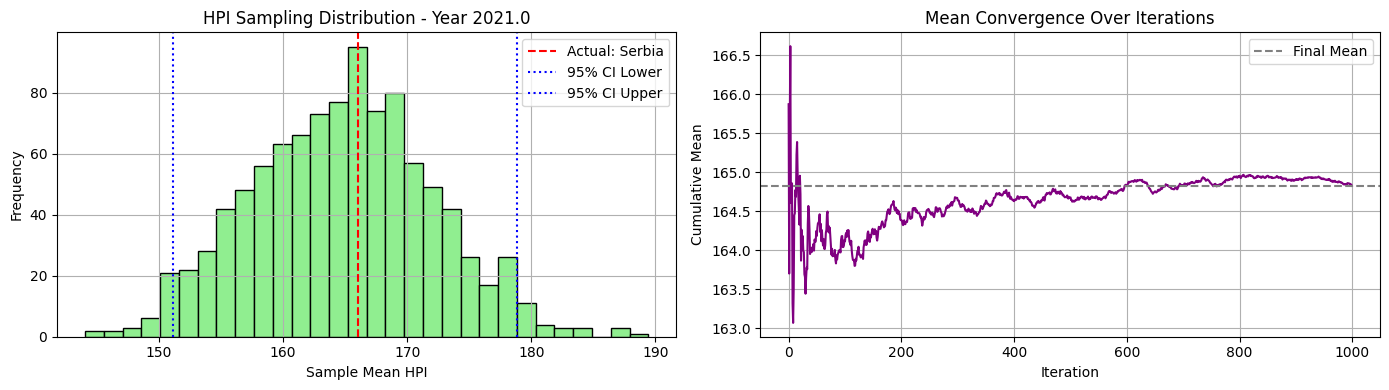

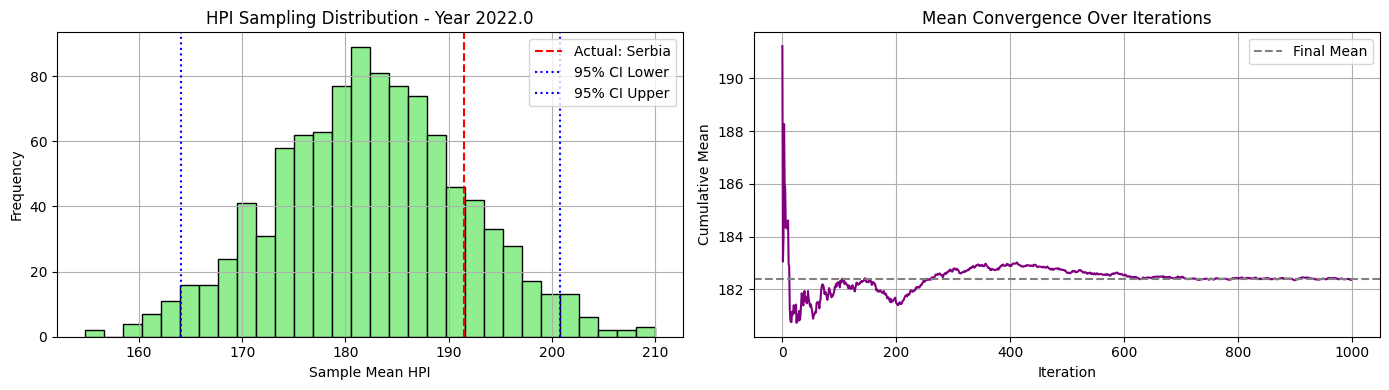

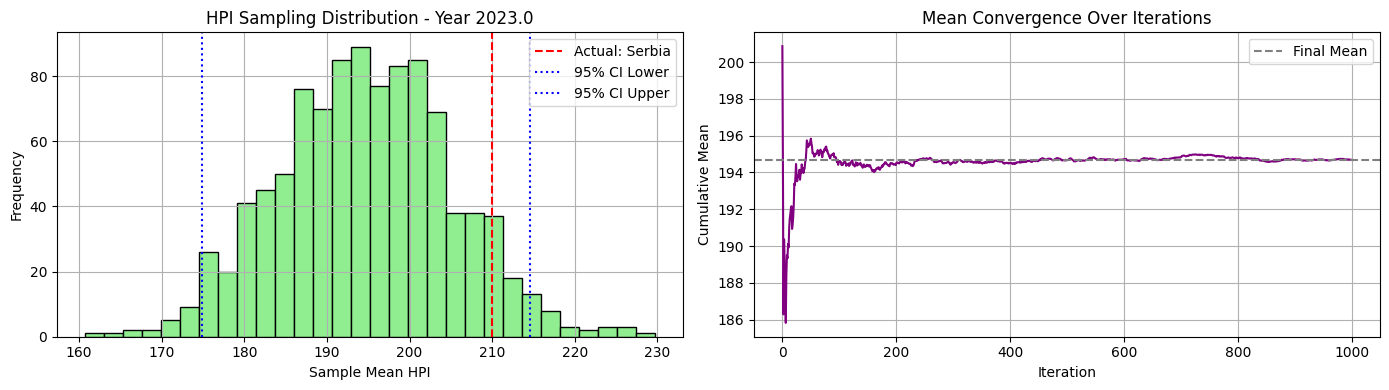

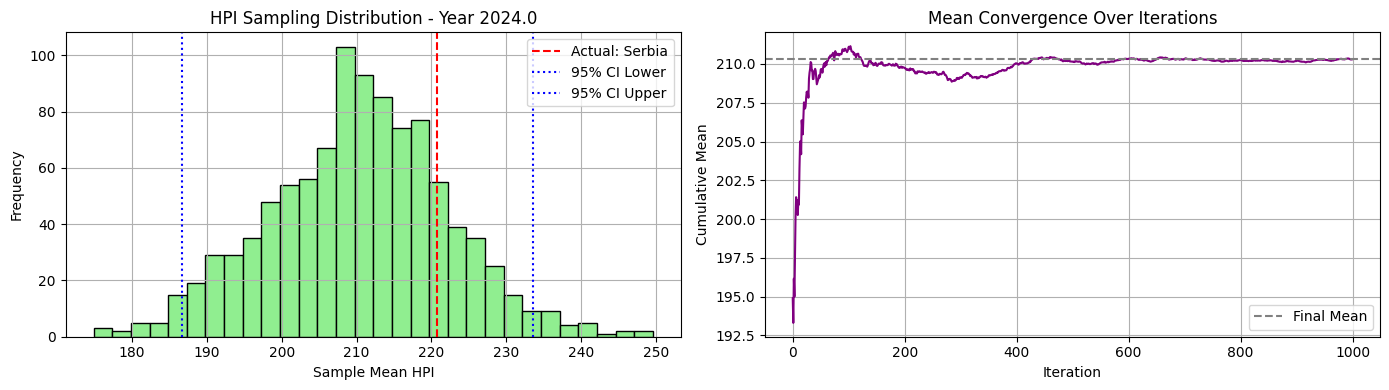

In [45]:
avg_mse_00_6, avg_mae_00_6, best_country_00_6, yearly_bootstrap_means_00_6, yearly_mean_00_6 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c6_ni20_maxi500_clusters, cluster_id=0)

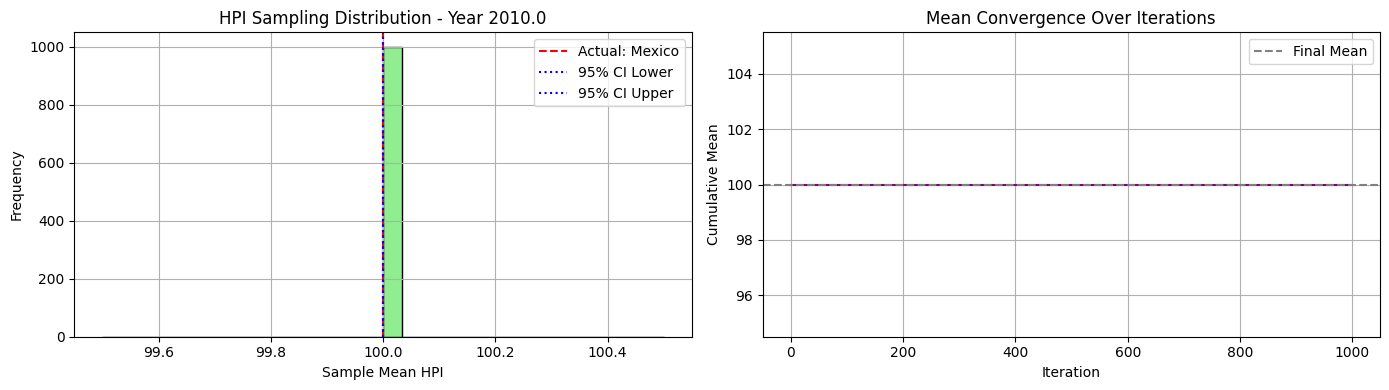

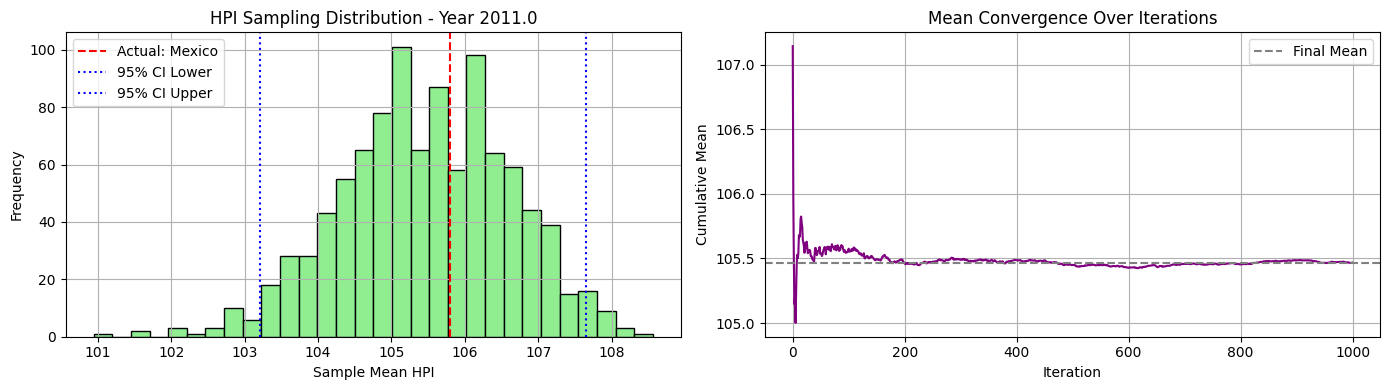

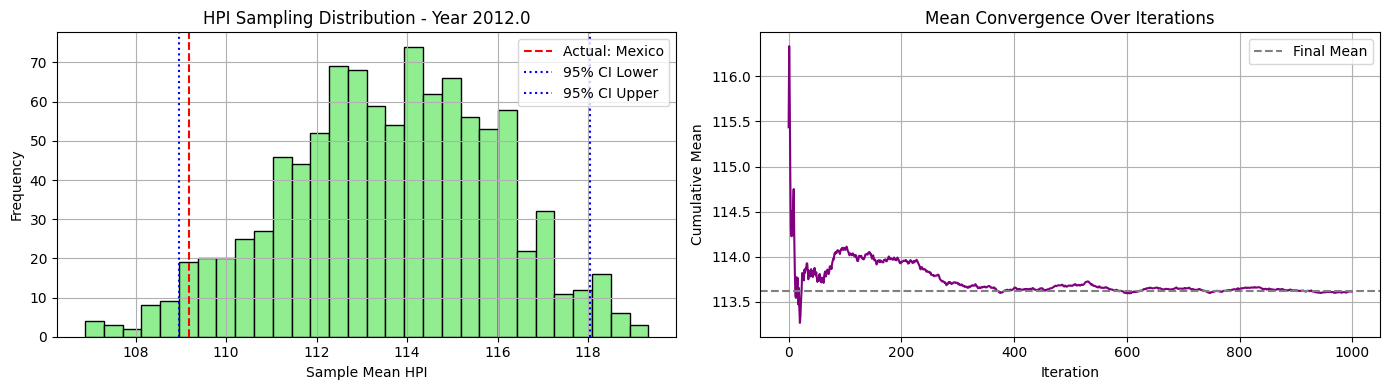

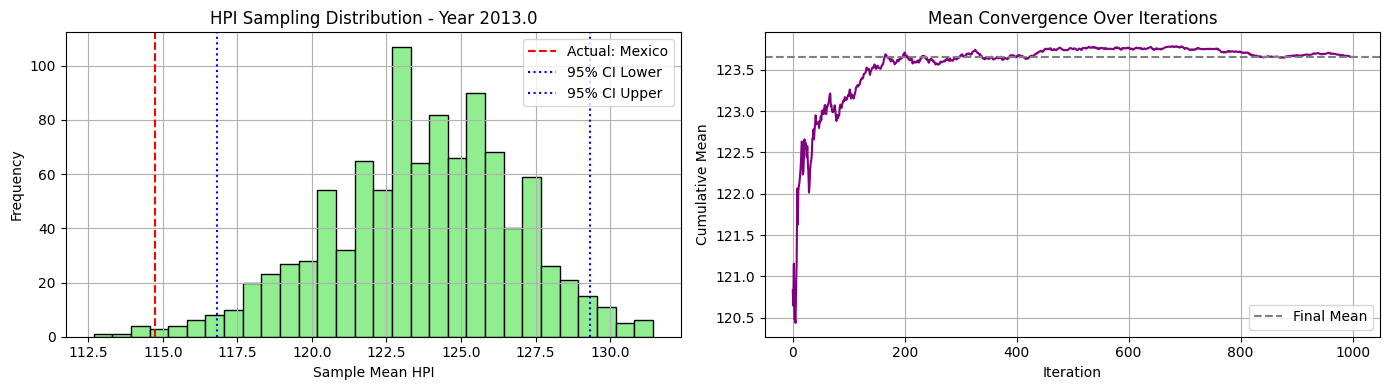

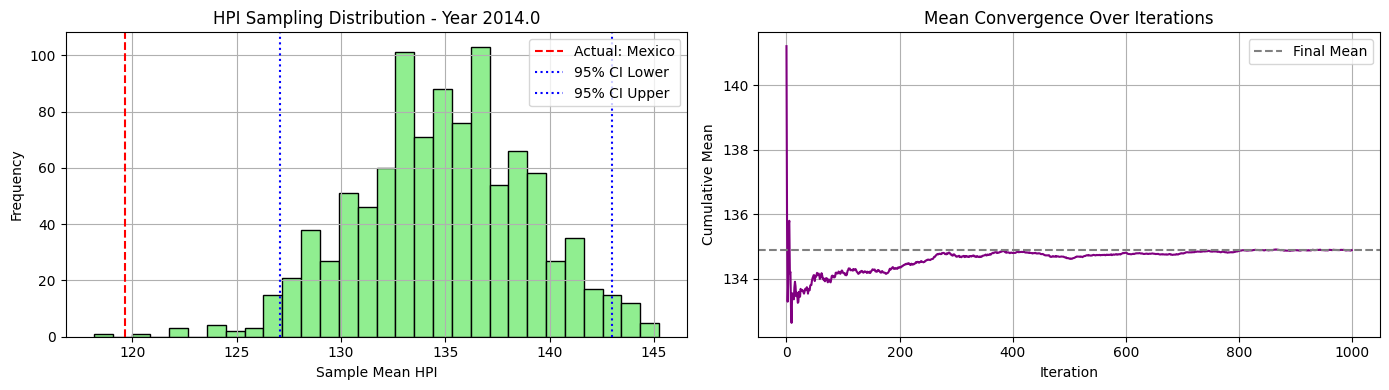

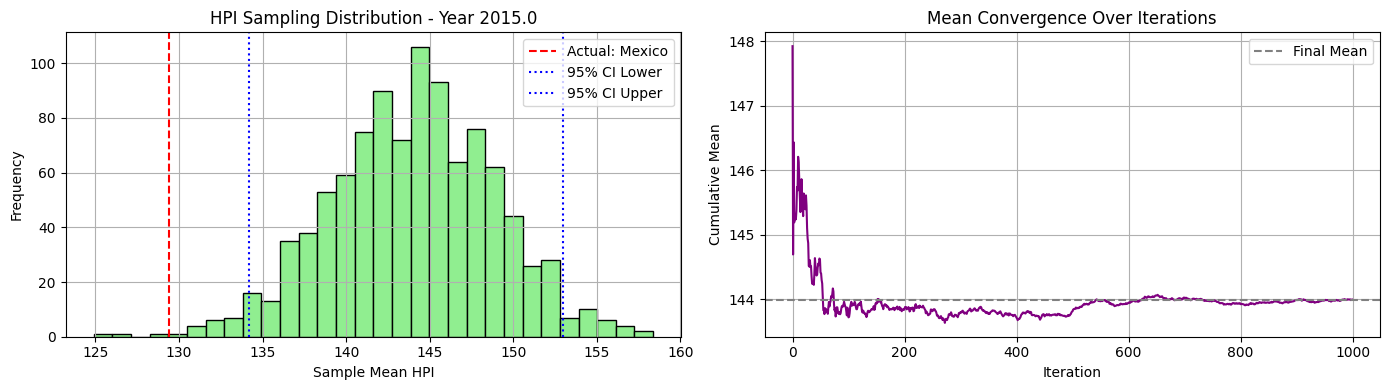

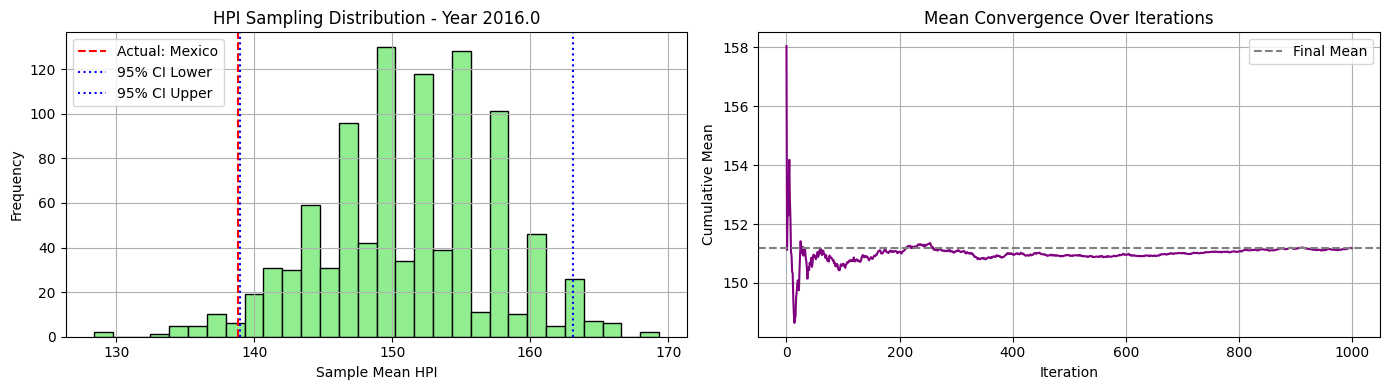

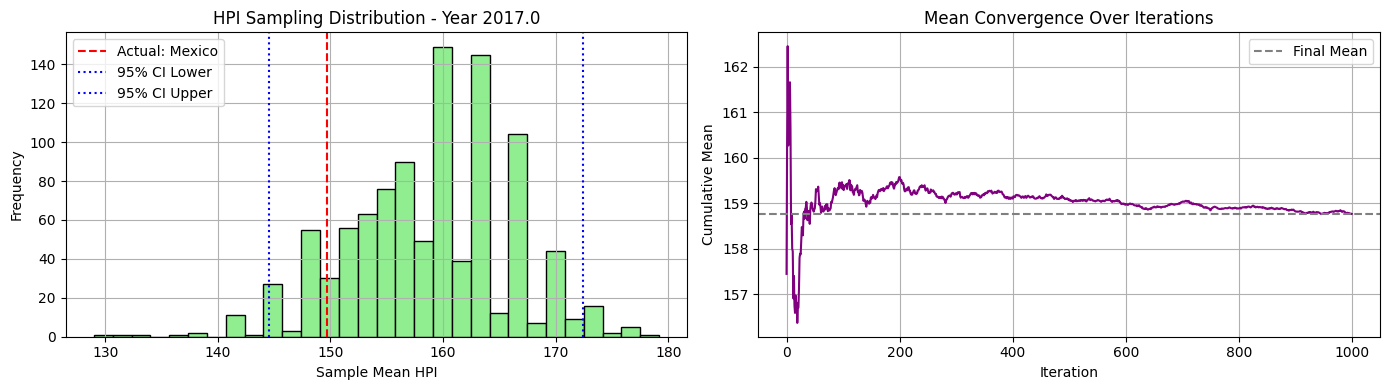

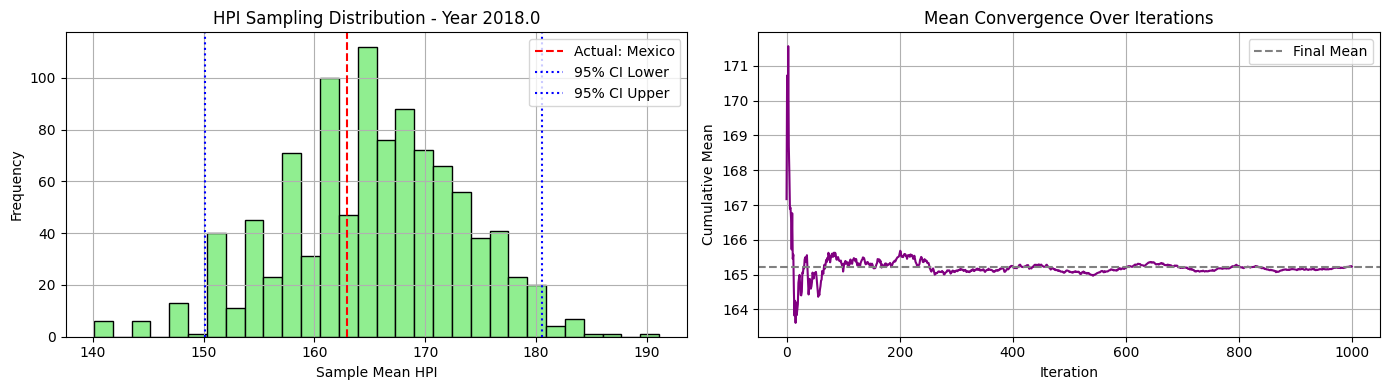

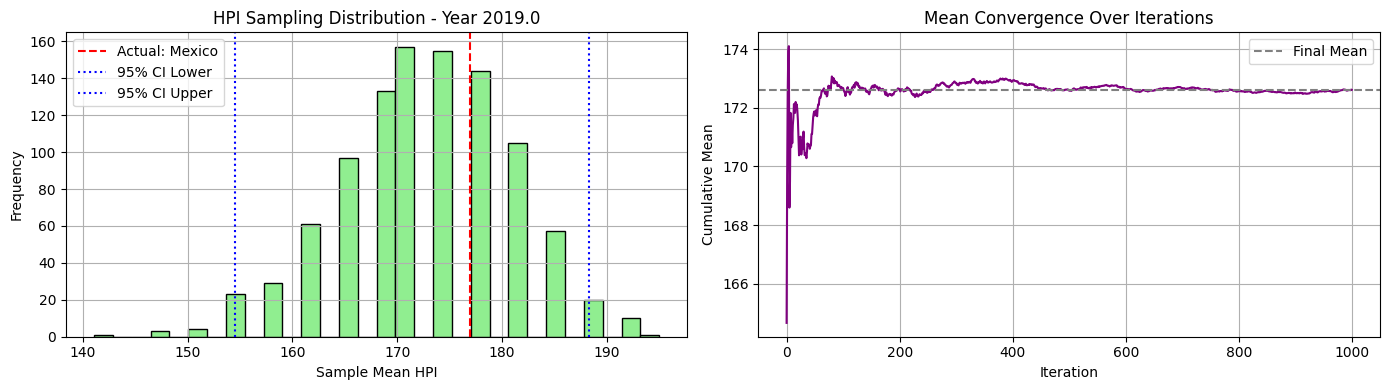

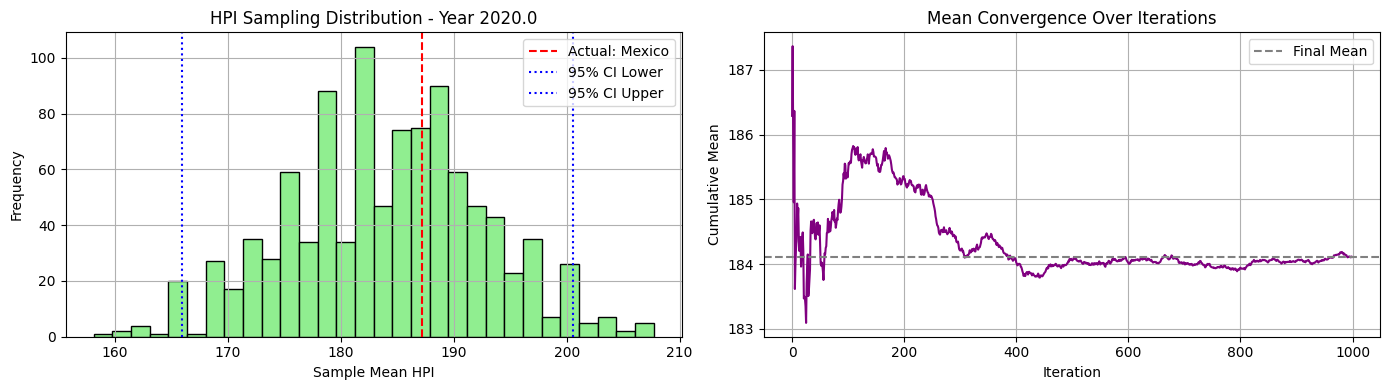

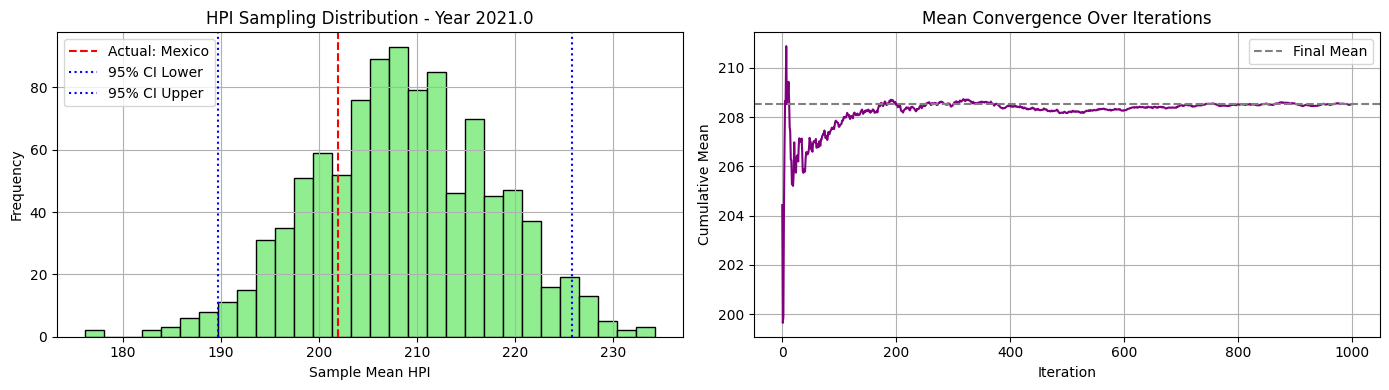

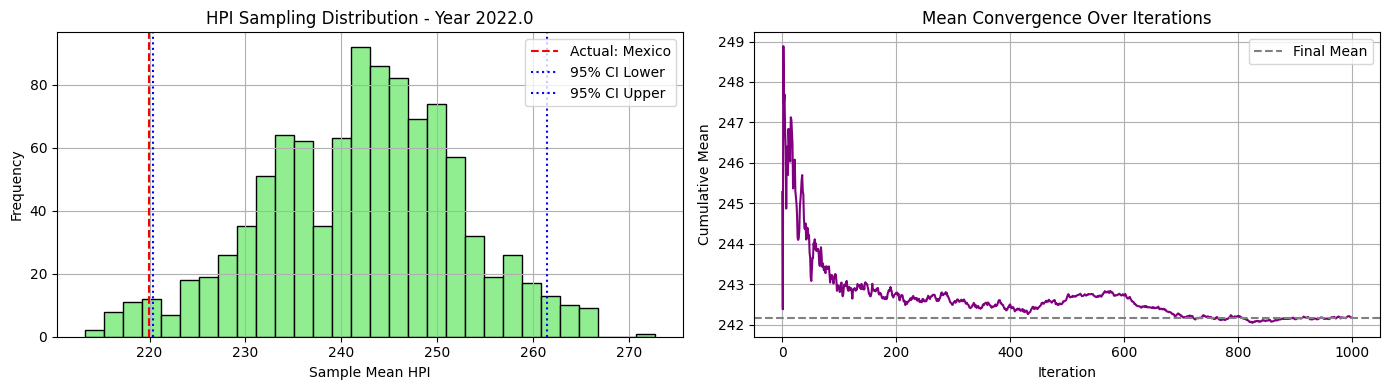

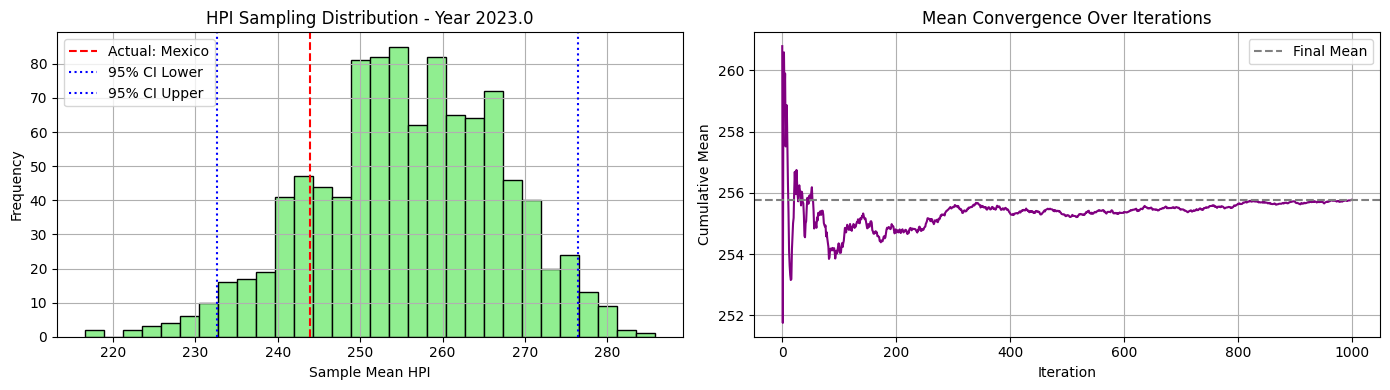

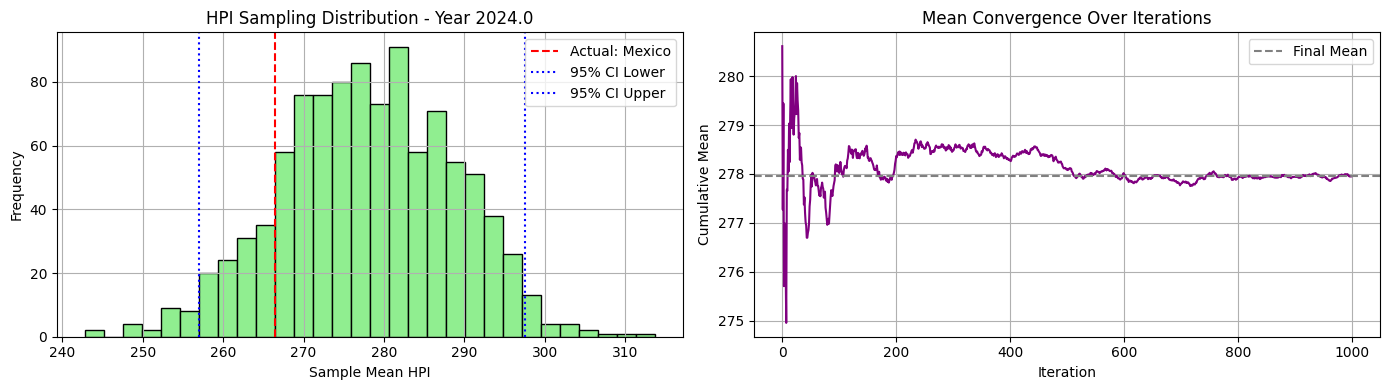

In [46]:
avg_mse_01_6, avg_mae_01_6, best_country_01_6, yearly_bootstrap_means_01_6, yearly_mean_01_6 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c6_ni20_maxi500_clusters, cluster_id=1)

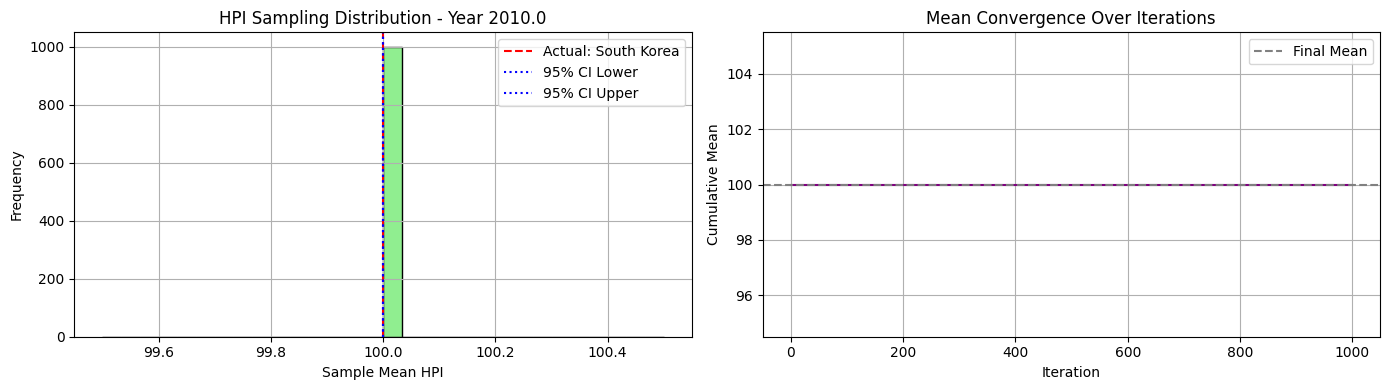

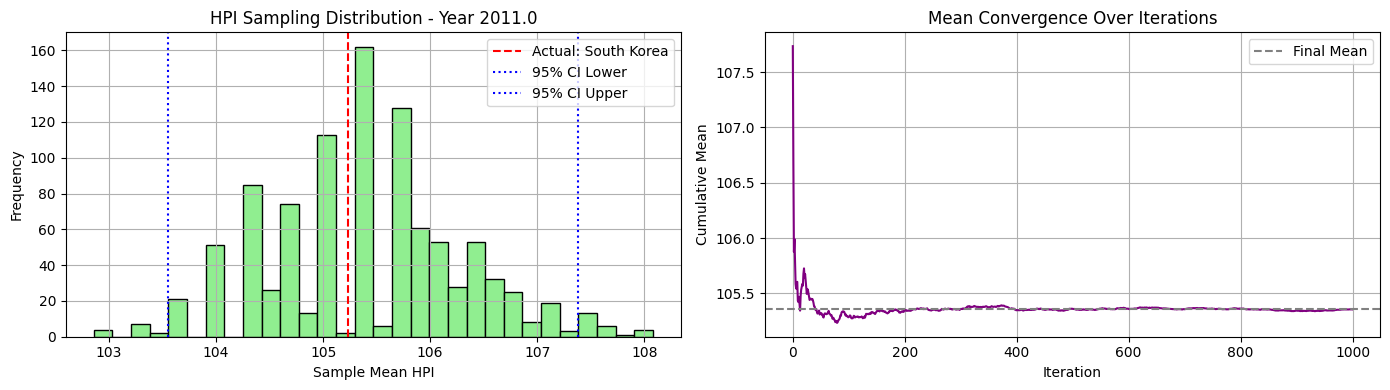

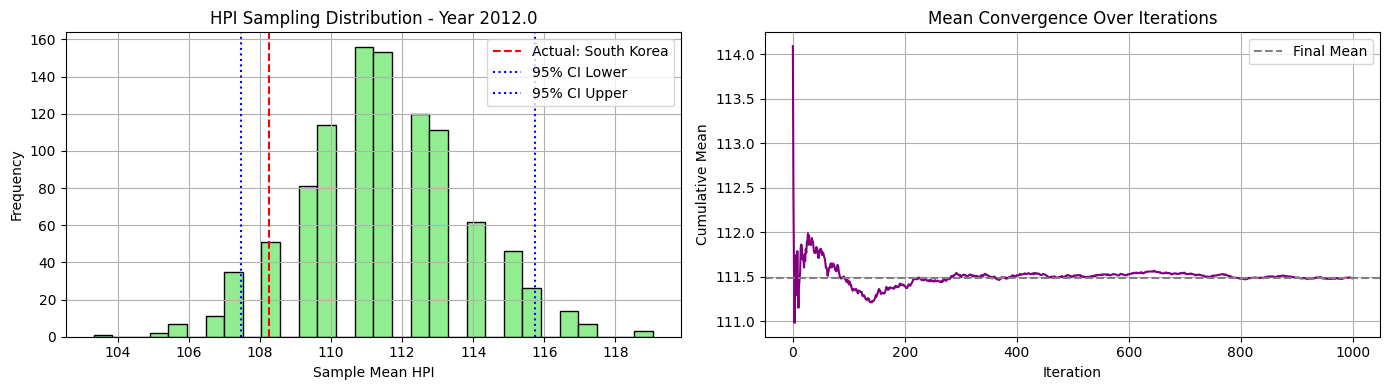

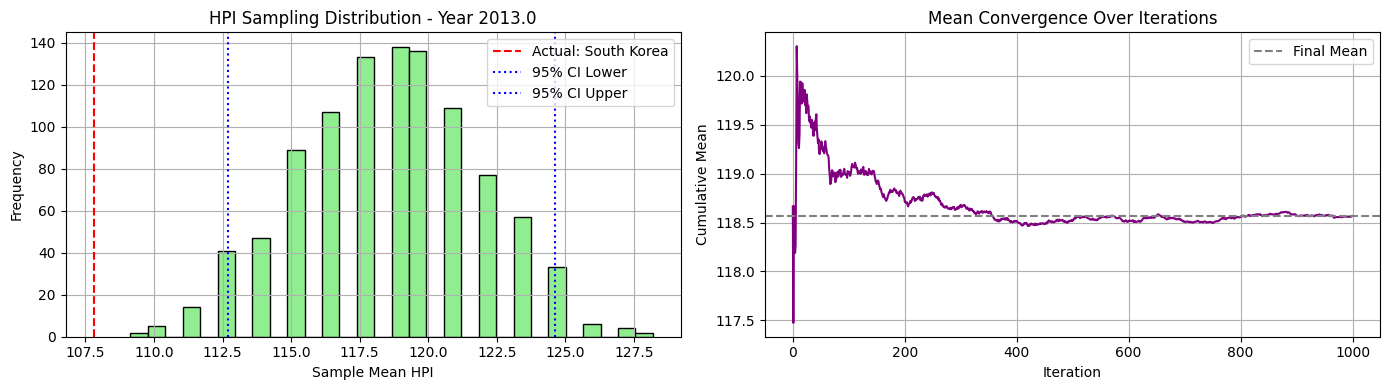

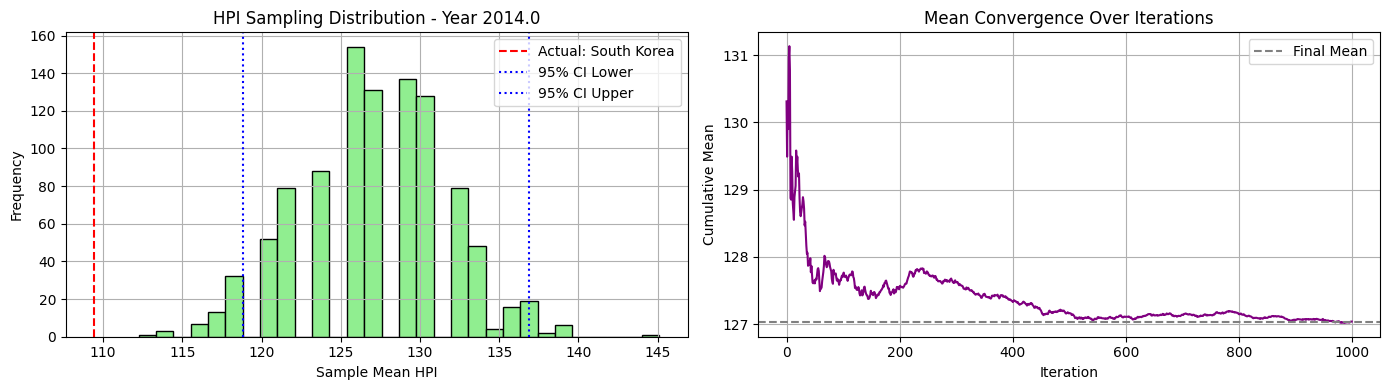

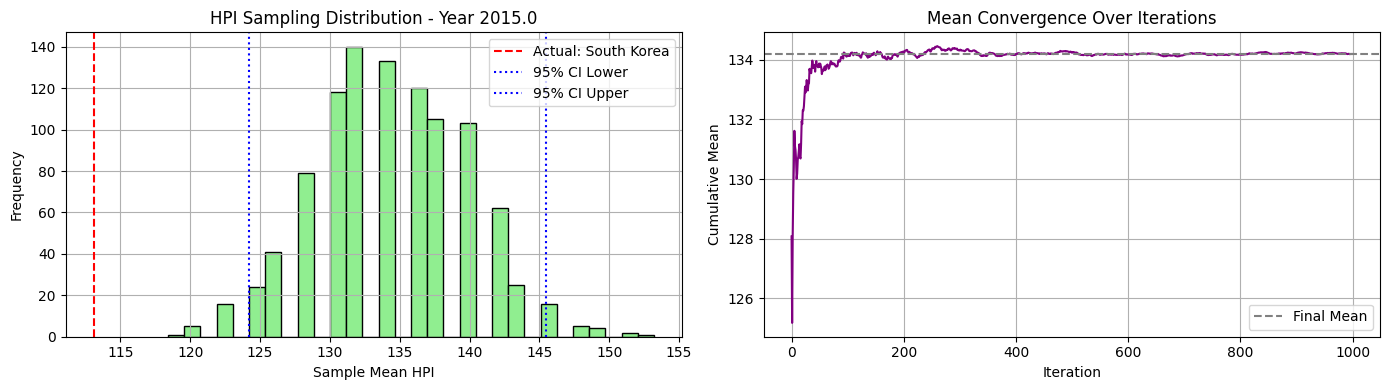

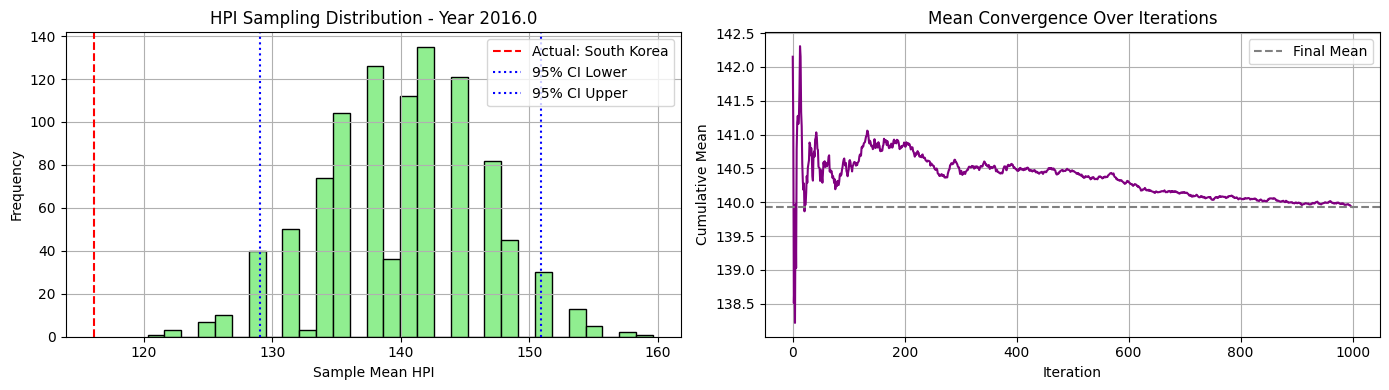

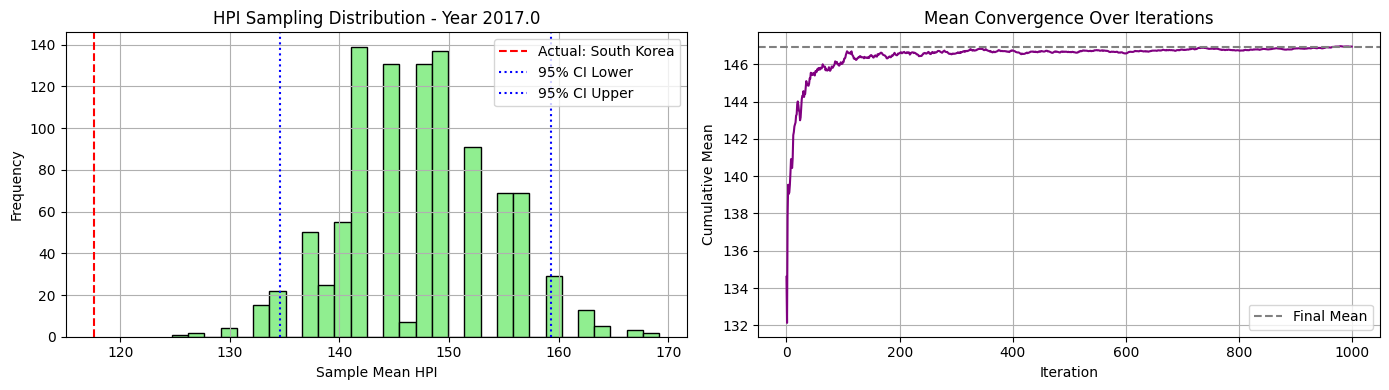

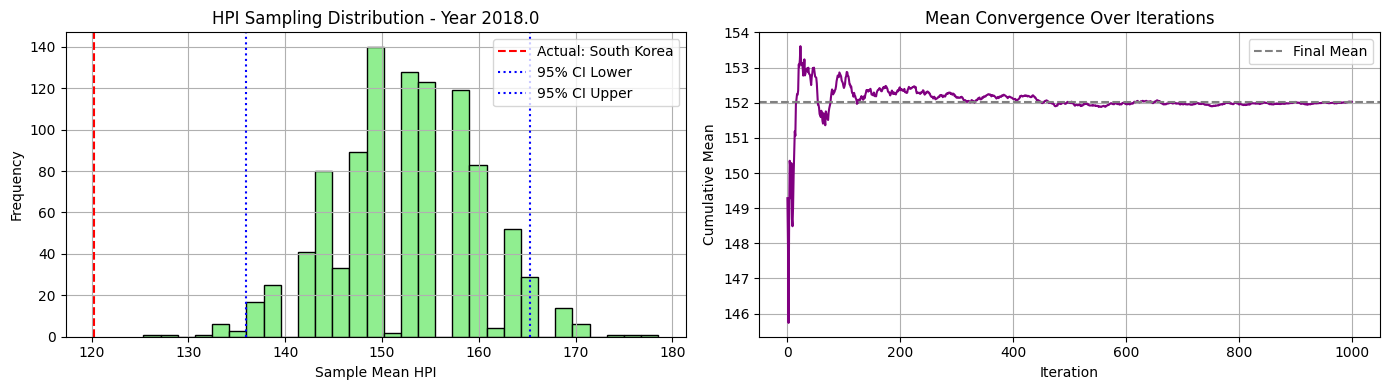

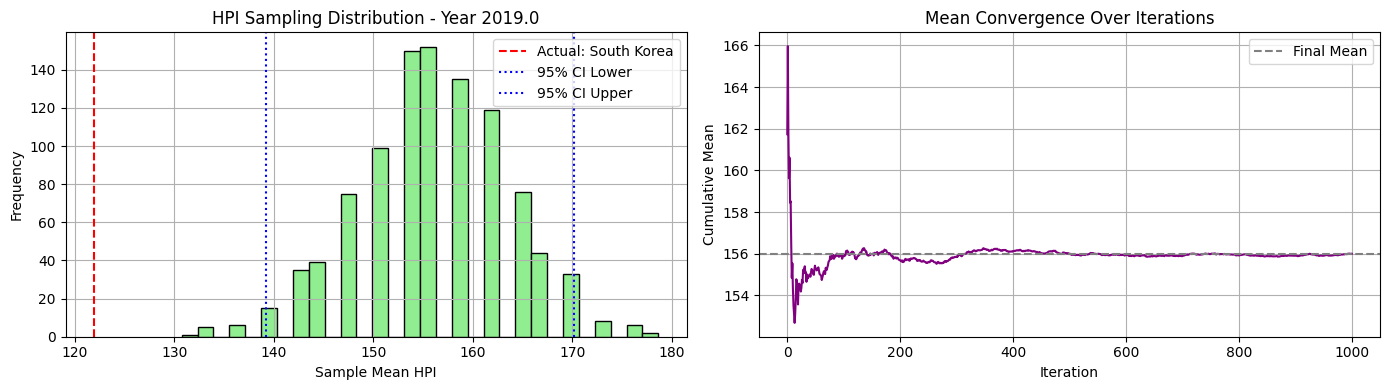

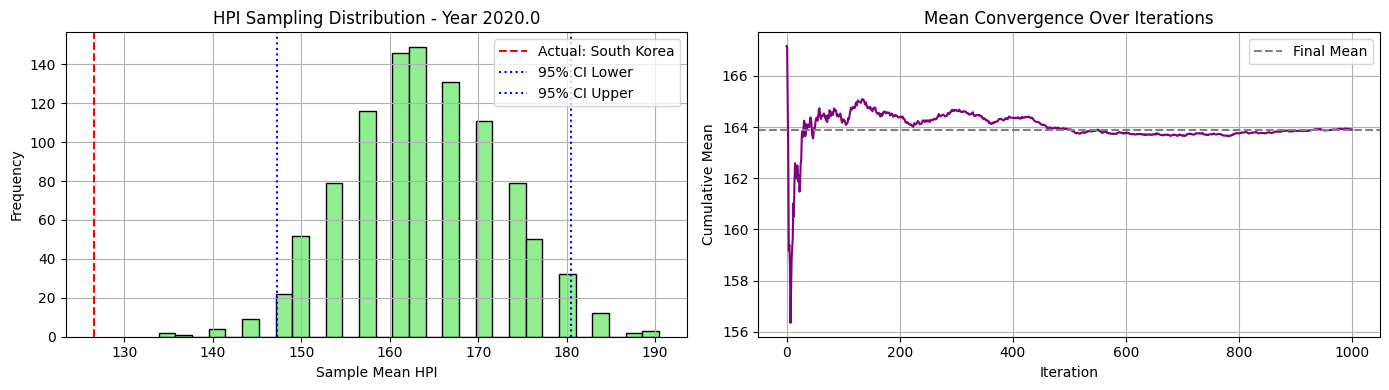

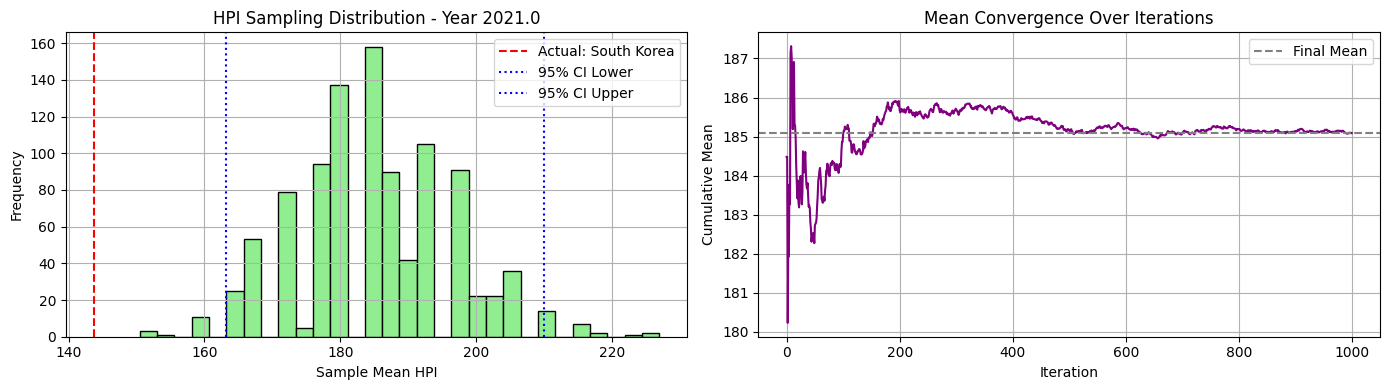

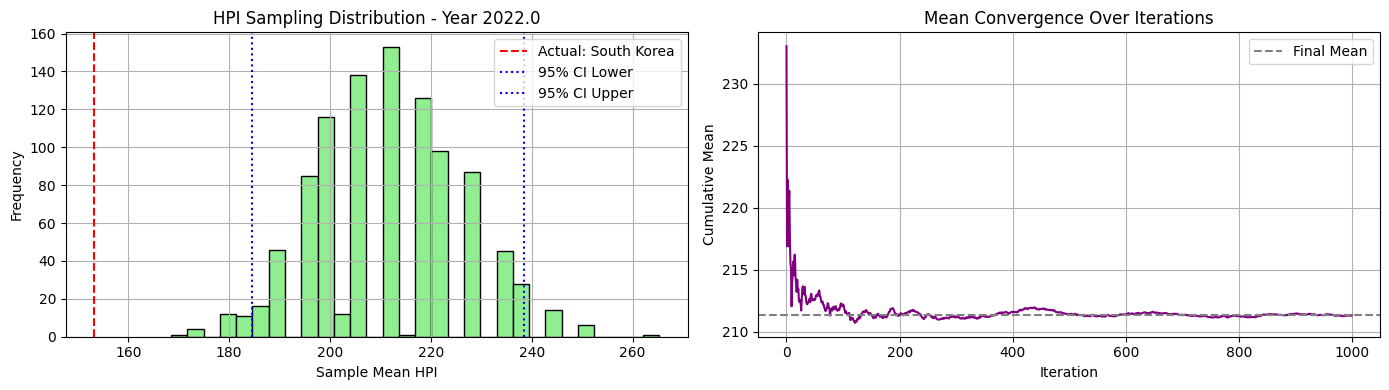

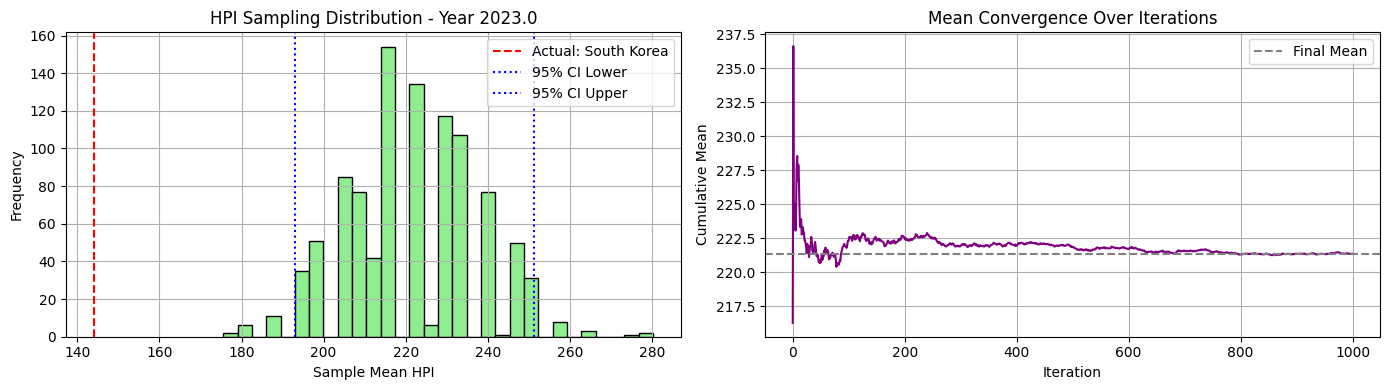

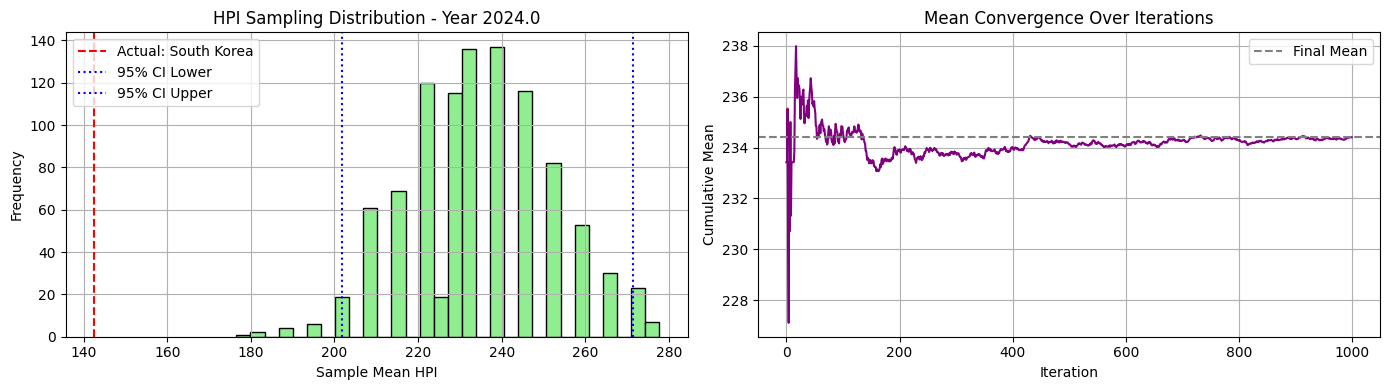

In [47]:
avg_mse_02_6, avg_mae_02_6, best_country_02_6, yearly_bootstrap_means_02_6, yearly_mean_02_6 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c6_ni20_maxi500_clusters, cluster_id=2)

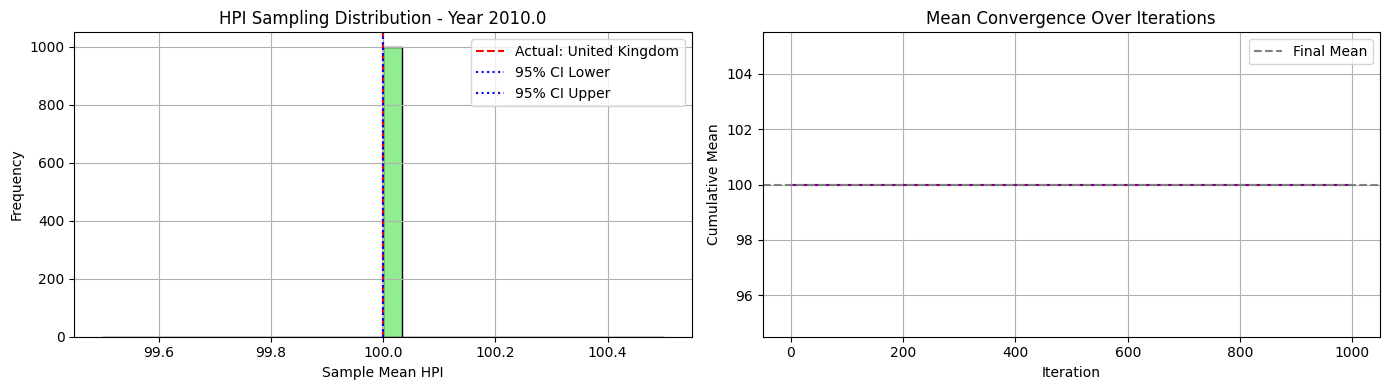

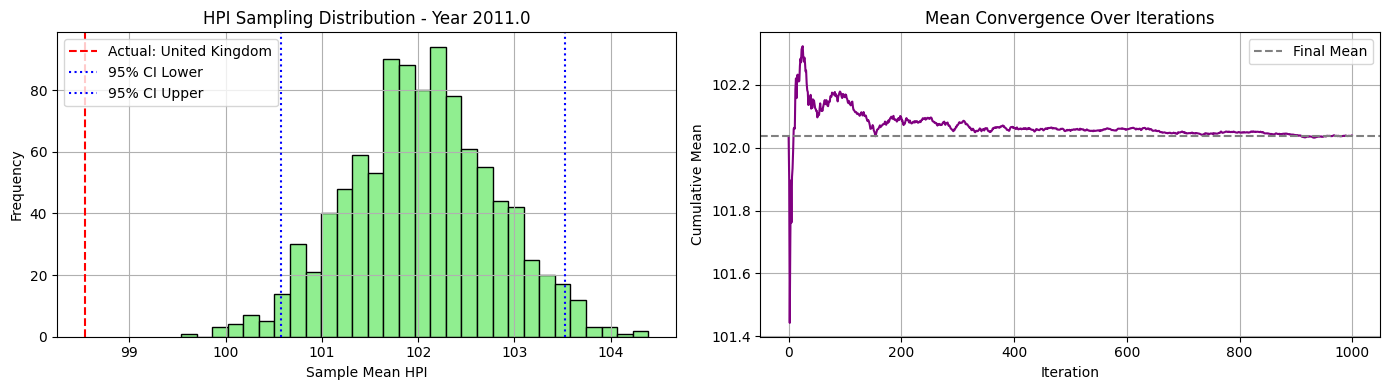

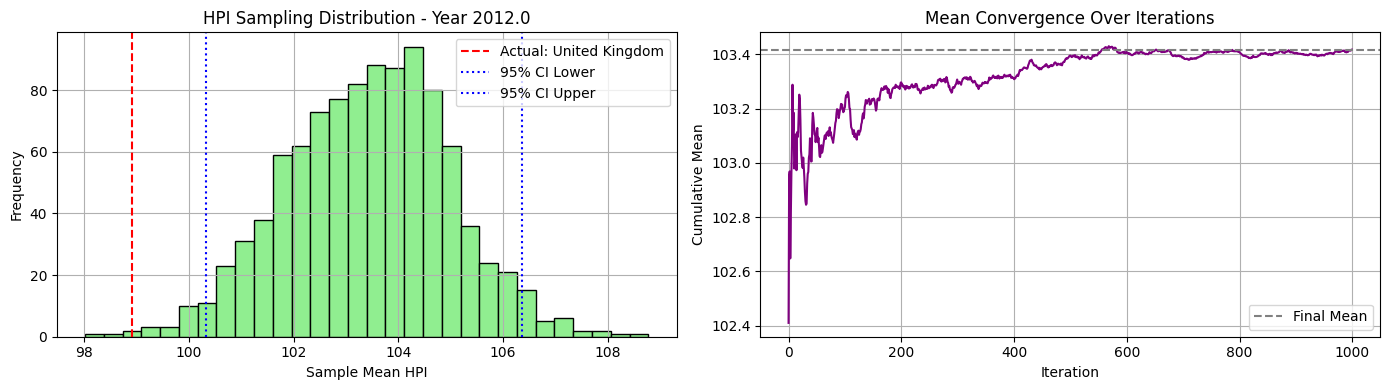

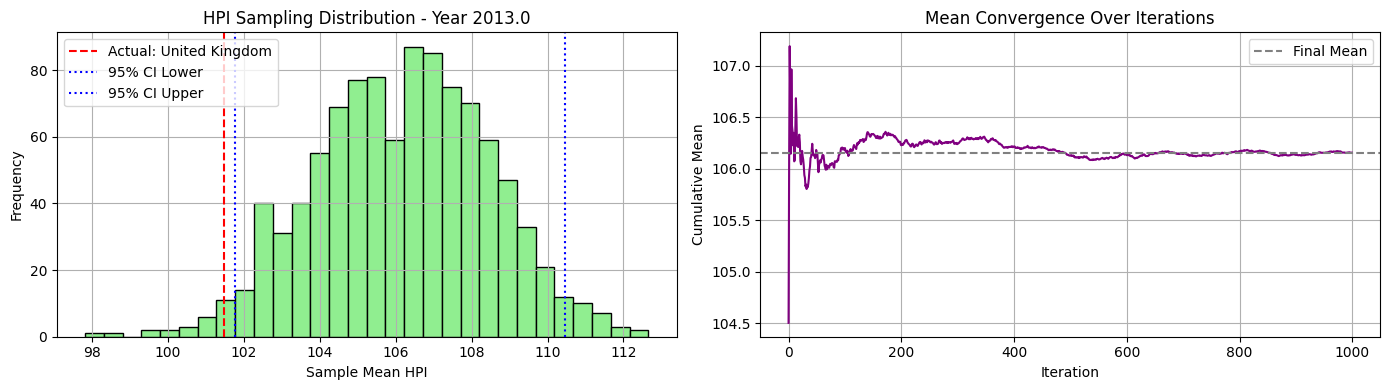

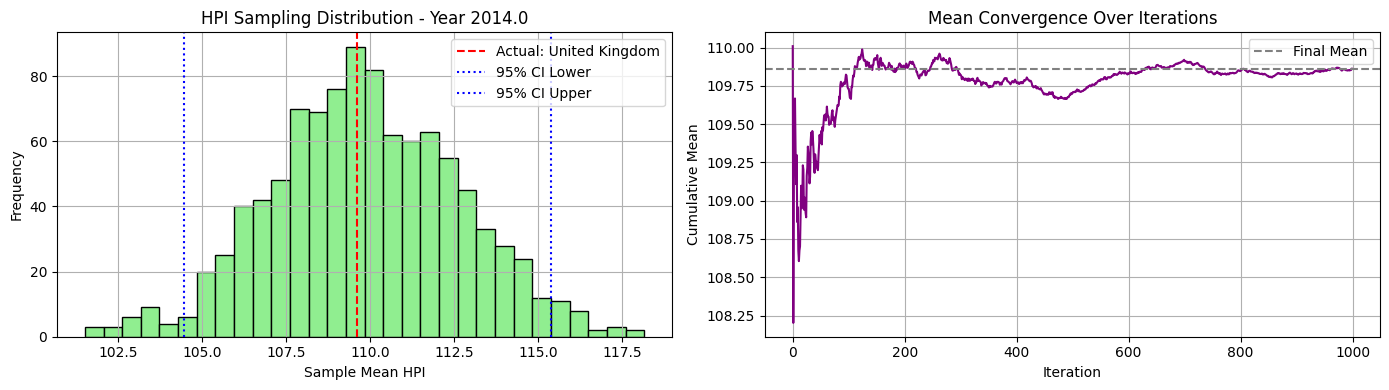

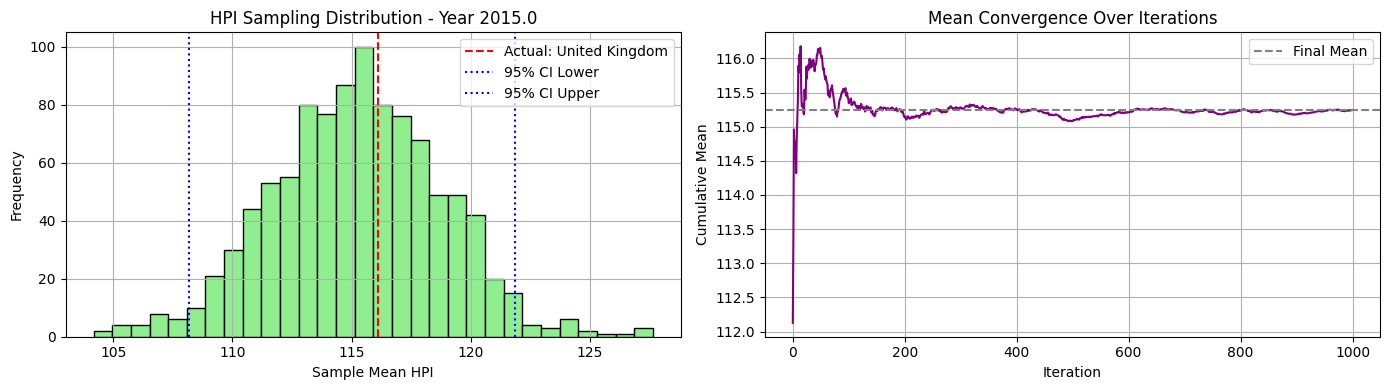

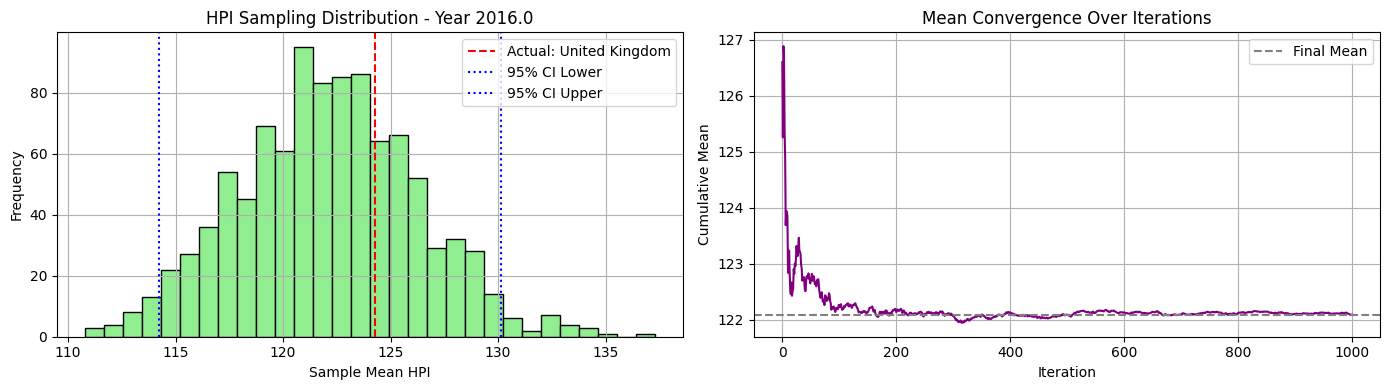

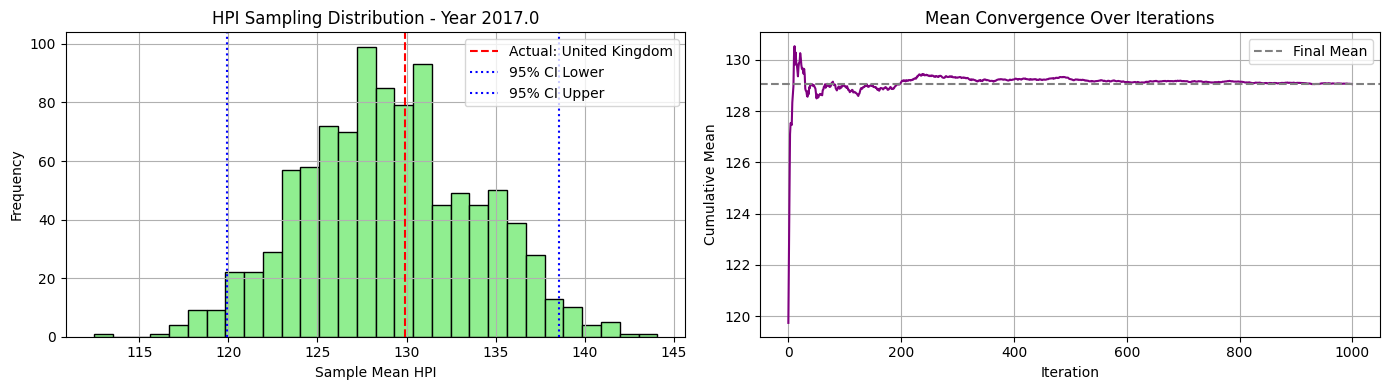

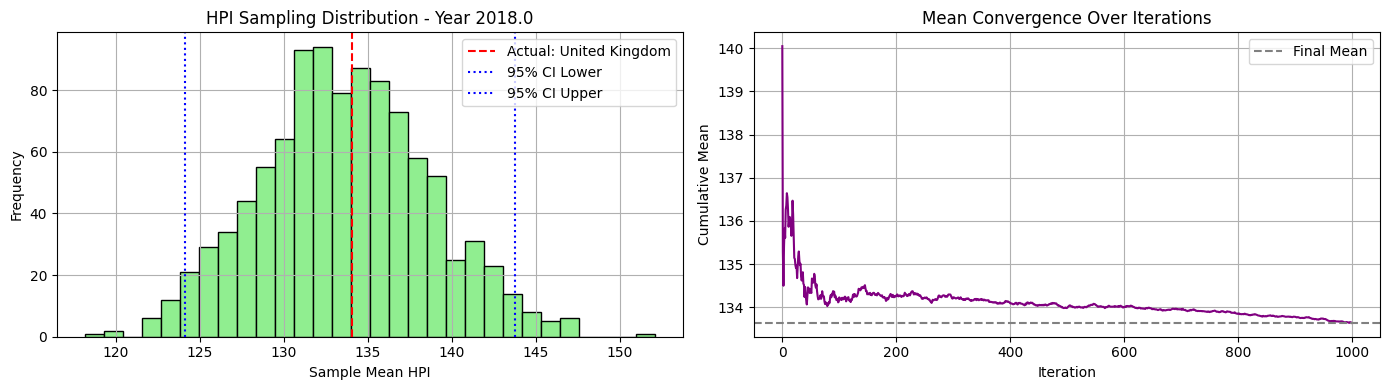

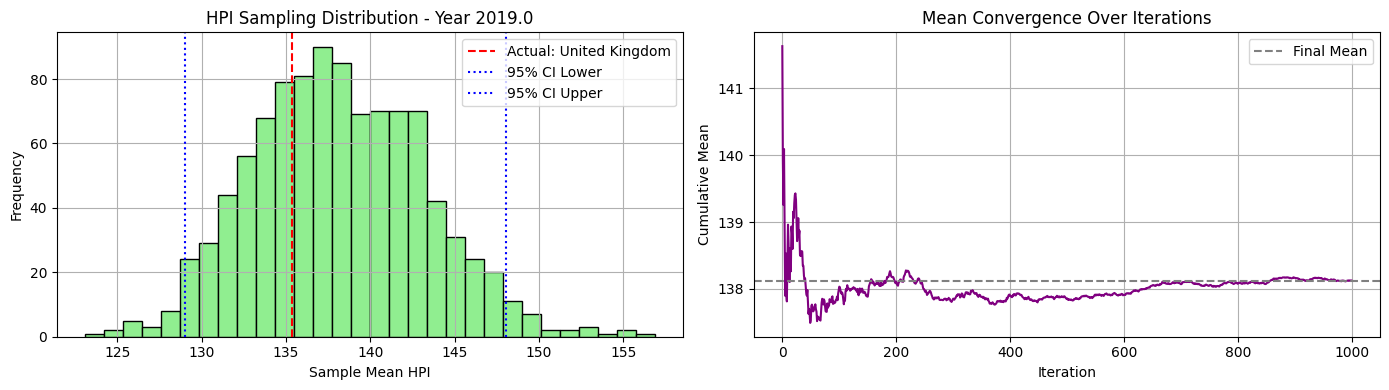

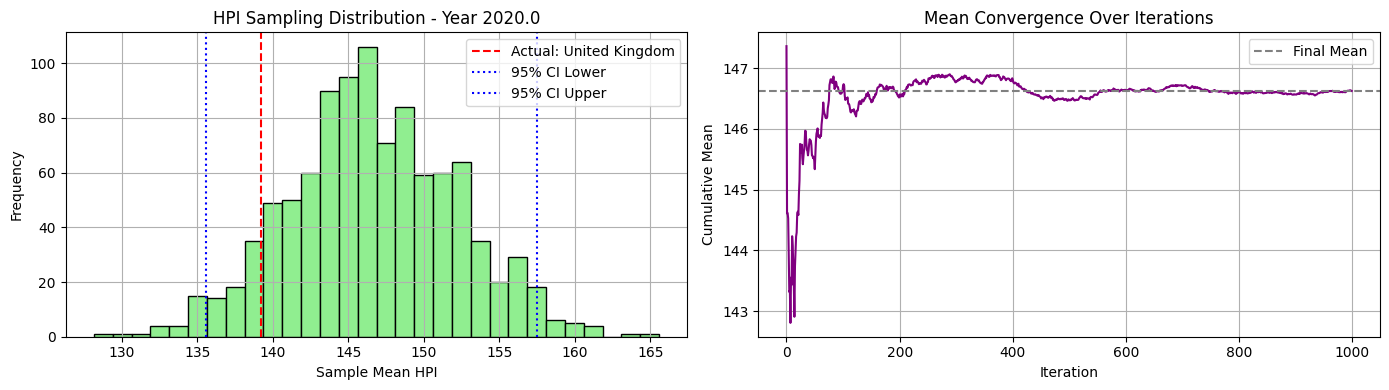

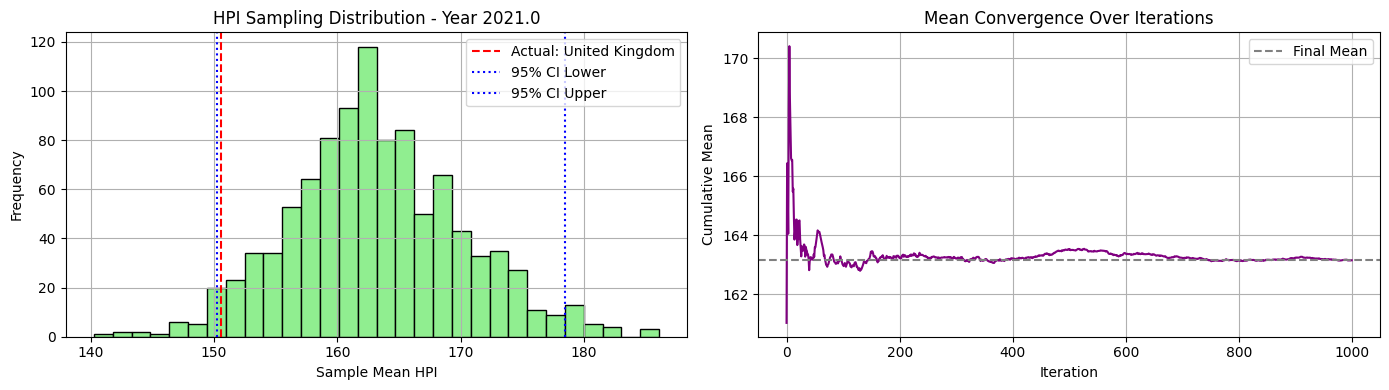

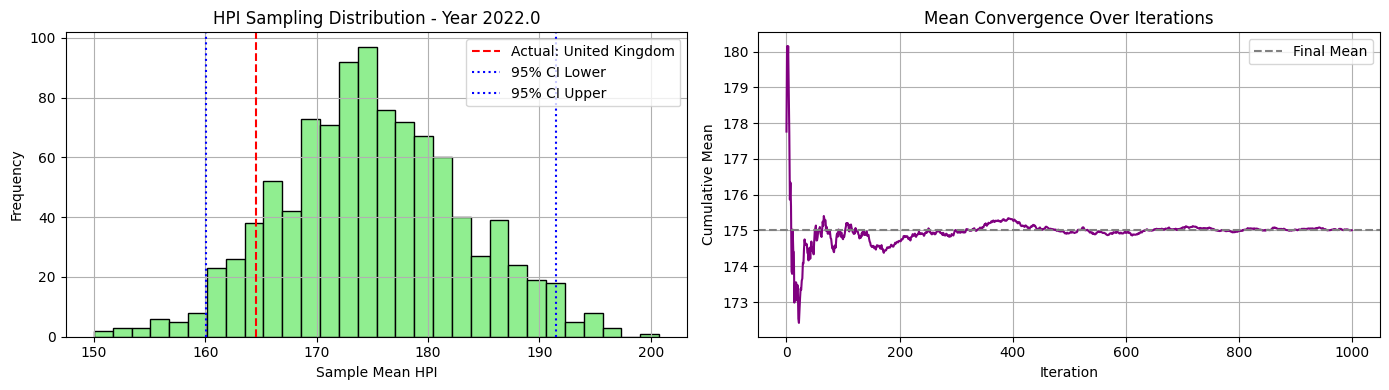

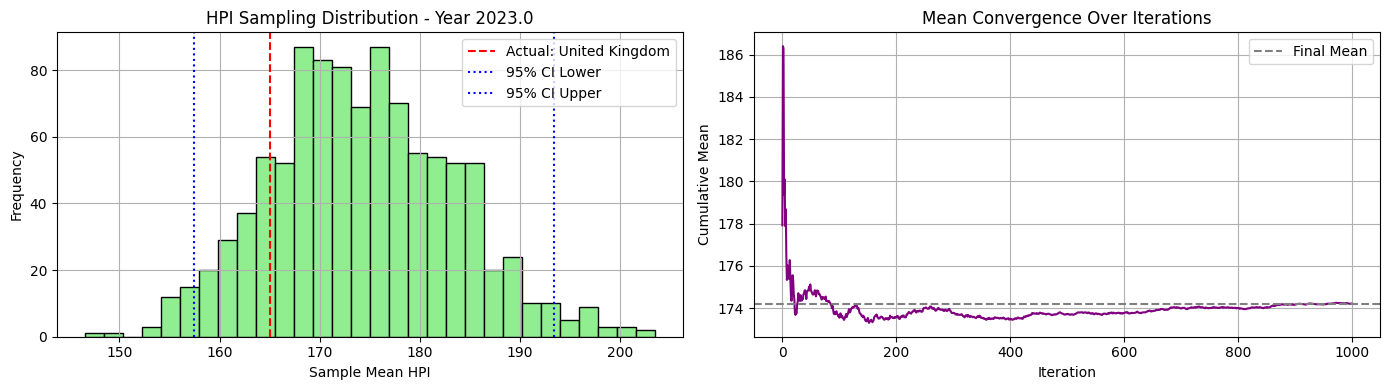

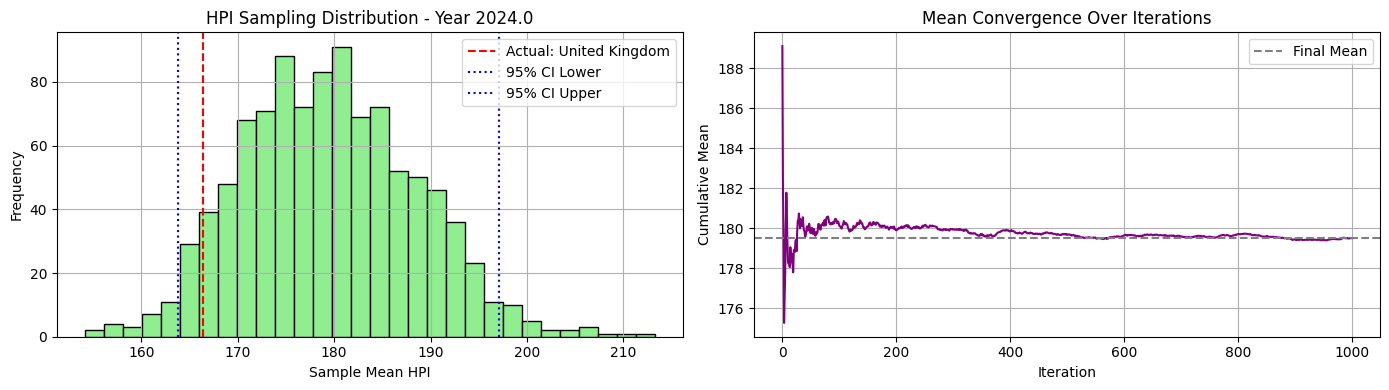

In [48]:
avg_mse_03_6, avg_mae_03_6, best_country_03_6, yearly_bootstrap_means_03_6, yearly_mean_03_6 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c6_ni20_maxi500_clusters, cluster_id=3)

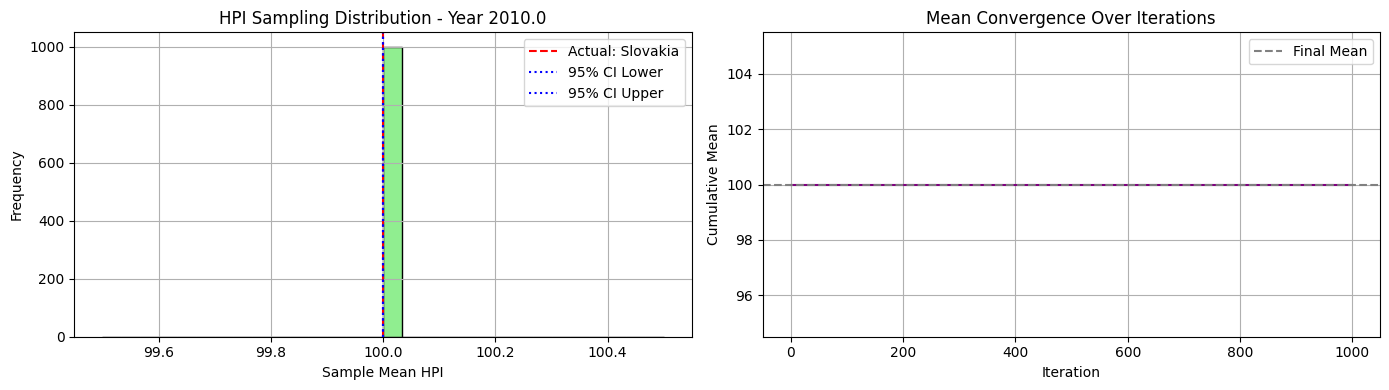

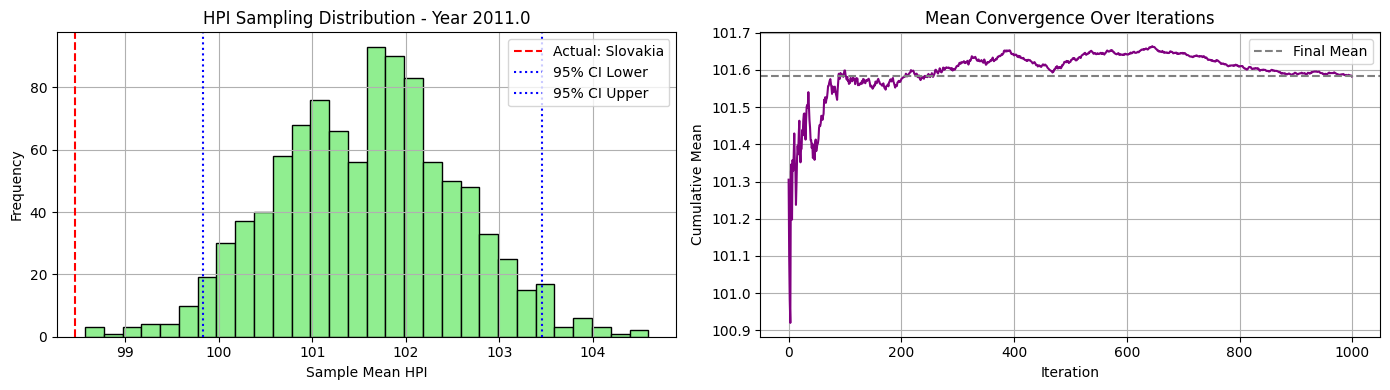

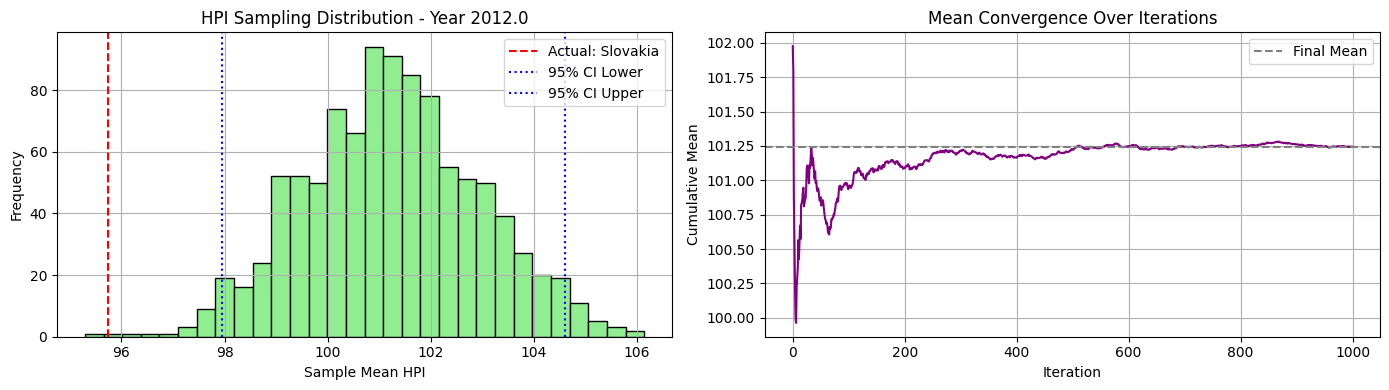

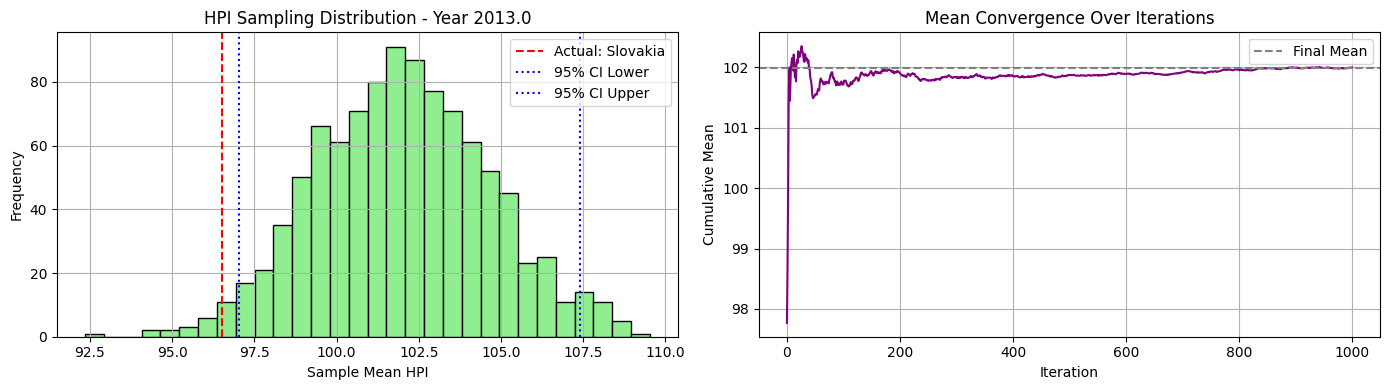

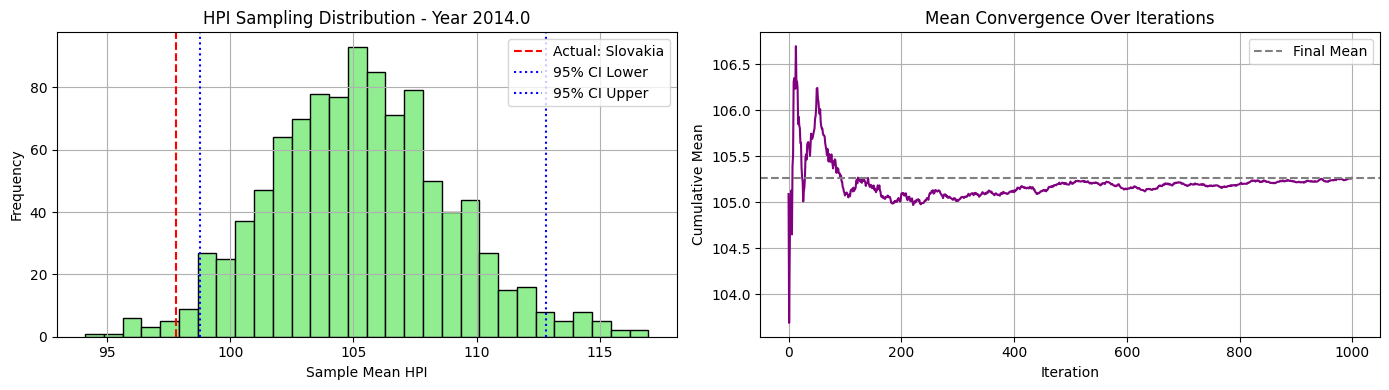

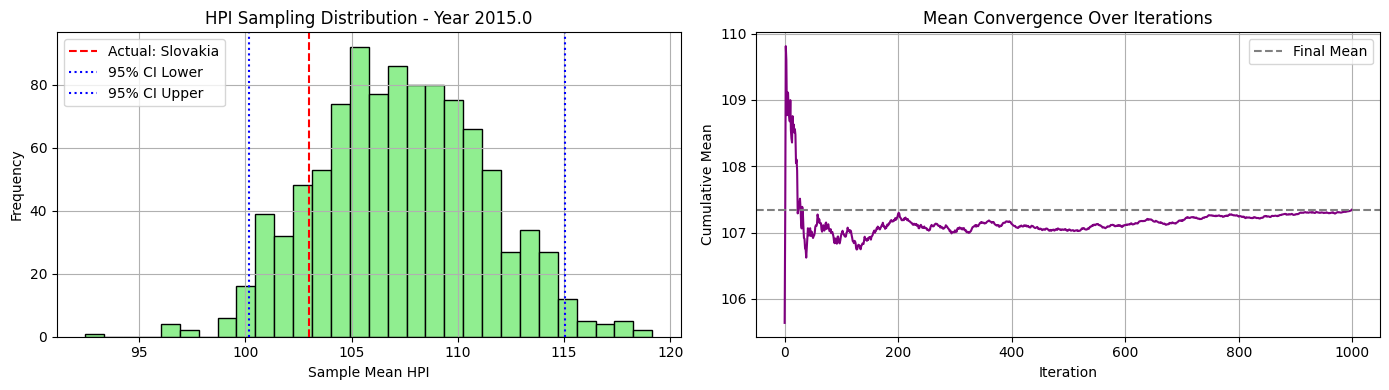

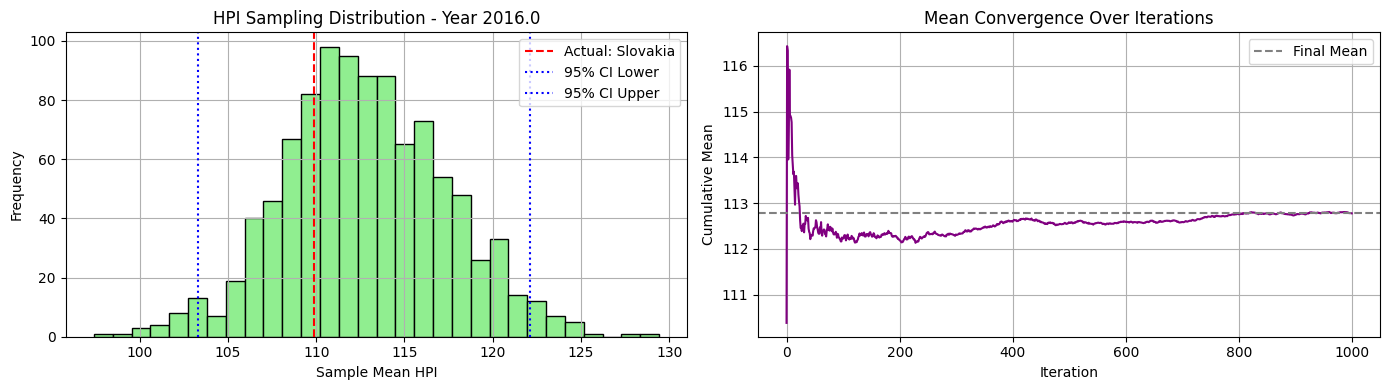

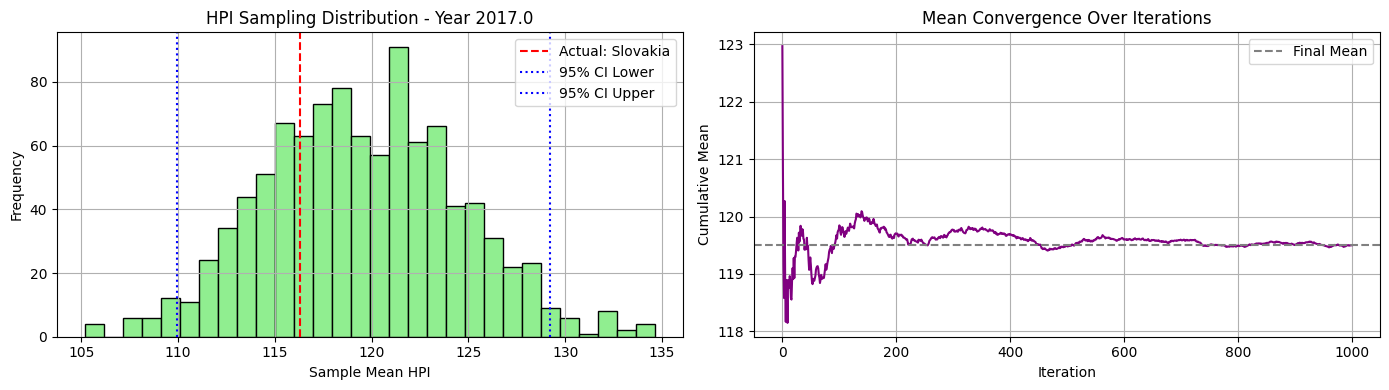

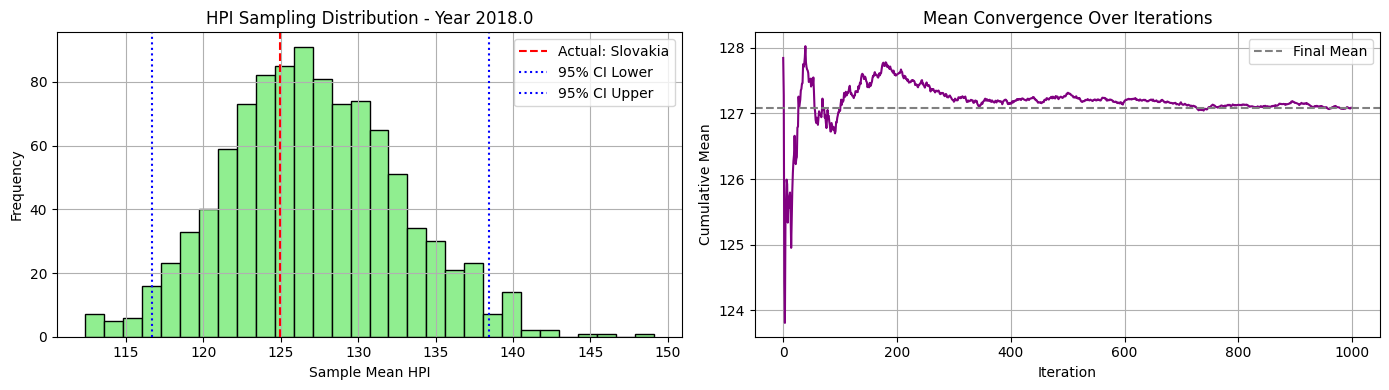

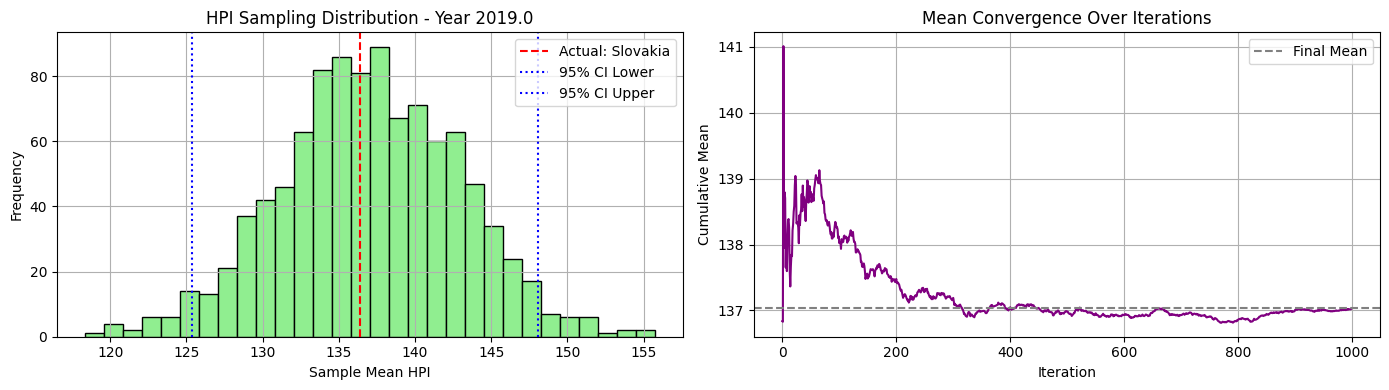

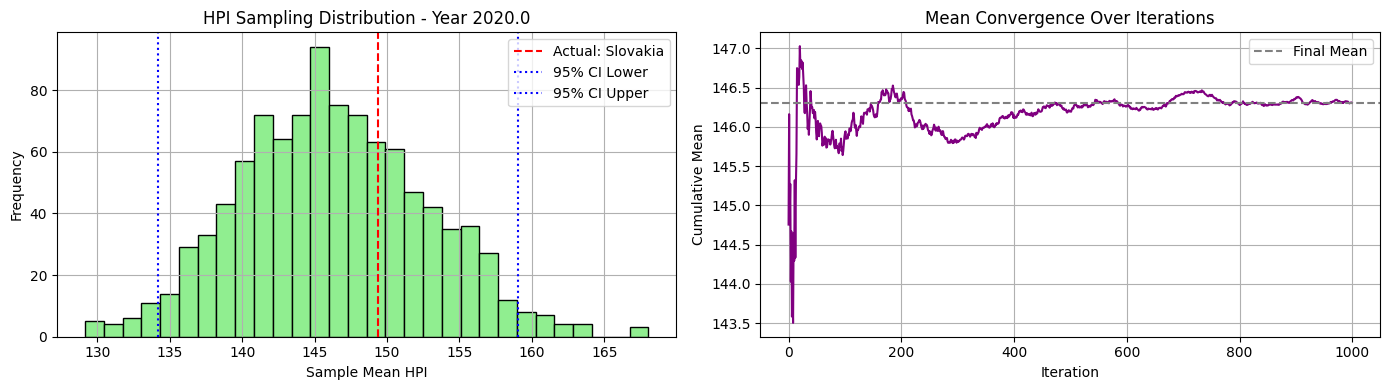

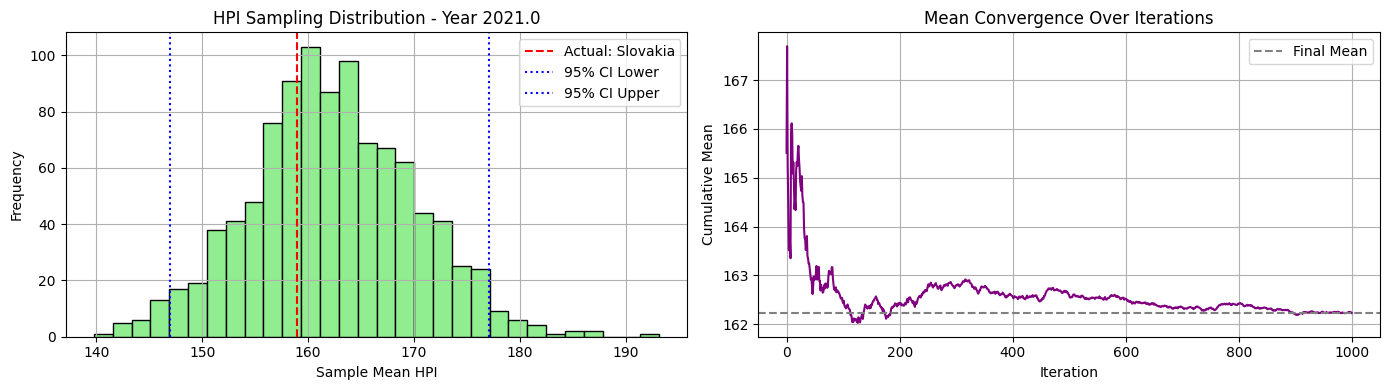

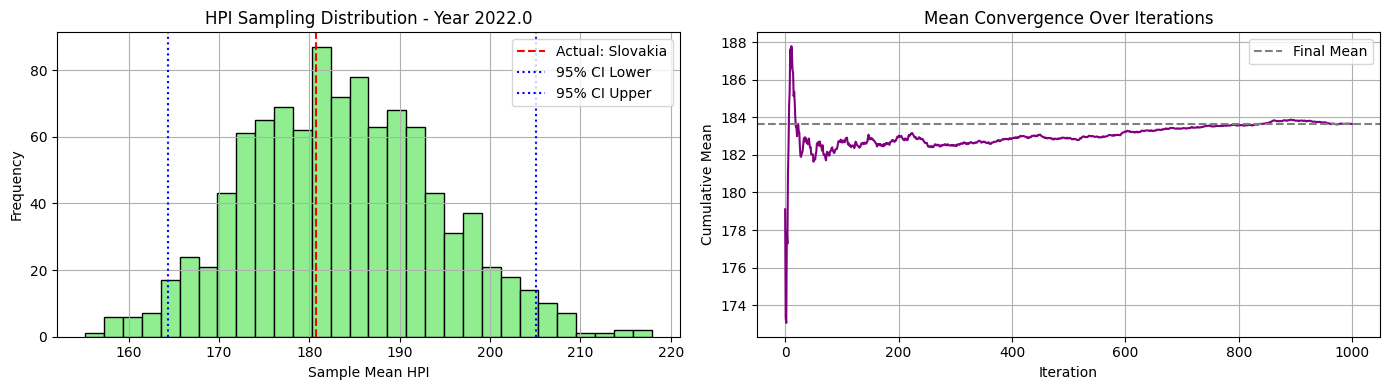

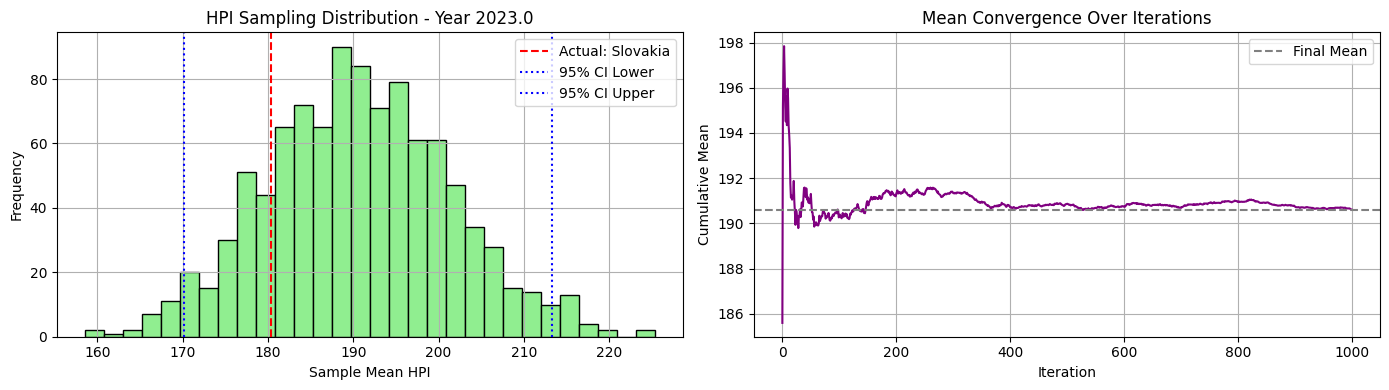

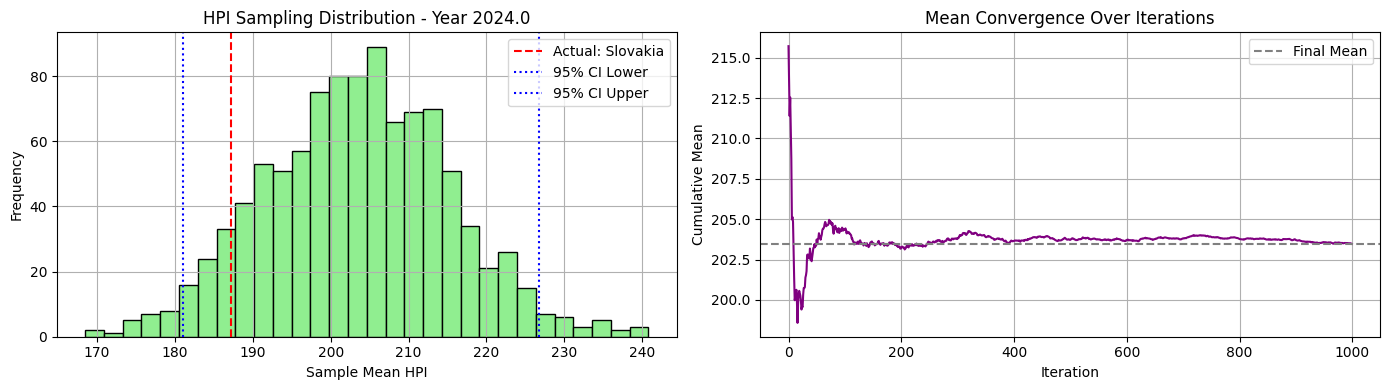

In [49]:
avg_mse_04_6, avg_mae_04_6, best_country_04_6, yearly_bootstrap_means_04_6, yearly_mean_04_6 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c6_ni20_maxi500_clusters, cluster_id=4)

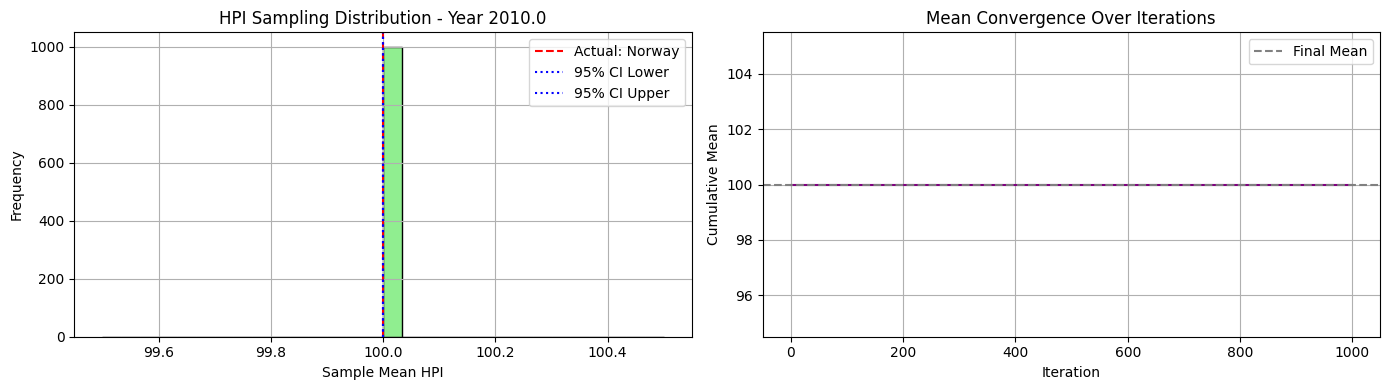

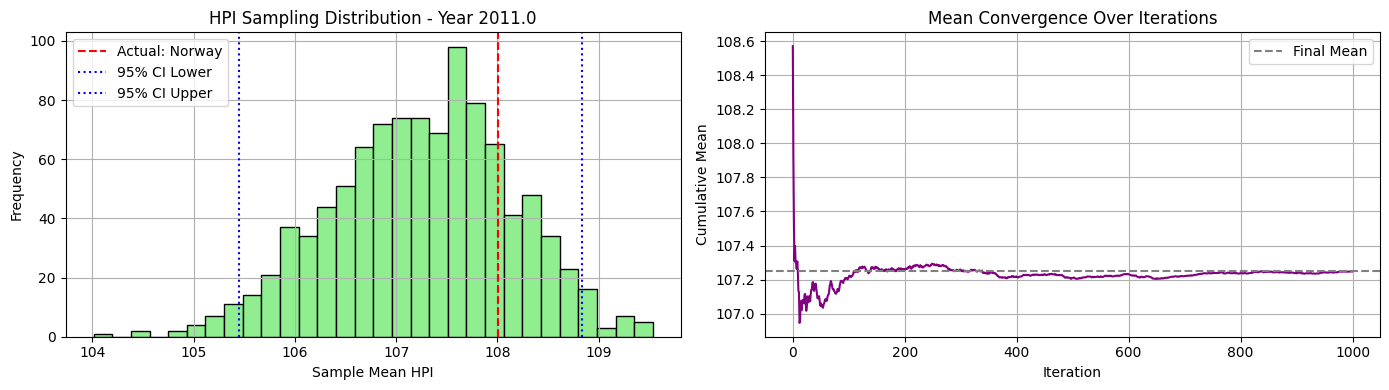

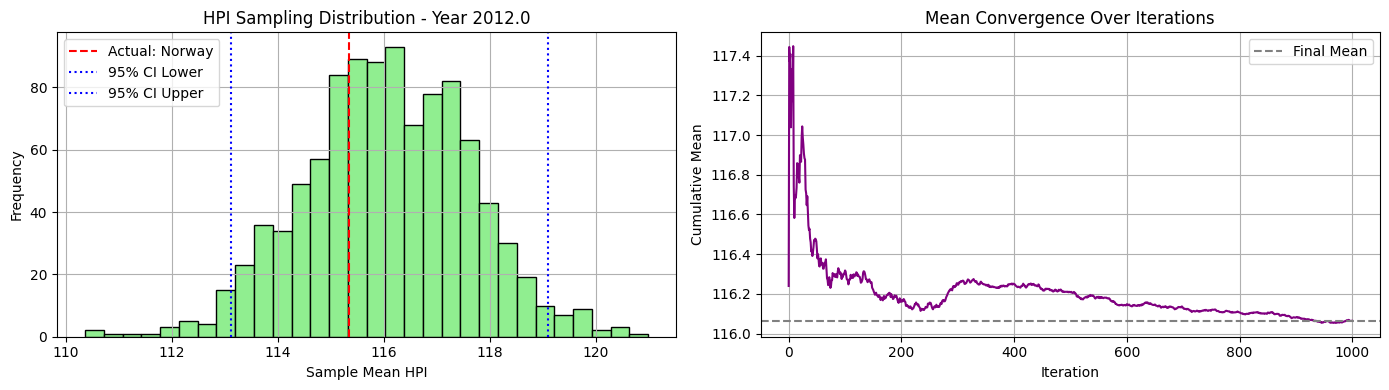

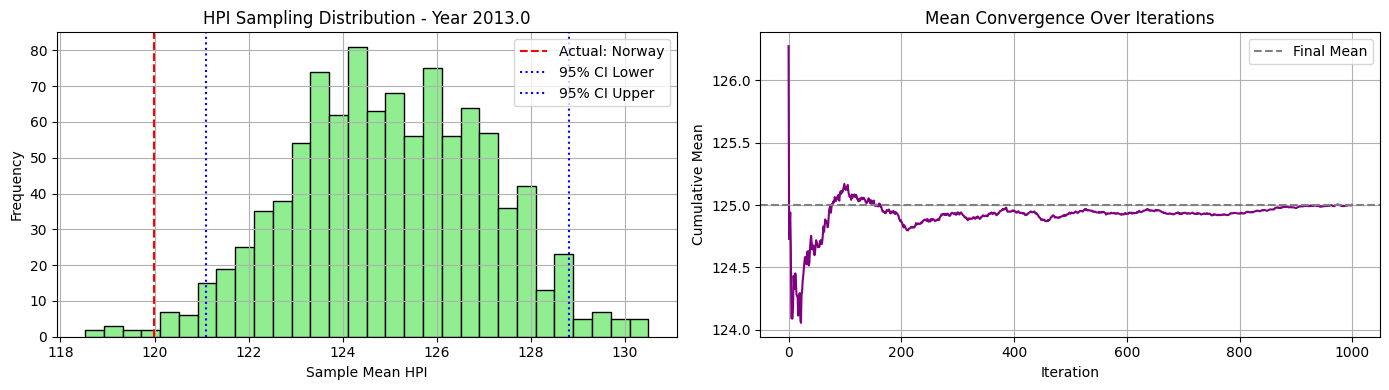

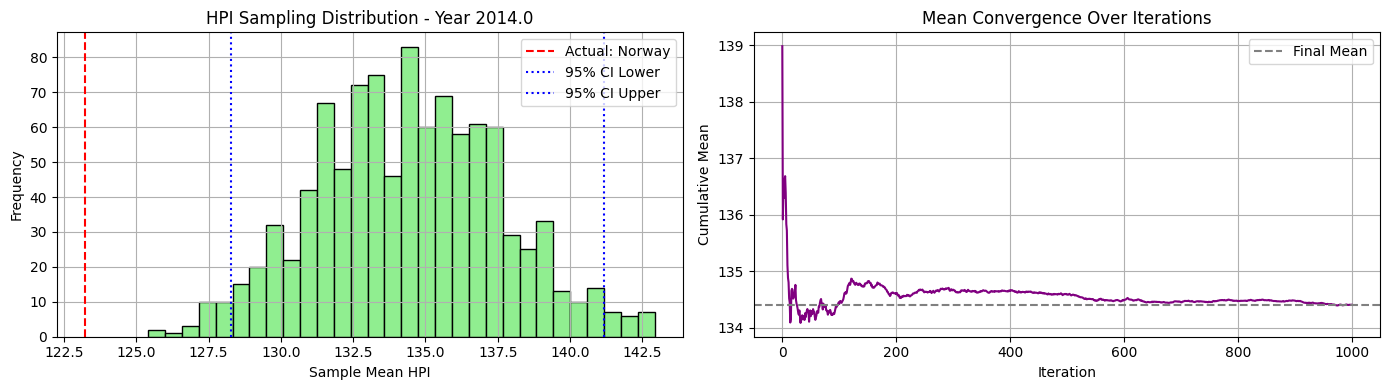

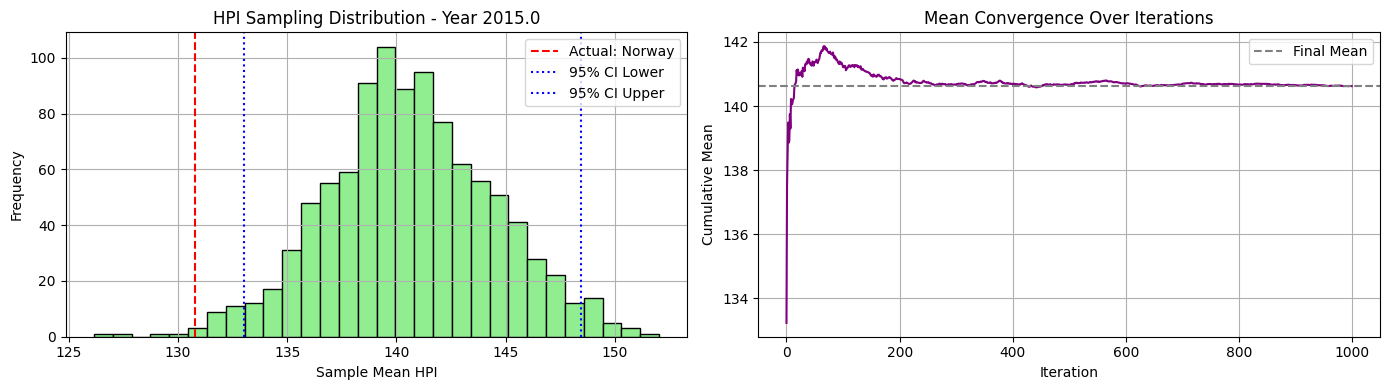

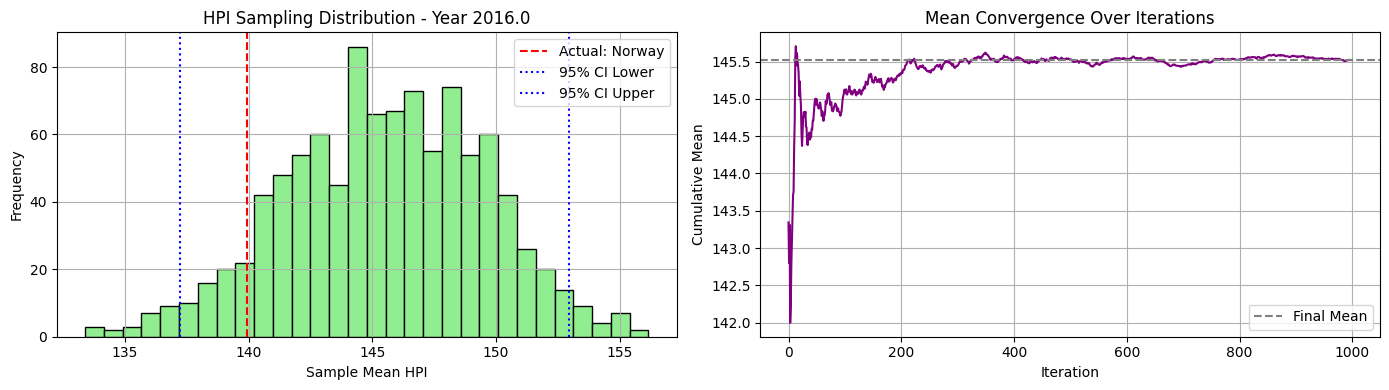

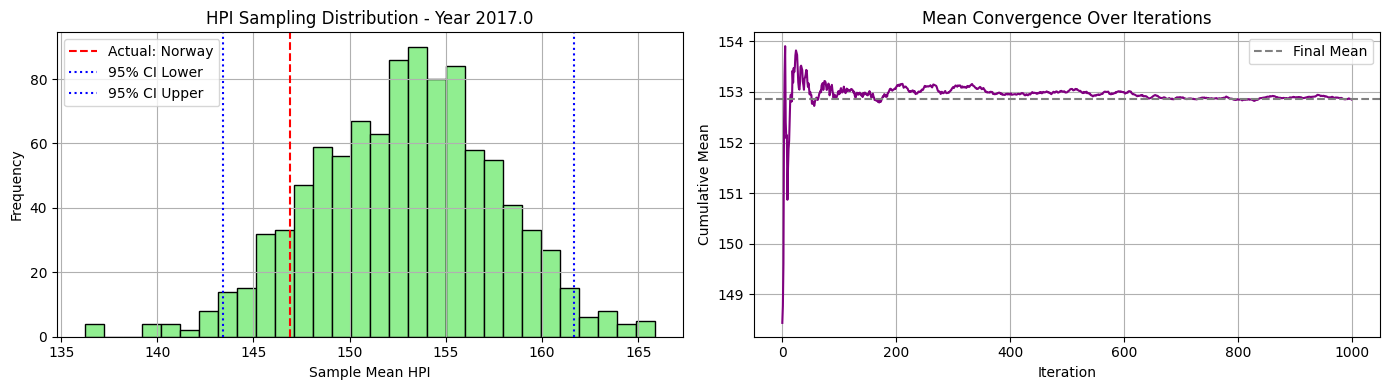

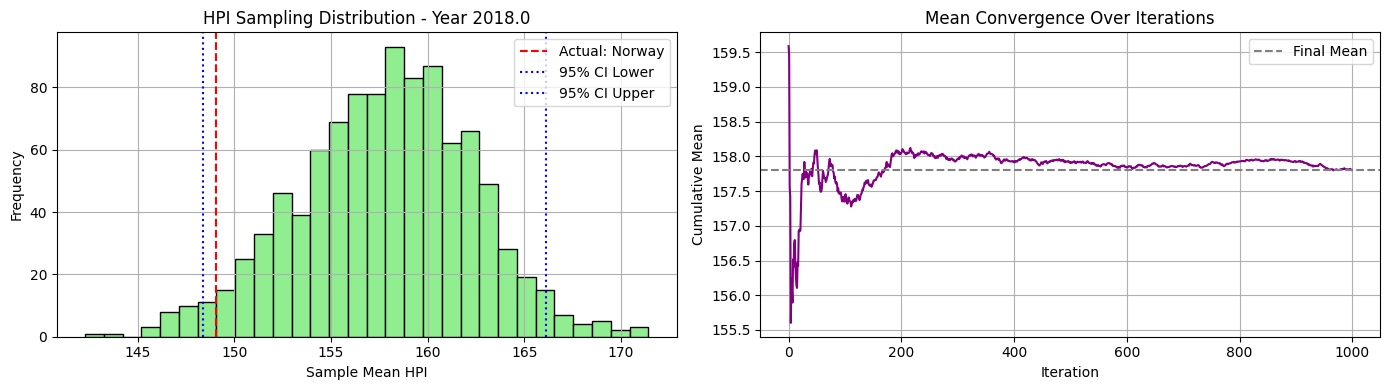

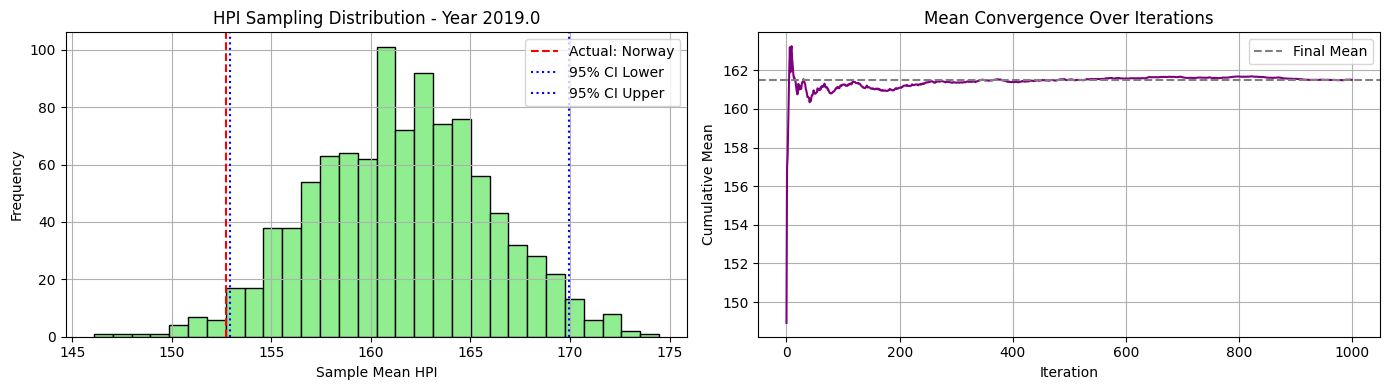

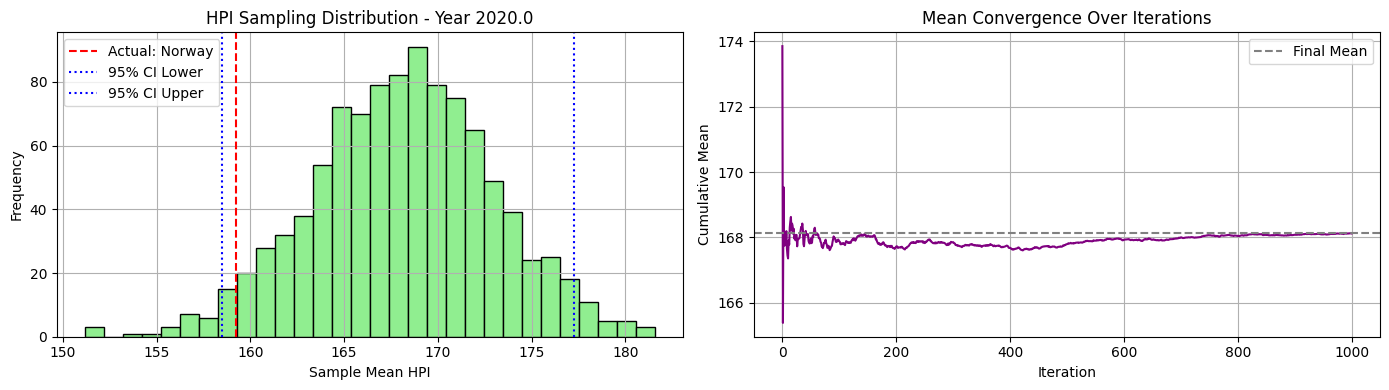

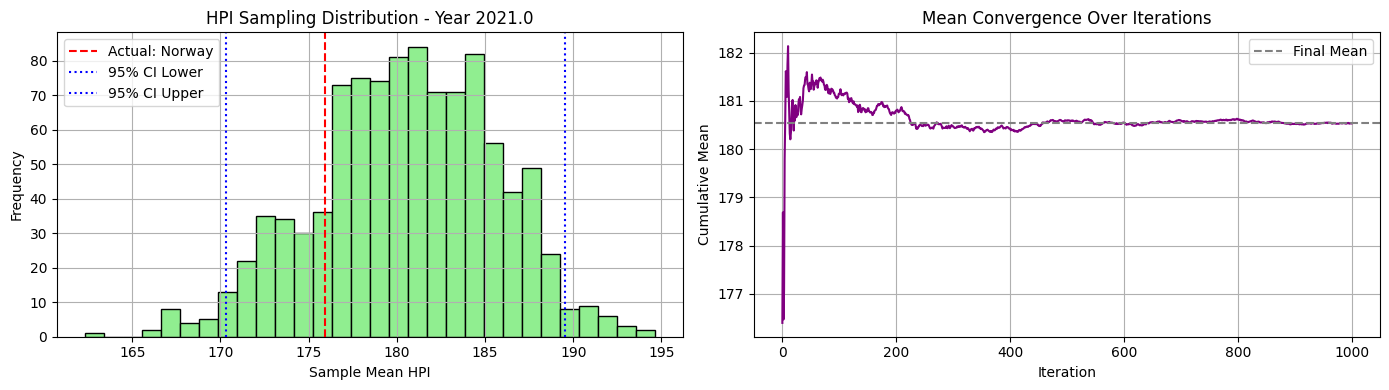

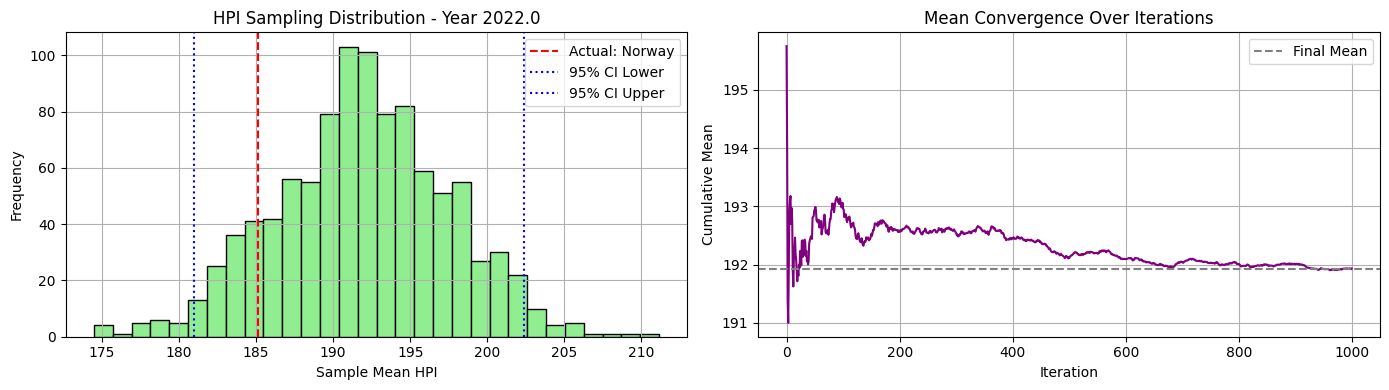

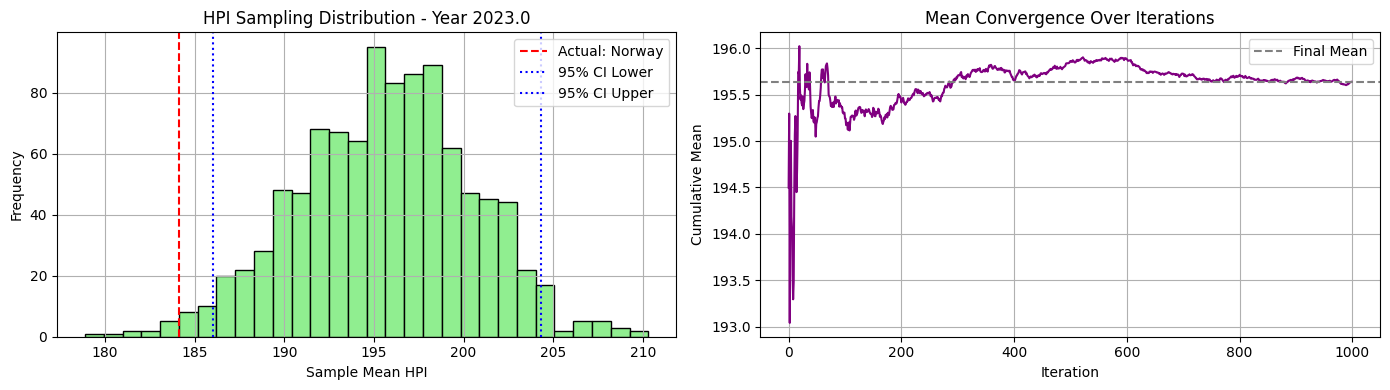

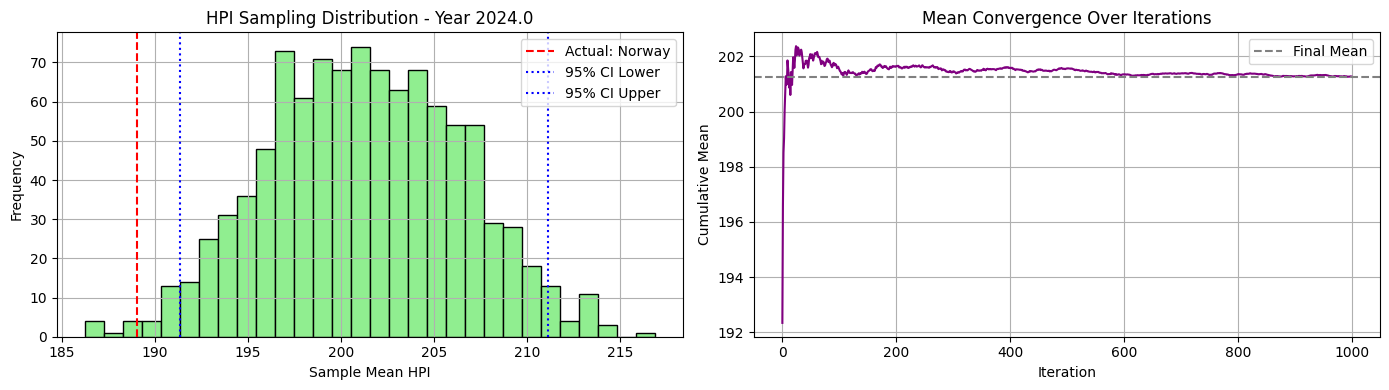

In [50]:
avg_mse_05_6, avg_mae_05_6, best_country_05_6, yearly_bootstrap_means_05_6, yearly_mean_05_6 = evaluate_cluster_sampling_errors(df_hpi_winsorized, c6_ni20_maxi500_clusters, cluster_id=5)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [51]:
errors2 = {
    'cluster_0': [avg_mse_00, avg_mae_00],
    'cluster_1': [avg_mse_01, avg_mae_01]
}

errors6 = {
    'cluster_0': [avg_mse_00_6, avg_mae_00_6],
    'cluster_1': [avg_mse_01_6, avg_mae_01_6],
    'cluster_2': [avg_mse_02_6, avg_mae_02_6],
    'cluster_3': [avg_mse_03_6, avg_mae_03_6],
    'cluster_4': [avg_mse_04_6, avg_mae_04_6],
    'cluster_5': [avg_mse_05_6, avg_mae_05_6]
}

In [52]:
# Convertir a DataFrame
df_errors2 = pd.DataFrame.from_dict(errors2, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors2 = df_errors2.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors2)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0     988.2460      21.6054
cluster_1    1192.9236      25.0003


In [53]:
# Convertir a DataFrame
df_errors6 = pd.DataFrame.from_dict(errors6, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors6 = df_errors6.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors6)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0    1432.1208      27.5850
cluster_1    1985.4628      32.1717
cluster_2    4593.7924      51.8188
cluster_3     924.0871      20.3866
cluster_4    1355.0748      26.1864
cluster_5     593.9765      18.2955


In [54]:
variances2 = calculate_hpi_variance_by_cluster(df_hpi_winsorized, c2_ni20_maxi500_clusters)
for cluster_id, var in variances2.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 956.4344
Cluster 1: Avg HPI Variance = 1130.4537


In [55]:
variances6 = calculate_hpi_variance_by_cluster(df_hpi_winsorized, c6_ni20_maxi500_clusters)
for cluster_id, var in variances6.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 1228.1255
Cluster 1: Avg HPI Variance = 1590.7642
Cluster 2: Avg HPI Variance = 3058.8280
Cluster 3: Avg HPI Variance = 871.9466
Cluster 4: Avg HPI Variance = 1230.3589
Cluster 5: Avg HPI Variance = 509.3408


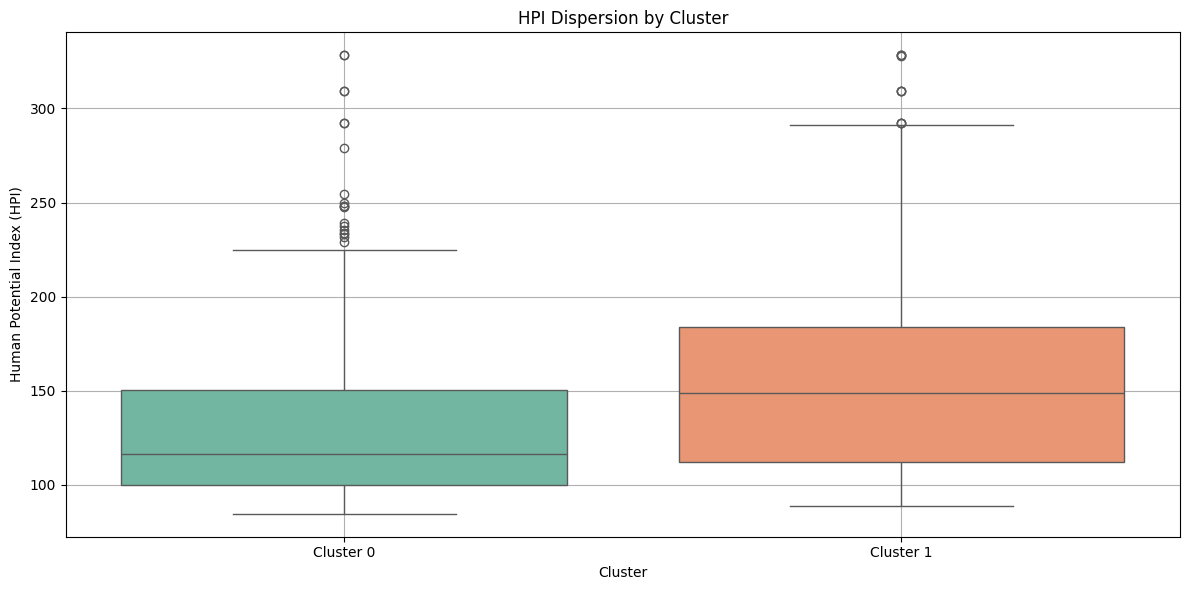

In [56]:
plot_hpi_dispersion_by_cluster(df_hpi_winsorized, c2_ni20_maxi500_clusters)

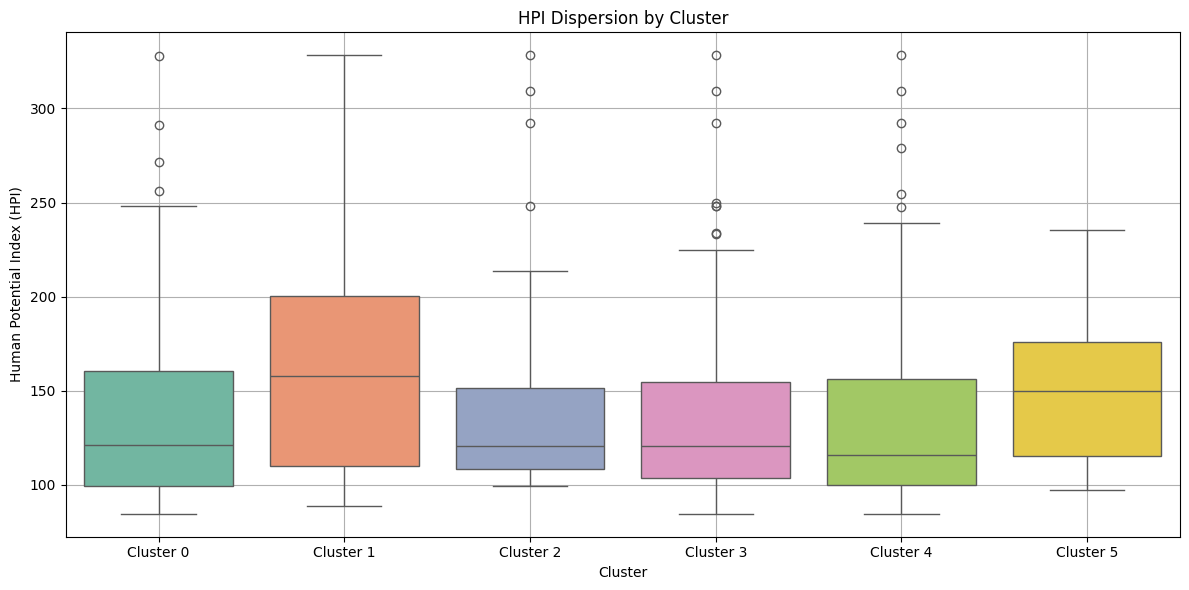

In [57]:
plot_hpi_dispersion_by_cluster(df_hpi_winsorized, c6_ni20_maxi500_clusters)

In [58]:
iqr_points2= percentage_points_within_iqr_by_cluster(df_hpi_winsorized, c2_ni20_maxi500_clusters)
print(iqr_points2)

{np.int32(0): np.float64(53.33), np.int32(1): np.float64(50.88)}


In [59]:
iqr_points6= percentage_points_within_iqr_by_cluster(df_hpi_winsorized, c6_ni20_maxi500_clusters)
print(iqr_points6)

{np.int32(0): np.float64(46.67), np.int32(1): np.float64(76.0), np.int32(2): np.float64(37.78), np.int32(3): np.float64(48.15), np.int32(4): np.float64(49.09), np.int32(5): np.float64(52.38)}


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [60]:
pd.set_option('display.max_columns', None)

In [86]:
log_df = pd.read_parquet('../data/log_performance/new_log_performance.parquet')

In [87]:
new_entry = {
    'experiment_name': 'kmeans_++_2c_pre-coversion_countries_exclude',
    'experiment_date': '2025-09-14 22:15',
    'premacroecon_conversion_transform': 'Winsorization, RobustScaler',
    'countries_used_for_clustering': 53,
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhouette_c2_ni20_maxi500,
    'transformations_clustering': 'Before Winsorization, Before log transformation, After Robust Scaler',
    'outliers_handling_clustering': 'Winsorization x8',
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 53,
    'mse_score': df_errors2['Average MSE'].mean(),
    'mae_score': df_errors2['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_015',
    'pca_ratio_sum': None,
    'pca_ratio_values': None,
    'Variance_Cluster_0': round(float(variances2[0]),2),
    'Variance_Cluster_1': round(float(variances2[1]),2),
    'Variance_Cluster_2': None,
    'Variance_Cluster_3': None,
    'IQR_Count_Cluster_0':int(iqr_points2[0]),
    'IQR_Count_Cluster_1':int(iqr_points2[1]),
    'IQR_Count_Cluster_2': None,
    'IQR_Count_Cluster_3': None   
}

In [88]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)

C:\Users\lucas\AppData\Local\Temp\ipykernel_15800\612794693.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log_df = pd.concat([log_df, pd.DataFrame([new_entry])], ignore_index=True)


In [89]:
new_entry6= {
    'experiment_name': 'kmeans_++_6c_pre-coversion_countries_exclude',
    'experiment_date': '2025-09-14 22:15',
    'premacroecon_conversion_transform': 'Winsorization, RobustScaler',
    'countries_used_for_clustering': 53,
    'clustering_model': 'KMeans',
    'n_clusters': 6,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhouette_c6_ni20_maxi500,
    'transformations_clustering': 'Before Winsorization, Before log transformation, After Robust Scaler',
    'outliers_handling_clustering': 'Winsorization x8',
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization x2, rounding',
    'outliers_handling_sampling': 'Winsorization x2',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 53,
    'mse_score': df_errors6['Average MSE'].mean(),
    'mae_score': df_errors6['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_015',
    'pca_ratio_sum': None,
    'pca_ratio_values': None,
    'Variance_Cluster_0': round(float(variances6[0]),2),
    'Variance_Cluster_1': round(float(variances6[1]),2),
    'Variance_Cluster_2': round(float(variances6[2]),2),
    'Variance_Cluster_3': round(float(variances6[3]),2),
    'IQR_Count_Cluster_0':int(iqr_points6[0]),
    'IQR_Count_Cluster_1':int(iqr_points6[1]),
    'IQR_Count_Cluster_2':int(iqr_points6[2]),
    'IQR_Count_Cluster_3':int(iqr_points6[3])   
}

In [90]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry6])], ignore_index=True)

In [92]:
# Supongamos que quieres eliminar la fila con índice 5
log_df = log_df.drop(index=3)
log_df = log_df.drop(index=4)

# Luego reseteas el índice para que quede consecutivo
log_df = log_df.reset_index(drop=True)

In [93]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,None,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1119.271800,23.643200,hypothesis_test_013,None,None,1177.08,975.18,NaN,NaN,239.0,177.0,NaN,NaN
2,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1146.197900,24.224467,hypothesis_test_013,None,None,1257.22,1050.94,927.59,NaN,128.0,143.0,145.0,NaN
3,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,None,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN
4,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1090.584800,23.302850,hypothesis_test_015,None,None,956.43,1130.45,NaN,NaN,53.0,50.0,NaN,NaN
5,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"Before Winsorization, Before log transformatio...",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,53.0,1814.085733,29.407333,hypothesis_test_015,None,None,1228.13,1590.76,3058.83,871.95,46.0,76.0,37.0,48.0


In [94]:
log_df.to_parquet('../data/log_performance/new_log_performance.parquet')